# pXRF Elemental Mapping and Distribution

## 1. Configuration and Setup

In [17]:
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.ticker as mticker
import math

warnings.filterwarnings('ignore', category=DeprecationWarning)

# Define project paths 
PROJECT_DIR = Path.cwd()  # run the notebook from the folder that contains your 'data' subfolder
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Create output directory if it doesn't exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Input files
CSV_FILE = DATA_DIR / "XRF_Lagunazo_complete_r2.csv"
WASTE_TYPE_FILE = DATA_DIR / "XRF_2024_samples_waste_type.csv"
COORDS_FILE = DATA_DIR / "Lagunazo_UTM.csv"

# Output filenames
OUTPUT_SUMMARY = OUTPUT_DIR / "XRF_Analysis_Summary.txt"
OUTPUT_SLAG = OUTPUT_DIR / "XRF_Concentrations_Slag.png"
OUTPUT_TAILING = OUTPUT_DIR / "XRF_Concentrations_Tailing.png"
OUTPUT_SPATIAL_ALL = OUTPUT_DIR / "XRF_Spatial_Distribution_All.png"
OUTPUT_SPATIAL_SELECTED = OUTPUT_DIR / "XRF_Spatial_Distribution_Selected.png"
OUTPUT_STATISTICS_TABLE = OUTPUT_DIR / "XRF_Statistics.csv"

# Analysis parameters
ELEMENTS = ["Bi", "Co", "Cu", "Hf", "Mn", "Nb", "Ni", "Pd", "Sb", "Sr", "Ta", "Ti", "V", "W", "Y"]
NONDETECT_MODE = "nan"  # Options: "nan" or "half_min"
GROUP_COL = None  # Set to "Sample" to include sample IDs in analysis

# Plotting parameters
COLORBLIND_PALETTE = ['#0072B2', '#D55E00', '#009E73', '#E69F00', '#CC79A7', '#56B4E9']
DPI_SCREEN = 100
DPI_PRINT = 300
DPI_HIGHRES = 600

print("Configuration loaded successfully")
print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")

Configuration loaded successfully
Data directory: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\data
Output directory: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\outputs


## 2. Publication-quality plotting style (OriginPro look)

Configure matplotlib to emulate a figure exported from OriginPro: a clean sans-serif face (Arial where available, otherwise Liberation Sans), a heavy four-sided frame with inward major and minor ticks on all sides, restrained type weights, and 600-dpi output. Maths is rendered with mathtext rather than an external LaTeX install, so the notebook runs anywhere. A few helpers (`style_frame`, `style_log_yaxis`, `add_north_arrow`, `add_scale_bar`) keep the box charts and maps consistent.

In [18]:
import matplotlib as mpl
from matplotlib import font_manager as fm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator,
                               LogLocator, NullFormatter)


def _pick_font():
    avail = {f.name for f in fm.fontManager.ttflist}
    for cand in ("Arial", "Helvetica", "Liberation Sans", "Nimbus Sans", "Arimo"):
        if cand in avail:
            return cand
    return "DejaVu Sans"


ORIGIN_FONT = _pick_font()

# Named palette neutral ink + a colour-blind-aware qualitative set (Okabe-Ito ordered for good adjacent contrast across the 15 elements).
INK        = "#1a1a1a"
INK_SOFT   = "#444444"
GRID_GREY  = "#d9d9d9"
ELEM_PALETTE = [
    "#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7",
    "#56B4E9", "#8C564B", "#7B3294", "#117733", "#AA4499",
    "#44AA99", "#999933", "#882255", "#6699CC", "#661100",
]


def configure_publication_style():
    """Apply the OriginPro/journal look to matplotlib globally."""
    mpl.rcParams.update({
        "font.family": ORIGIN_FONT,
        "mathtext.fontset": "dejavusans",
        "text.usetex": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.titleweight": "regular",
        "axes.labelsize": 12,
        "axes.labelweight": "regular",
        "axes.labelcolor": INK,
        "axes.edgecolor": INK,
        "axes.linewidth": 1.4,
        "text.color": INK,
        "xtick.color": INK, "ytick.color": INK,
        "xtick.labelsize": 10.5, "ytick.labelsize": 10.5,
        "legend.fontsize": 10,
        "legend.frameon": True,
        "legend.edgecolor": INK,
        "legend.framealpha": 1.0,
        "legend.fancybox": False,
        "lines.linewidth": 1.4,
        "lines.markersize": 5,
        "xtick.direction": "in", "ytick.direction": "in",
        "xtick.major.size": 6.0, "ytick.major.size": 6.0,
        "xtick.minor.size": 3.2, "ytick.minor.size": 3.2,
        "xtick.major.width": 1.4, "ytick.major.width": 1.4,
        "xtick.minor.width": 0.9, "ytick.minor.width": 0.9,
        "xtick.minor.visible": True, "ytick.minor.visible": True,
        "xtick.top": True, "ytick.right": True,
        "xtick.major.pad": 5, "ytick.major.pad": 5,
        "axes.xmargin": 0.02, "axes.ymargin": 0.04,
        "figure.facecolor": "white", "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
        "savefig.dpi": 600,
        "figure.dpi": 120,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    })


def style_frame(ax, xminor=None, yminor=2):
    """Heavy four-sided frame with inward major+minor ticks (OriginPro look)."""
    for s in ax.spines.values():
        s.set_linewidth(1.4); s.set_color(INK); s.set_visible(True)
    if xminor is not None:
        ax.xaxis.set_minor_locator(AutoMinorLocator(xminor))
    if yminor is not None:
        ax.yaxis.set_minor_locator(AutoMinorLocator(yminor))
    ax.tick_params(which="both", top=True, right=True, direction="in")
    ax.tick_params(which="major", length=6.0, width=1.4)
    ax.tick_params(which="minor", length=3.2, width=0.9)


def style_log_yaxis(ax):
    """Tidy decade major ticks + minor subticks for a log y-axis."""
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10.0))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=tuple(np.arange(2, 10) * 0.1)))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(which="both", top=True, right=True, direction="in")
    ax.tick_params(axis="y", which="major", length=6.0, width=1.4)
    ax.tick_params(axis="y", which="minor", length=3.2, width=0.9)


def add_north_arrow(ax, x=0.88, y=0.92, size=0.11, gap=0.045):
    """North arrow in axis-fraction coords for map panels.

    r4 fix: the arrow head now points up the page, towards north. In r3 the
    arrow was drawn from the 'N' downwards, so its head pointed south.

    (x, y) is the position of the 'N' label; the arrow runs from
    (x, y - gap - size) up to (x, y - gap), with its head just below the 'N'.
    The maps are in UTM zone 29N, so the arrow marks grid north; true north
    differs from it by about 1.1 degrees at Lagunazo.
    """
    ax.annotate("", xy=(x, y - gap), xytext=(x, y - gap - size),
                xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.4,
                                shrinkA=0, shrinkB=0),
                zorder=6)
    ax.text(x, y, "N", transform=ax.transAxes, ha="center", va="center",
            fontsize=10, fontweight="bold", color=INK, zorder=6)


def add_scale_bar(ax, frac=0.28, y=0.07, label_units="m"):
    """Simple scale bar sized to a 'nice' round distance for map panels."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    span = abs(x1 - x0)
    target = span * frac
    mag = 10 ** np.floor(np.log10(target))
    for m in (5, 2, 1):
        if m * mag <= target:
            nice = m * mag
            break
    else:
        nice = mag
    xa = x0 + 0.06 * span
    yb = y0 + y * (y1 - y0)
    ax.plot([xa, xa + nice], [yb, yb], color=INK, lw=2.6,
            solid_capstyle="butt", zorder=6)
    ax.text(xa + nice / 2, yb + 0.022 * (y1 - y0),
            f"{nice:g} {label_units}", ha="center", va="bottom",
            fontsize=8.5, color=INK, zorder=6)


WASTE_LABEL = {"slag": "Slag", "tailing": "Tailings"}

configure_publication_style()
print("Publication-quality plotting style configured (OriginPro look)")

Publication-quality plotting style configured (OriginPro look)


## 3. Data Processing Functions

Core functions for data cleaning, validation, and transformation.

In [19]:
_LOD_TOKEN_RE = re.compile(r"\bLOD\b", re.IGNORECASE)


def normalize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """
    Normalize column names by stripping whitespace.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe
    
    Returns
    -------
    pd.DataFrame
        DataFrame with normalized column names
    """
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def find_element_columns(df: pd.DataFrame, elements: list) -> dict:
    """
    Locate element columns in dataframe using case-insensitive matching.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe with element columns
    elements : list
        List of element symbols to find (e.g., ['Cu', 'Ni'])
    
    Returns
    -------
    dict
        Mapping from element symbol to actual column name in df
    """
    df = normalize_columns(df)
    lower_cols = {c.lower(): c for c in df.columns}
    
    colmap = {}
    for el in elements:
        key = str(el).strip().lower()
        if key in lower_cols:
            colmap[str(el).strip()] = lower_cols[key]
    
    return colmap


def coerce_reliable_numeric(series: pd.Series) -> pd.Series:
    """
    Convert series to numeric, treating LOD and '<' prefixes as non-detects (NA).
    
    Parameters
    ----------
    series : pd.Series
        Input series with mixed numeric and text entries
    
    Returns
    -------
    pd.Series
        Series with numeric values and NaN for non-detects
    """
    s_str = series.astype("string").str.strip()
    mask = s_str.str.startswith("<", na=False) | s_str.str.contains(_LOD_TOKEN_RE, na=False)
    s_str = s_str.mask(mask, pd.NA)
    return pd.to_numeric(s_str, errors="coerce")


def handle_nondetects(series: pd.Series, mode: str) -> pd.Series:
    """
    Handle non-detect values after numeric coercion.
    
    Parameters
    ----------
    series : pd.Series
        Series with numeric values
    mode : str
        'nan': Replace non-detects with NaN
        'half_min': Replace with half of minimum detected value
    
    Returns
    -------
    pd.Series
        Series with handled non-detects
    """
    s = pd.to_numeric(series, errors="coerce")
    
    if mode == "nan":
        return s.where(s > 0, np.nan)
    
    elif mode == "half_min":
        pos = s[s > 0]
        if len(pos) == 0:
            return s.where(s > 0, np.nan)
        half_min = 0.5 * float(pos.min())
        return s.where(s > 0, half_min)
    
    else:
        raise ValueError(f"Invalid nondetect_mode: {mode}. Must be 'nan' or 'half_min'")


def filter_samples_all_lod(df: pd.DataFrame, element_cols: list) -> tuple:
    """
    Remove samples where all analyzed elements are below LOD.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe
    element_cols : list
        Column names of elements to check
    
    Returns
    -------
    tuple
        (filtered_dataframe, number_of_rows_dropped)
    """
    tmp = df[element_cols].copy()
    for c in element_cols:
        tmp[c] = handle_nondetects(coerce_reliable_numeric(tmp[c]), mode="nan")
    
    drop_mask = tmp.isna().all(axis=1)
    return df.loc[~drop_mask].copy(), int(drop_mask.sum())


def to_long_format(df: pd.DataFrame, elements: list, group_col: str = None) -> tuple:
    """
    Convert XRF data to long format for plotting and analysis.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input XRF dataframe
    elements : list
        List of element symbols to extract
    group_col : str, optional
        Column name for grouping (e.g., 'Sample', 'waste_type')
    
    Returns
    -------
    tuple
        (long_format_df, used_group_col, n_dropped, n_total, n_kept)
    """
    df = normalize_columns(df)
    
    # Find element columns
    colmap = find_element_columns(df, elements)
    if not colmap:
        raise ValueError("No element columns found in dataframe.")
    
    present_cols = list(colmap.values())
    
    # Filter out samples with all non-detects
    df_filt, n_dropped = filter_samples_all_lod(df, present_cols)
    
    # Convert to numeric
    base = df_filt[present_cols].copy()
    for col in base.columns:
        base[col] = handle_nondetects(
            coerce_reliable_numeric(base[col]), 
            mode=NONDETECT_MODE
        )
    
    # Rename columns to canonical element symbols
    inv = {v: k for k, v in colmap.items()}
    base = base.rename(columns=inv)
    
    # Handle grouping column
    used_group_col = None
    if group_col and group_col in df_filt.columns:
        used_group_col = group_col
        base[used_group_col] = df_filt[group_col].astype("string")
        long = base.melt(id_vars=[used_group_col], var_name="Element", value_name="ppm")
    else:
        long = base.melt(var_name="Element", value_name="ppm")
    
    # Drop NaN values
    long = long.dropna(subset=["ppm"])
    
    return long, used_group_col, n_dropped, len(df), len(df_filt)


def standardize_waste_type(type_value) -> str:
    """
    Standardize waste type values to canonical labels.
    
    Parameters
    ----------
    type_value : str or similar
        Raw waste type value
    
    Returns
    -------
    str or None
        'slag', 'tailing', or None if unknown
    """
    if pd.isna(type_value):
        return None
    
    s = str(type_value).strip().lower()
    
    if "slag" in s:
        return "slag"
    if "tail" in s:
        return "tailing"
    
    return None


print("Data processing functions loaded")

Data processing functions loaded


## 4. Visualization functions (OriginPro box charts and maps)

Two figure builders in the OriginPro idiom. The box chart shows, per element, the inter-quartile box, the median line, the mean as an open square, whiskers to 1.5×IQR, outliers as open diamonds, and the raw values overlaid as faint jittered points, on a log concentration axis with sample counts under each box. The spatial map draws one square, black-framed panel per element with a graduated colour scale (log where the range is wide), a compact ppm colour bar, a north arrow, a scale bar, and UTM eastings/northings.

In [20]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm
import math


def _elem_color(i):
    return ELEM_PALETTE[i % len(ELEM_PALETTE)]


def plot_boxplot_single(ax, long_df, elements_order, title="",
                        show_points=True, show_annotations=False, palette=None):
    """OriginPro-style box chart of elemental concentrations (log y-axis).

    For each element the box spans the inter-quartile range, the central line is
    the median, an open square marks the mean, whiskers reach 1.5x IQR, outliers
    are open diamonds, and the raw values are overlaid as faint jittered points
    (the 'data + box' OriginPro style).  Sample counts are printed under each
    box.
    """
    palette = palette or ELEM_PALETTE
    data = [np.asarray(long_df.loc[long_df["Element"] == el, "ppm"].dropna(), float)
            for el in elements_order]
    positions = np.arange(1, len(elements_order) + 1)

    bp = ax.boxplot(
        data, positions=positions, widths=0.62, patch_artist=True,
        showfliers=True, showmeans=True, meanline=False, whis=1.5,
        medianprops=dict(color=INK, linewidth=1.6),
        meanprops=dict(marker="s", markerfacecolor="white",
                       markeredgecolor=INK, markersize=5.5, markeredgewidth=1.2),
        flierprops=dict(marker="d", markerfacecolor="none", markersize=4.0,
                        markeredgecolor=INK_SOFT, markeredgewidth=0.7, alpha=0.7),
        whiskerprops=dict(color=INK, linewidth=1.1),
        capprops=dict(color=INK, linewidth=1.1),
        boxprops=dict(linewidth=1.1),
        zorder=3,
    )
    for i, patch in enumerate(bp["boxes"]):
        patch.set_facecolor(_elem_color(i))
        patch.set_edgecolor(INK)
        patch.set_alpha(0.85)

    # Raw-data overlay: light jittered points beside each box.
    if show_points:
        for i, vals in enumerate(data):
            if vals.size == 0:
                continue
            xj = np.random.default_rng(i).normal(positions[i], 0.055, size=vals.size)
            ax.scatter(xj, vals, s=8, facecolor=_elem_color(i), edgecolor="white",
                       linewidths=0.25, alpha=0.45, zorder=2)

    style_log_yaxis(ax)
    style_frame(ax, xminor=None, yminor=None)  # log y handles its own minors
    ax.set_xticks(positions)
    ax.set_xticklabels(elements_order, fontsize=11)
    ax.tick_params(axis="x", which="minor", bottom=False, top=False)

    # n under each element label.
    ymin, _ = ax.get_ylim()
    for i, vals in enumerate(data):
        ax.annotate(f"n={vals.size}", xy=(positions[i], 0), xytext=(0, -22),
                    textcoords="offset points", xycoords=("data", "axes fraction"),
                    ha="center", va="top", fontsize=8.0, color=INK_SOFT)

    ax.set_ylabel(r"Concentration (ppm)", fontsize=12)
    ax.set_xlabel("Element", fontsize=12, labelpad=16)
    ax.set_xlim(0.5, len(elements_order) + 0.5)
    if title:
        ax.set_title(title, fontsize=12.5, pad=8, loc="left")

    # Compact legend explaining the glyphs (OriginPro convention).
    handles = [
        Line2D([0], [0], color=INK, lw=1.6, label="median"),
        Line2D([0], [0], marker="s", color="none", markerfacecolor="white",
               markeredgecolor=INK, markersize=6, markeredgewidth=1.2, label="mean"),
        Line2D([0], [0], marker="d", color="none", markeredgecolor=INK_SOFT,
               markersize=5, label="outlier"),
    ]
    leg = ax.legend(handles=handles, loc="lower right", bbox_to_anchor=(1.0, 1.005),
                    fontsize=9, ncol=3, handletextpad=0.4, columnspacing=1.2,
                    borderpad=0.5, frameon=False)


def _utm_formatter(axis_letter):
    """Compact UTM tick labels: show offset, label axis with the base value."""
    def _fmt(x, pos):
        return f"{x:,.0f}"
    return mticker.FuncFormatter(_fmt)


def plot_spatial_distribution(elements, merged_df, output_path=None, n_cols=4,
                              cmap="turbo"):
    """OriginPro-style discrete spatial maps, one panel per element.

    Each panel is a square, black-framed map with inward ticks, a graduated
    colour scale (per element, log where the range spans orders of magnitude),
    a compact colour bar labelled in ppm, a north arrow and a scale bar, and
    UTM eastings/northings on the axes.
    """
    elems = [el for el in elements if el in merged_df["Element"].unique()]
    n = len(elems)
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.9 * n_cols, 4.1 * n_rows),
                             squeeze=False)

    # Square, shared spatial extent for all panels.
    xmin, xmax = float(merged_df["X"].min()), float(merged_df["X"].max())
    ymin, ymax = float(merged_df["Y"].min()), float(merged_df["Y"].max())
    side = max(xmax - xmin, ymax - ymin)
    cx, cy = (xmin + xmax) / 2.0, (ymin + ymax) / 2.0
    half = side / 2.0 * 1.12

    for idx, el in enumerate(elems):
        r, c = divmod(idx, n_cols)
        ax = axes[r][c]
        sub = merged_df.loc[merged_df["Element"] == el].copy()
        vals = pd.to_numeric(sub["ppm"], errors="coerce").astype(float)
        vmin, vmax = float(np.nanmin(vals)), float(np.nanmax(vals))

        # Per-element scaling: log if the spread is wide, else linear.
        use_log = (vmin > 0) and (vmax / max(vmin, 1e-9) >= 50)
        norm = LogNorm(vmin=max(vmin, 1e-9), vmax=vmax) if use_log else None

        sc = ax.scatter(sub["X"], sub["Y"], c=vals, cmap=cmap, norm=norm,
                        s=58, edgecolor=INK, linewidth=0.5, alpha=0.95,
                        zorder=4)

        ax.set_xlim(cx - half, cx + half)
        ax.set_ylim(cy - half, cy + half)
        ax.set_aspect("equal", adjustable="box")
        style_frame(ax, xminor=2, yminor=2)

        ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
        ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(_utm_formatter("E"))
        ax.yaxis.set_major_formatter(_utm_formatter("N"))
        ax.tick_params(axis="x", labelrotation=0, labelsize=8)
        ax.tick_params(axis="y", labelsize=8)

        ax.set_xlabel("Easting (m)", fontsize=9.5)
        ax.set_ylabel("Northing (m)", fontsize=9.5)
        ax.set_title(f"{el}  (n = {len(sub)})", fontsize=11.5, loc="left", pad=6)

        add_north_arrow(ax)
        add_scale_bar(ax)

        cb = fig.colorbar(sc, ax=ax, shrink=0.86, pad=0.025, aspect=22)
        cb.set_label(("ppm (log)" if use_log else "ppm"), fontsize=9)
        cb.ax.tick_params(labelsize=8, width=1.1, length=3.5)
        cb.outline.set_linewidth(1.1)

    for idx in range(n, n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        axes[r][c].axis("off")

    fig.tight_layout(h_pad=1.6, w_pad=1.2)
    if output_path:
        fig.savefig(output_path, dpi=600, bbox_inches="tight")
        print(f"  -> Saved: {output_path}")
    return fig, axes


print("Visualization functions loaded (OriginPro look)")

Visualization functions loaded (OriginPro look)


## 5. Data Loading and Validation

Load XRF and waste type data with comprehensive validation.

In [21]:
print("Loading data files...")
print()

# Load main XRF dataset
try:
    df = normalize_columns(pd.read_csv(CSV_FILE))
    print(f" XRF data loaded: {CSV_FILE}")
    print(f"  Shape: {df.shape[0]} samples x {df.shape[1]} columns")
except FileNotFoundError:
    raise FileNotFoundError(f"XRF file not found: {CSV_FILE}")

# Load waste type classification
try:
    wdf = normalize_columns(pd.read_csv(WASTE_TYPE_FILE))
    print(f"Waste type data loaded: {WASTE_TYPE_FILE}")
    print(f"  Shape: {wdf.shape[0]} samples × {wdf.shape[1]} columns")
except FileNotFoundError:
    print(f"Waste type file not found: {WASTE_TYPE_FILE}")
    wdf = None

print()

# Validate required columns
print("Validating data structure...")
if "Sample" not in df.columns:
    raise ValueError("XRF file must contain a 'Sample' column.")

if wdf is not None:
    if "Sample" not in wdf.columns:
        raise ValueError("Waste-type file must contain a 'Sample' column.")
    if "Type" not in wdf.columns:
        raise ValueError("Waste-type file must contain a 'Type' column.")

print(" All required columns present")
print()

# Find element columns
colmap = find_element_columns(df, ELEMENTS)
print(f"Found {len(colmap)} of {len(ELEMENTS)} requested elements:")
for el, col in sorted(colmap.items()):
    print(f"  • {el:3s} → '{col}'")

print()

# Clean join keys
df["Sample"] = df["Sample"].astype(str).str.strip()

if wdf is not None:
    wdf["Sample"] = wdf["Sample"].astype(str).str.strip()
    wdf["waste_type"] = wdf["Type"].apply(standardize_waste_type)
    
    # Merge waste type onto XRF
    df_with_waste = df.merge(wdf[["Sample", "waste_type"]], on="Sample", how="left")
    
    # Report merge results
    unknown = df_with_waste["waste_type"].isna().sum()
    if unknown > 0:
        print(f"{unknown} samples with unknown/missing waste type")
    else:
        print(f"Successfully classified all {len(df_with_waste)} samples")
    
    # Summary by waste type
    print()
    print("Sample distribution by waste type:")
    for wtype, count in df_with_waste["waste_type"].value_counts().items():
        print(f"  • {wtype.capitalize():10s}: {count:3d} samples")
else:
    df_with_waste = df
    print("Note: No waste type classification available")

print()
print("Data loading and validation complete")

Loading data files...

 XRF data loaded: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\data\XRF_Lagunazo_complete_r2.csv
  Shape: 284 samples x 87 columns
Waste type data loaded: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\data\XRF_2024_samples_waste_type.csv
  Shape: 91 samples × 3 columns

Validating data structure...
 All required columns present

Found 15 of 15 requested elements:
  • Bi  → 'Bi'
  • Co  → 'Co'
  • Cu  → 'Cu'
  • Hf  → 'Hf'
  • Mn  → 'Mn'
  • Nb  → 'Nb'
  • Ni  → 'Ni'
  • Pd  → 'Pd'
  • Sb  → 'Sb'
  • Sr  → 'Sr'
  • Ta  → 'Ta'
  • Ti  → 'Ti'
  • V   → 'V'
  • W   → 'W'
  • Y   → 'Y'

118 samples with unknown/missing waste type

Sample distribution by waste type:
  • Slag      : 118 samples
  • Tailing   :  63 samples

Data loading and validation complete


## 6. Statistical Summary by Sample Type

Generate comprehensive statistics for slag vs. tailing samples.

In [22]:
print("\n" + "="*70)
print("STATISTICAL SUMMARY BY SAMPLE TYPE")
print("="*70 + "\n")

all_stats = []

for waste_type in ["slag", "tailing"]:
    print(f"\n{waste_type.upper()} SAMPLES")
    print("-" * 70)
    
    df_waste = df_with_waste.loc[df_with_waste["waste_type"] == waste_type].copy()
    
    if df_waste.empty:
        print(f"  No data available for {waste_type} samples")
        continue
    
    long_waste, _, n_dropped, n_total, n_kept = to_long_format(df_waste, ELEMENTS, group_col=None)
    
    print(f"  Total samples: {len(df_waste)}")
    print(f"  Samples with valid data: {n_kept}")
    print(f"  Samples dropped (all non-detects): {n_dropped}")
    print()
    
    elements_present = sorted(long_waste["Element"].unique())
    print(f"  Elements with detectable concentrations: {len(elements_present)}")
    print(f"  {', '.join(elements_present)}")
    print()
    
    # Calculate statistics for each element
    stats_data = []
    
    print(f"  {'Element':<8} {'N':<4} {'Min':<12} {'Q1':<12} {'Median':<12} {'Q3':<12} {'Max':<12} {'Mean':<12}")
    print(f"  {'-'*8} {'-'*4} {'-'*12} {'-'*12} {'-'*12} {'-'*12} {'-'*12} {'-'*12}")
    
    for el in elements_present:
        vals = long_waste.loc[long_waste["Element"] == el, "ppm"].dropna()
        if vals.empty:
            continue
        
        n = len(vals)
        min_v = vals.min()
        q1 = vals.quantile(0.25)
        med = vals.median()
        q3 = vals.quantile(0.75)
        max_v = vals.max()
        mean_v = vals.mean()
        
        print(f"  {el:<8} {n:<4} {min_v:<12.3g} {q1:<12.3g} {med:<12.3g} {q3:<12.3g} {max_v:<12.3g} {mean_v:<12.3g}")
        
        stats_data.append({
            'waste_type': waste_type,
            'element': el,
            'n': n,
            'min': min_v,
            'q1': q1,
            'median': med,
            'q3': q3,
            'max': max_v,
            'mean': mean_v,
            'std': vals.std(),
        })
    
    all_stats.extend(stats_data)

# Save statistics table
stats_df = pd.DataFrame(all_stats)
stats_df.to_csv(OUTPUT_STATISTICS_TABLE, index=False)
print(f"\nStatistics saved to: {OUTPUT_STATISTICS_TABLE}")


STATISTICAL SUMMARY BY SAMPLE TYPE


SLAG SAMPLES
----------------------------------------------------------------------
  Total samples: 118
  Samples with valid data: 118
  Samples dropped (all non-detects): 0

  Elements with detectable concentrations: 15
  Bi, Co, Cu, Hf, Mn, Nb, Ni, Pd, Sb, Sr, Ta, Ti, V, W, Y

  Element  N    Min          Q1           Median       Q3           Max          Mean        
  -------- ---- ------------ ------------ ------------ ------------ ------------ ------------
  Bi       117  8.76         59.8         90.4         147          1.08e+03     137         
  Co       6    69.2         131          166          202          440          196         
  Cu       116  170          349          492          795          3.1e+03      671         
  Hf       2    4.52e+03     4.64e+03     4.75e+03     4.86e+03     4.98e+03     4.75e+03    
  Mn       87   36.1         62.7         88.2         118          1.09e+03     125         
  Nb       115  2.99   

## 7. Boxplot Analysis: Concentration Distribution by Sample Type

Generate publication-quality boxplots for slag and tailing samples.


GENERATING BOXPLOTS

Processing slag samples...
  Saved: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\outputs\XRF_Concentrations_Slag.png
    - Samples: 118 kept, 0 dropped
    - Elements: 15
Processing tailing samples...
  Saved: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\outputs\XRF_Concentrations_Tailing.png
    - Samples: 60 kept, 3 dropped
    - Elements: 15


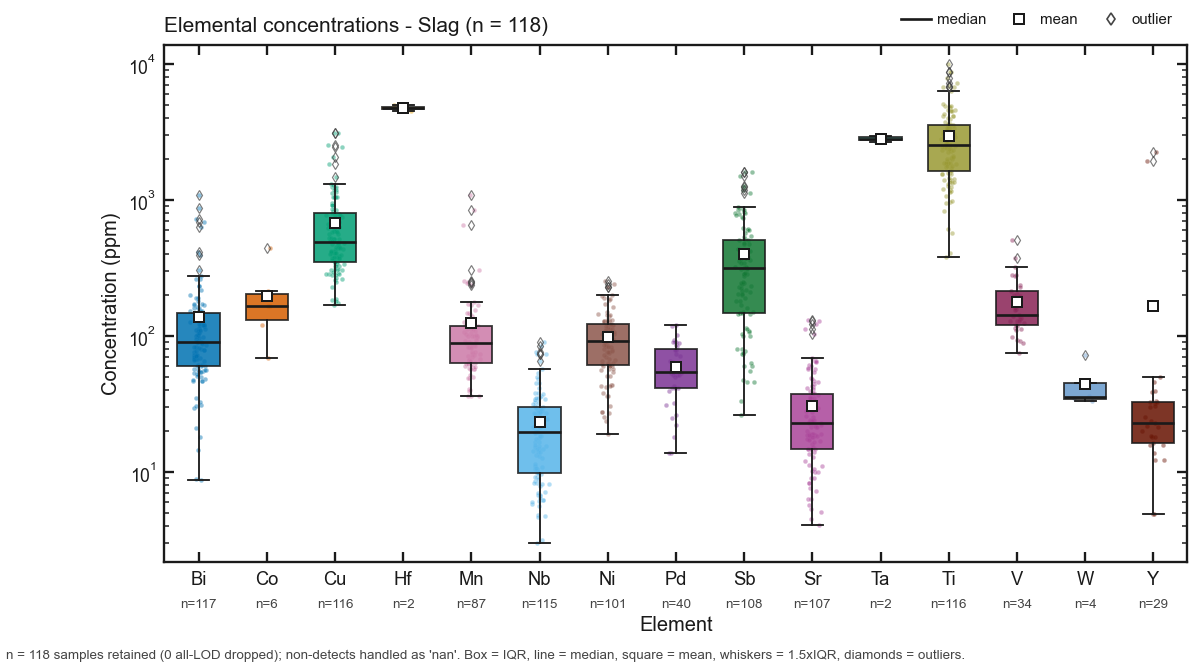

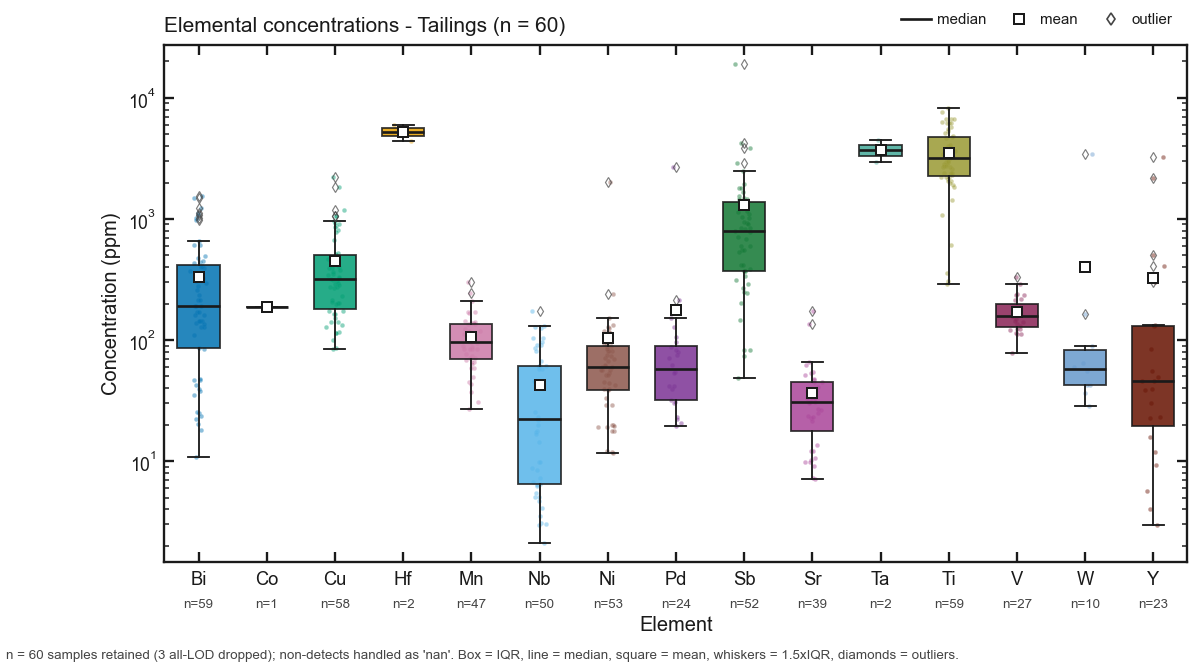


Boxplot generation complete


In [23]:
print("\n" + "="*70)
print("GENERATING BOXPLOTS")
print("="*70 + "\n")

outputs_boxplot = {"slag": OUTPUT_SLAG, "tailing": OUTPUT_TAILING}
boxplot_figs = {}

for waste_type, outpath in outputs_boxplot.items():
    print(f"Processing {waste_type} samples...")

    df_waste = df_with_waste.loc[df_with_waste["waste_type"] == waste_type].copy()
    if df_waste.empty:
        print(f"  No data for {waste_type}")
        continue

    long_waste, _, n_dropped, n_total, n_kept = to_long_format(df_waste, ELEMENTS, group_col=None)
    elements_present = [el for el in ELEMENTS if el in long_waste["Element"].unique()]
    if not elements_present:
        print(f"  No plottable elements for {waste_type}")
        continue

    fig, ax = plt.subplots(figsize=(11, 5.6))
    plot_boxplot_single(
        ax, long_waste, elements_present,
        title=f"Elemental concentrations - {WASTE_LABEL[waste_type]} (n = {n_kept})",
    )
    # Clean source note under the axis instead of a coloured box.
    fig.text(0.005, -0.02,
             f"n = {n_kept} samples retained ({n_dropped} all-LOD dropped); "
             f"non-detects handled as '{NONDETECT_MODE}'. Box = IQR, line = median, "
             f"square = mean, whiskers = 1.5xIQR, diamonds = outliers.",
             fontsize=8, color=INK_SOFT, ha="left", va="top")

    fig.savefig(outpath, dpi=DPI_HIGHRES, bbox_inches="tight")
    boxplot_figs[waste_type] = fig
    print(f"  Saved: {outpath}")
    print(f"    - Samples: {n_kept} kept, {n_dropped} dropped")
    print(f"    - Elements: {len(elements_present)}")

plt.show()
print("\nBoxplot generation complete")

## 8. Spatial Distribution Mapping

Create discrete sample location maps with elemental concentration visualization.


SPATIAL DISTRIBUTION ANALYSIS

Coordinate data loaded: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\data\Lagunazo_UTM.csv
  Shape: 87 locations

Coordinate extent:
  X range: 661445.3 - 661929.5 m
  Y range: 4165390.0 - 4165819.4 m

Matched 52 samples with coordinates

Generating spatial distribution maps...
  -> Saved: c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\outputs\XRF_Spatial_Distribution_All.png


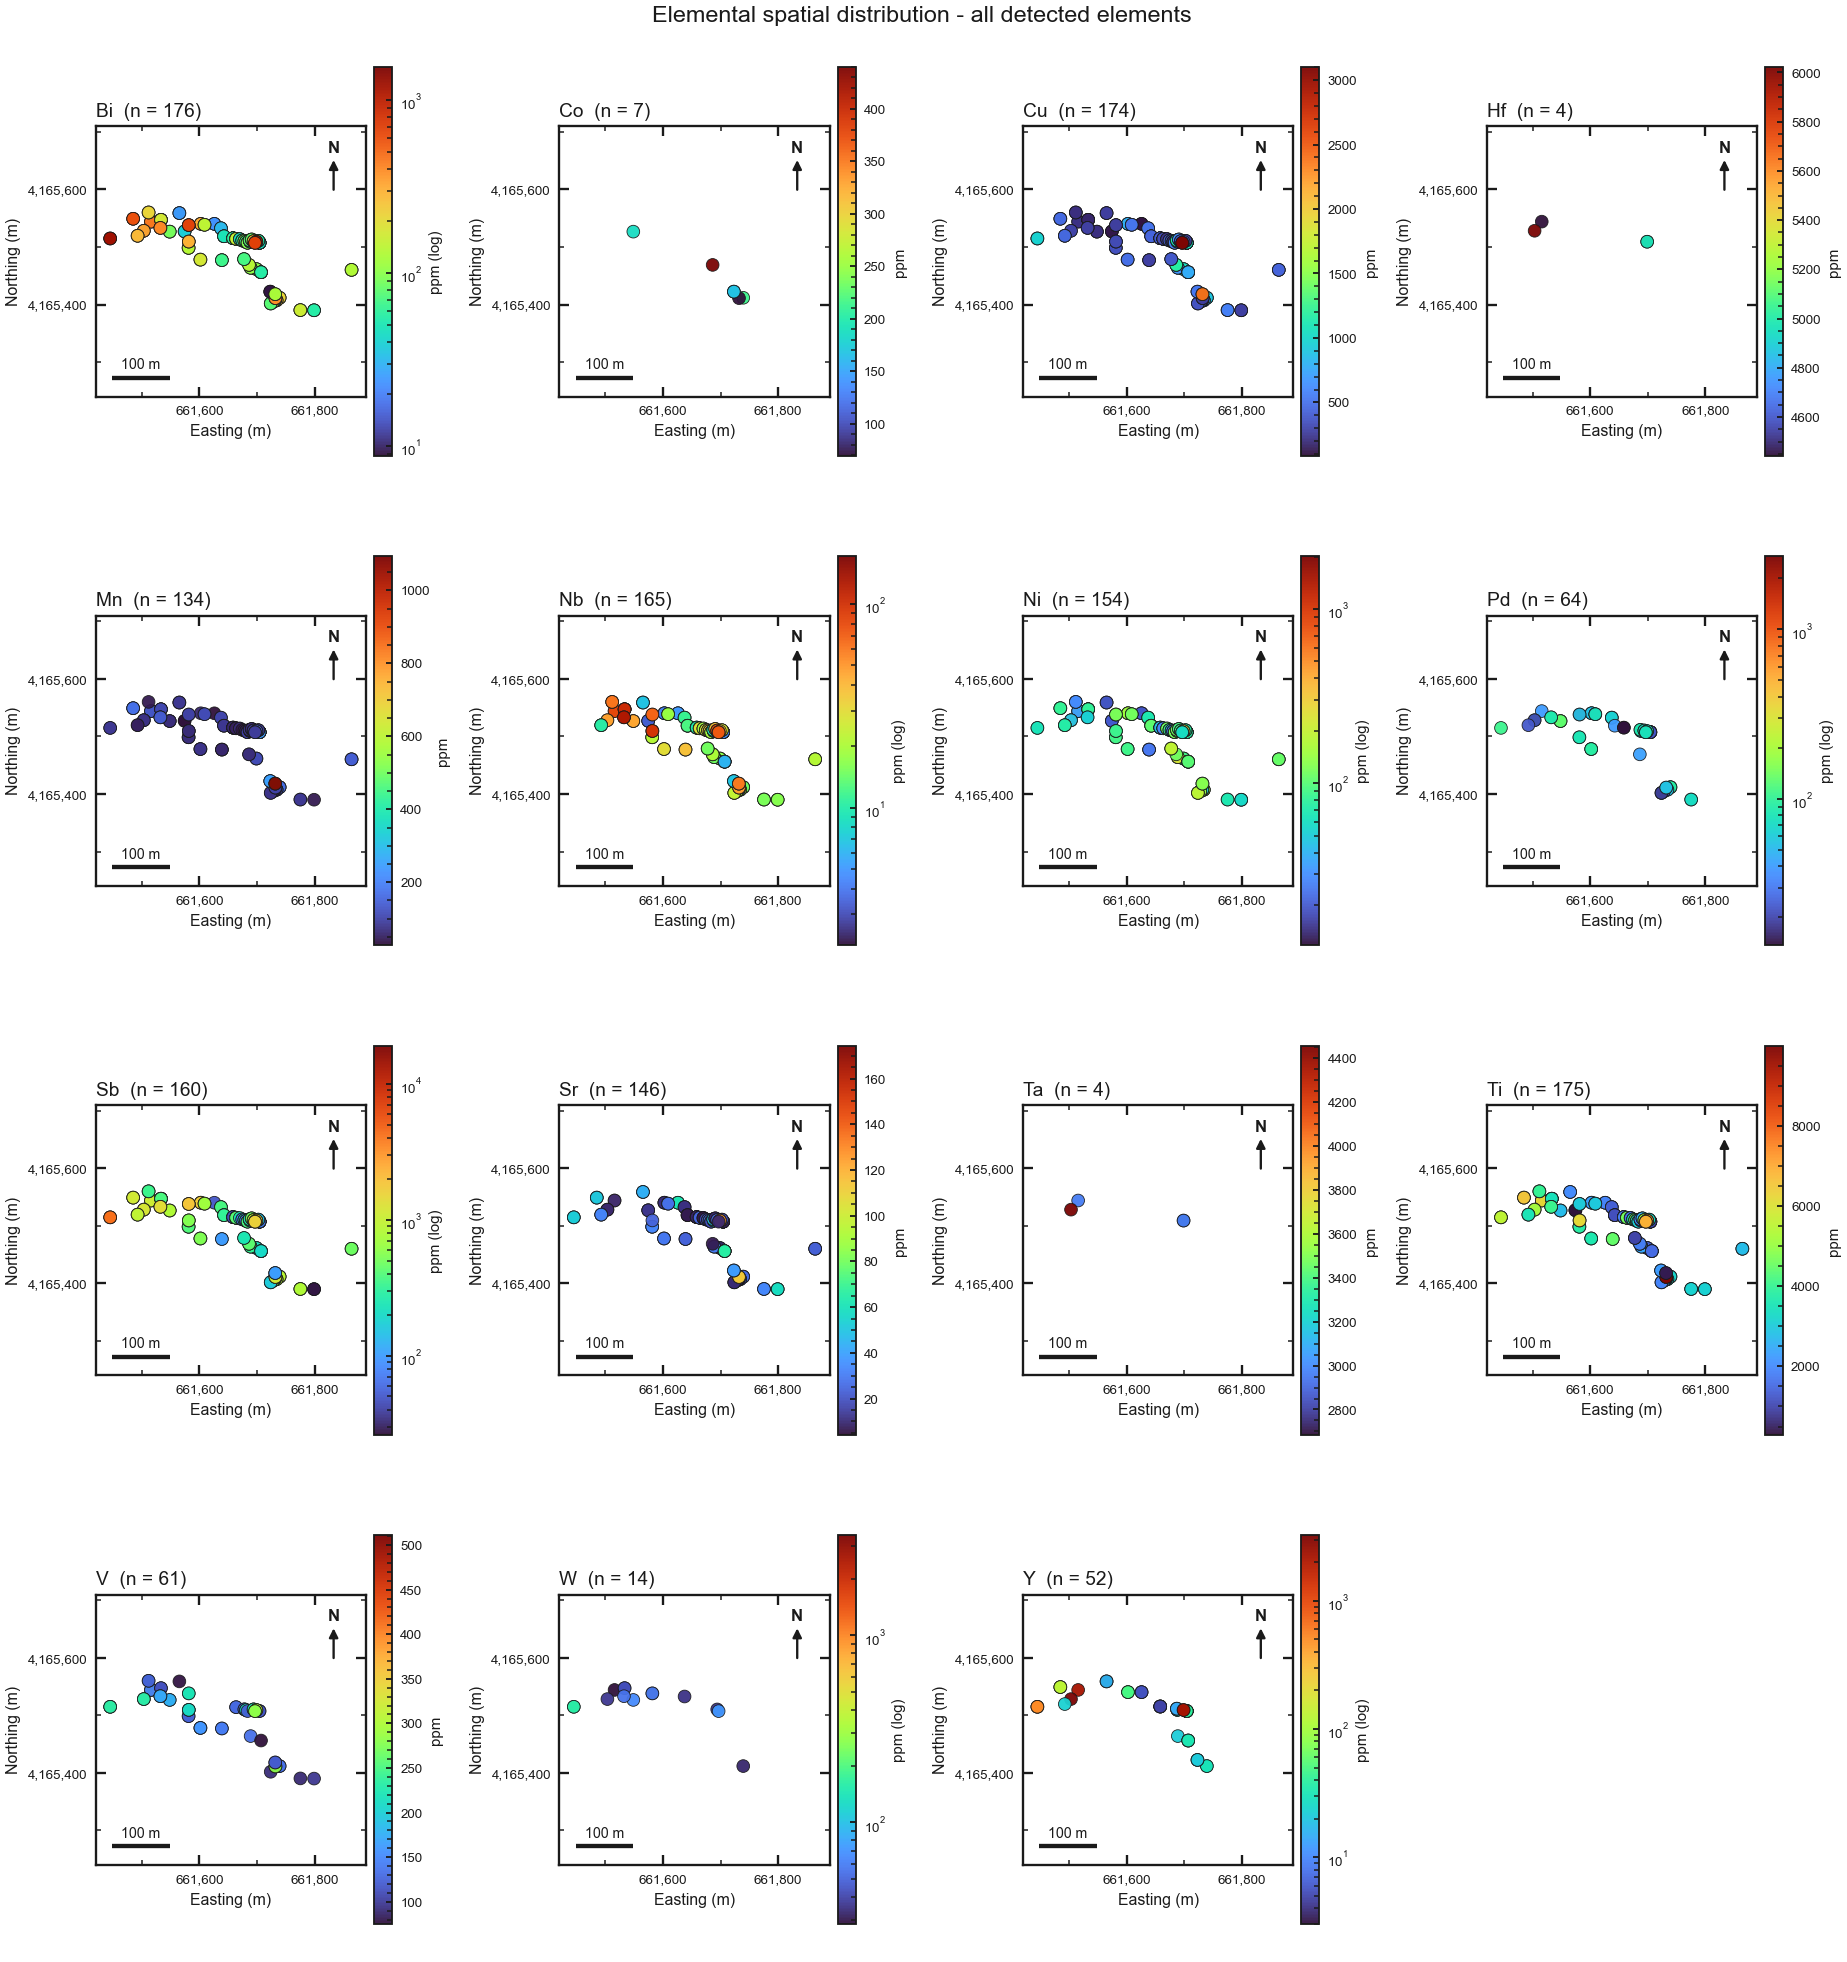

In [24]:
print("\n" + "="*70)
print("SPATIAL DISTRIBUTION ANALYSIS")
print("="*70 + "\n")

# Load coordinate data
try:
    coords = pd.read_csv(COORDS_FILE)
    coords = normalize_columns(coords)
    print(f"Coordinate data loaded: {COORDS_FILE}")
    print(f"  Shape: {coords.shape[0]} locations")
except FileNotFoundError:
    print(f"Coordinate file not found: {COORDS_FILE}")
    print("  Skipping spatial distribution analysis")
    coords = None

if coords is not None:
    # Validate coordinate columns
    required_cols = {"ID", "X", "Y"}
    if not required_cols.issubset(coords.columns):
        raise ValueError(f"Coordinate file must contain columns: {required_cols}")
    
    print()
    print(f"Coordinate extent:")
    print(f"  X range: {coords['X'].min():.1f} - {coords['X'].max():.1f} m")
    print(f"  Y range: {coords['Y'].min():.1f} - {coords['Y'].max():.1f} m")
    print()
    
    # Prepare long-format data with sample IDs
    long_with_ids, used_group_col, _, _, _ = to_long_format(df_with_waste, ELEMENTS, group_col="Sample")
    
    # Merge with coordinates
    merged = long_with_ids.merge(coords, left_on="Sample", right_on="ID", how="inner")
    
    if merged.empty:
        print("No matching sample IDs between chemistry and coordinates")
    else:
        print(f"Matched {merged['Sample'].nunique()} samples with coordinates")
        print()
        
        # Generate spatial map for all elements
        print("Generating spatial distribution maps...")
        elements_plot = [el for el in ELEMENTS if el in merged["Element"].unique()]
        
        fig, axes = plot_spatial_distribution(
            elements_plot, merged, 
            output_path=OUTPUT_SPATIAL_ALL,
            n_cols=4
        )
        fig.suptitle("Elemental spatial distribution - all detected elements",
                     fontsize=14, y=1.005)
        plt.show()


## 9. Data Quality Report

Generate comprehensive QA/QC summary.

In [25]:
print("\n" + "="*70)
print("DATA QUALITY ASSURANCE REPORT")
print("="*70 + "\n")

qa_report = []
qa_report.append(f"XRF Analysis Quality Assurance Report")
qa_report.append(f"Generated: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")
qa_report.append("")
qa_report.append("="*70)
qa_report.append("1. DATA SUMMARY")
qa_report.append("="*70)
qa_report.append(f"Total samples analyzed: {len(df)}")
qa_report.append(f"Total measurements: {df.shape[1] - 1}")  # Exclude Sample column
qa_report.append(f"Analysis parameters:")
qa_report.append(f"  - Non-detect mode: {NONDETECT_MODE}")
qa_report.append(f"  - Elements targeted: {', '.join(ELEMENTS)}")
qa_report.append("")

qa_report.append("="*70)
qa_report.append("2. ELEMENT DETECTION SUMMARY")
qa_report.append("="*70)

for waste_type in ["slag", "tailing"]:
    df_waste = df_with_waste.loc[df_with_waste["waste_type"] == waste_type].copy()
    if df_waste.empty:
        continue
    
    long_waste, _, n_dropped, n_total, n_kept = to_long_format(df_waste, ELEMENTS, group_col=None)
    
    qa_report.append(f"\n{waste_type.upper()} SAMPLES:")
    qa_report.append(f"  Total samples: {len(df_waste)}")
    qa_report.append(f"  Valid data: {n_kept} ({100*n_kept/len(df_waste):.1f}%)")
    qa_report.append(f"  All LOD samples: {n_dropped}")
    qa_report.append(f"  Detected elements: {len(long_waste['Element'].unique())}")
    
    # Detection frequency
    for el in sorted(long_waste["Element"].unique()):
        detected = long_waste[long_waste["Element"] == el].shape[0]
        freq = 100 * detected / len(df_waste)
        qa_report.append(f"    {el}: {detected}/{len(df_waste)} samples ({freq:.1f}%)")

qa_report.append("")
qa_report.append("="*70)
qa_report.append("3. OUTPUT FILES GENERATED")
qa_report.append("="*70)

output_files = [
    (OUTPUT_SLAG, "Slag sample concentration boxplot"),
    (OUTPUT_TAILING, "Tailing sample concentration boxplot"),
    (OUTPUT_SPATIAL_ALL, "Spatial distribution maps (all elements)"),
    (OUTPUT_STATISTICS_TABLE, "Element statistics table (CSV)"),
]

for fpath, desc in output_files:
    exists = "[x]" if fpath.exists() else "[ ]"
    qa_report.append(f"{exists} {fpath.name:<40} - {desc}")

qa_report.append("")
qa_report.append("="*70)
qa_report.append("4. NOTES")
qa_report.append("="*70)
qa_report.append(f"- Non-detect values: Treated as {NONDETECT_MODE}")
qa_report.append(f"- Spatial data: {'Included' if coords is not None else 'Not available'}")
qa_report.append(f"- Log scale: Applied to all concentration plots")
qa_report.append(f"- Color palette: Okabe-Ito (colorblind-safe)")

# Print and save
for line in qa_report:
    print(line)

with open(OUTPUT_SUMMARY, 'w', encoding='utf-8') as f:
    f.write('\n'.join(qa_report))

print(f"\nQA report saved to: {OUTPUT_SUMMARY}")
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)


DATA QUALITY ASSURANCE REPORT

XRF Analysis Quality Assurance Report
Generated: 2026-09-25 11:31:45

1. DATA SUMMARY
Total samples analyzed: 284
Total measurements: 86
Analysis parameters:
  - Non-detect mode: nan
  - Elements targeted: Bi, Co, Cu, Hf, Mn, Nb, Ni, Pd, Sb, Sr, Ta, Ti, V, W, Y

2. ELEMENT DETECTION SUMMARY

SLAG SAMPLES:
  Total samples: 118
  Valid data: 118 (100.0%)
  All LOD samples: 0
  Detected elements: 15
    Bi: 117/118 samples (99.2%)
    Co: 6/118 samples (5.1%)
    Cu: 116/118 samples (98.3%)
    Hf: 2/118 samples (1.7%)
    Mn: 87/118 samples (73.7%)
    Nb: 115/118 samples (97.5%)
    Ni: 101/118 samples (85.6%)
    Pd: 40/118 samples (33.9%)
    Sb: 108/118 samples (91.5%)
    Sr: 107/118 samples (90.7%)
    Ta: 2/118 samples (1.7%)
    Ti: 116/118 samples (98.3%)
    V: 34/118 samples (28.8%)
    W: 4/118 samples (3.4%)
    Y: 29/118 samples (24.6%)

TAILING SAMPLES:
  Total samples: 63
  Valid data: 60 (95.2%)
  All LOD samples: 3
  Detected elements: 15

## Summary

This notebook provides a comprehensive analysis framework for XRF elemental mapping with:

### Key Features:
- **Robust data handling**: Proper treatment of non-detects (LOD)
- **Publication-quality figures**: Colorblind-safe palettes, proper typography
- **Discrete spatial mapping**: Individual sample location visualization
- **Statistical rigor**: Complete audit trail and QA documentation
- **Reproducibility**: All parameters configurable and documented

### Output Products:
1. **Concentration boxplots** - Distribution by sample type (slag/tailing)
2. **Spatial maps** - Element concentrations at discrete sampling locations
3. **Statistical tables** - Complete descriptive statistics
4. **QA report** - Data validation and processing summary

### Next Steps:
- Adjust paths in Section 1 to your data directory
- Run cells sequentially from top to bottom
- Review OUTPUT_SUMMARY for detailed QA documentation
- Use generated figures for reports and publications

---

# Part B - Deleterious elements, environmental screening and critical-raw-material re-mining potential

*Sections 10–16 are an appendix to the workflow above. They add analysis only: every object created in
Sections 1–9 (`df`, `df_with_waste`, `merged`, `stats_df`, `coords`, the figures and the QA report) is left
untouched, and the helper functions and plotting style defined earlier are re-used. Run Sections 1–9 first, then
these cells in order.*

## 10 · Scope, standards and what this appendix adds

Sections 1–9 describe **what was measured**. This appendix answers the two questions a mine-waste chapter has to
answer next:

1. **How harmful is this material?** Concentrations of the potentially harmful (deleterious) elements, their
   enrichment relative to crustal background, standard contamination and ecological-risk indices, the element
   associations that point to their mineral hosts, and the screening steps still required before any statement
   about risk can be made.
2. **Is there a defensible case for re-mining it for critical raw materials?** Which of the measured elements are
   critical or strategic raw materials under Regulation (EU) 2024/1252, which of them the pXRF data can actually
   support, what grades they reach, which penalty elements would travel with them, and what work programme would
   turn a screening result into a reportable resource.

**Conventions and standards used here**

| Topic | Basis |
|---|---|
| Field-portable XRF practice, interferences, QA | US EPA Method 6200 (field portable XRF for elements in soil and sediment) |
| Censored data (values < LOD) | Detection frequency reported; summary statistics on detected values; substitution only where censoring is low (Helsel, 2012) |
| Background for enrichment indices | Upper continental crust (Rudnick & Gao, 2014), editable in §10 — replace with local unmineralised background if available |
| Contamination indices | Geoaccumulation index *I*<sub>geo</sub> (Müller, 1969); contamination factor and pollution load index (Tomlinson et al., 1980); modified degree of contamination (Abrahim & Parker, 2008) |
| Ecological risk | Potential ecological risk factor and index (Håkanson, 1980) |
| Compositional data | Centred log-ratio transform before PCA (Aitchison, 1986) |
| Soil screening values | Generic reference levels for Andalusia, Decreto 18/2015 (Anexo IV) — **entered by the user in §10**; national framework RD 9/2005 |
| Extractive-waste management | Directive 2006/21/EC; Decision 2009/359/EC (inert waste); Spain: RD 975/2009 |
| Acid generation and leaching | EN 15875 (static acid–base accounting), EN 12457-2 (compliance leaching, L/S 10), sampling framework EN 14899 |
| Critical raw materials | Regulation (EU) 2024/1252 (Critical Raw Materials Act), Annexes I and II; Article 27 obligations on extractive waste |
| Resource reporting | UNFC / CRIRSCO-aligned codes; extractive waste reported as anthropogenic deposits |

**What this appendix deliberately does not do.** It does not declare a soil or a waste "contaminated" or
"hazardous" (that requires a risk assessment against the regional reference levels and a waste classification with
leaching and speciation data), it does not estimate a mineral resource (no tonnage, density, depth control or
laboratory assays here), and it does not convert grades into value. It produces the evidence and the sampling and
testing programme that those steps need.

In [26]:
A_OUT = OUTPUT_DIR 
A_PREFIX = "XRF_PartB" 

# element groups
# Potentially harmful ("deleterious") elements measured by this pXRF configuration.
A_DELETERIOUS = ["As", "Pb", "Hg", "Cd", "Cr", "Co", "Mo", "U"]

# Elements that are critical (CRM) and/or strategic (SRM) raw materials under
# Regulation (EU) 2024/1252, as measured here.  Verify against the consolidated Annexes I and II before quoting in the thesis.
A_CRM_STATUS = {
    "Sb": "CRM", "As": "CRM", "Bi": "CRM + SRM", "Co": "CRM + SRM", "Cu": "CRM + SRM",
    "Hf": "CRM", "Mn": "CRM (battery grade: SRM)", "Nb": "CRM", "Ni": "CRM (battery grade: SRM)",
    "Pd": "CRM + SRM (platinum-group metals)", "Sr": "CRM", "Ta": "CRM", "Ti": "CRM (titanium metal: SRM)",
    "V": "CRM", "W": "CRM + SRM", "Y": "CRM (heavy rare earth elements)",
    # measured but not on the EU lists:
    "Pb": "-", "Zn": "-", "Sn": "-", "Ag": "-", "Cd": "-", "Hg": "-", "Se": "-", "Mo": "-",
    "Fe": "-", "Zr": "-", "Rb": "-", "Th": "-", "U": "-", "Au": "-", "Cr": "-",
}
A_CRM_ELEMENTS = [e for e, s in A_CRM_STATUS.items() if s != "-"]

# All elements to carry through the appendix (measured columns in the XRF file).
A_ELEMENTS = ["Ag", "As", "Au", "Bi", "Cd", "Co", "Cr", "Cu", "Fe", "Hf", "Hg", "Mn", "Mo", "Nb", "Ni",
              "Pb", "Pd", "Rb", "Sb", "Se", "Sn", "Sr", "Ta", "Th", "Ti", "U", "V", "W", "Y", "Zn", "Zr"]

# reference values
# Upper continental crust (Rudnick & Gao, 2014, Treatise on Geochemistry), ppm.
# Replace with a local unmineralised background if you have one - indices are only as good as their reference.
A_UCC = {"Ag": 0.053, "As": 4.8, "Au": 0.0015, "Bi": 0.16, "Cd": 0.09, "Co": 17.3, "Cr": 92, "Cu": 28,
         "Fe": 39200, "Hf": 5.3, "Hg": 0.05, "Mn": 775, "Mo": 1.1, "Nb": 12, "Ni": 47, "Pb": 17,
         "Pd": 0.00052, "Rb": 84, "Sb": 0.4, "Se": 0.09, "Sn": 2.1, "Sr": 320, "Ta": 0.9, "Th": 10.5,
         "Ti": 3800, "U": 2.7, "V": 97, "W": 1.9, "Y": 21, "Zn": 67, "Zr": 193}
A_BACKGROUND_LABEL = "upper continental crust (Rudnick & Gao, 2014)"

# Toxic-response factors for the potential ecological risk index (Hakanson, 1980).
# Elements without an original factor are left out of the index rather than invented.
A_TRF = {"Zn": 1, "Cr": 2, "Cu": 5, "Pb": 5, "Ni": 5, "As": 10, "Cd": 30, "Hg": 40}

# Highest concentration that is geologically credible for this matrix (ppm).
# Values above these are treated as analytical artefacts until a laboratory method confirms them.  Set to None to disable the test for an element.
A_MAX_CREDIBLE = {"Hf": 100, "Ta": 50, "Th": 100, "Au": 20, "Pd": 5, "W": 500, "Y": 500, "U": 100,
                  "Nb": 500, "Ag": 1000, "Re": 5}

# regulatory screening levels (mg/kg)
# Generic reference levels (niveles genericos de referencia) for INDUSTRIAL land
# use, Decreto 18/2015 de Andalucia, Anexo IV.  Enter the official values here;
# every element left as None is simply reported as "not screened".
A_SCREEN_LABEL = "Andalusia generic reference levels, industrial use (Decreto 18/2015, Anexo IV)"
A_SCREEN_LEVELS = {"As": None, "Cd": None, "Co": None, "Cr": None, "Cu": None, "Hg": None,
                   "Mo": None, "Ni": None, "Pb": None, "Se": None, "Sn": None, "Zn": None, "Sb": None}

# indicative grades that would make an element worth following up
# Screening levels only: the grade at which an element in waste is usually
# considered worth a metallurgical test in a polymetallic setting.  They are NOT
# cut-off grades and carry no economic meaning.  Edit freely.
A_CRM_INTEREST = {"Cu": 2000, "Sb": 1000, "Bi": 500, "Co": 500, "Ni": 1000, "W": 500,
                  "V": 1000, "Mn": 5000, "Ti": 20000, "Nb": 200, "Ta": 50, "Hf": 100,
                  "Y": 200, "Sr": 1000, "Pd": 0.5, "As": None}

# Penalty elements: they travel with a concentrate and attract smelter penalties
# or import limits.  Thresholds are contract-specific - these are the values the
# screening flags against and should be replaced with the ones in the relevant
# offtake terms.
A_PENALTY = {"As": 2000, "Sb": 1000, "Hg": 10, "Pb": 10000, "Cd": 500, "Se": 500, "Bi": 500}

# tonnage
A_TONNAGE_T = None          # e.g. 1.2e6 (tonnes of waste in the facility)
A_BULK_DENSITY = None       # e.g. 1.8 (t/m3) - used only if volume is given instead
A_VOLUME_M3 = None          # e.g. 650000

# analysis parameters
A_AGG = "median"            # how replicate readings of one sample are combined
A_MIN_DETECT_A = 70         # % of samples with a detect for reliability class A
A_MIN_DETECT_B = 30         # % for class B
A_MAX_COUNT_RSD_A = 15      # % median counting-statistics RSD for class A
A_MAX_COUNT_RSD_B = 30      # % for class B
A_MAX_REPL_RSD_A = 30       # % median within-sample RSD of replicate readings for class A
A_N_DOMAINS = 4             # geochemical domains (k-means on clr-PCA scores)
A_RANDOM_STATE = 42
A_HALF_LOD = False          # True: substitute LOD/2 for non-detects in summary statistics
A_MIN_INDEX_DETECT = 80     # % detection an element needs to enter the multi-element indices (PLI, mCd, RI)
A_IGEO_FACTOR = 1.5         # matrix-correction factor in the geoaccumulation index (Muller, 1969)

print("Appendix configuration loaded")
print(f"  Deleterious suite      : {', '.join(A_DELETERIOUS)}")
print(f"  CRM/SRM elements measured: {', '.join(A_CRM_ELEMENTS)}")
print(f"  Background reference   : {A_BACKGROUND_LABEL}")
print(f"  Screening levels       : {'entered by user' if any(v is not None for v in A_SCREEN_LEVELS.values()) else 'NOT entered - regulatory screening will be skipped'}")
print(f"  Tonnage                : {'not supplied - contained metal reported per 1,000 t' if not A_TONNAGE_T else f'{A_TONNAGE_T:,.0f} t'}")
print(f"  Outputs                : {A_OUT}")

Appendix configuration loaded
  Deleterious suite      : As, Pb, Hg, Cd, Cr, Co, Mo, U
  CRM/SRM elements measured: Sb, As, Bi, Co, Cu, Hf, Mn, Nb, Ni, Pd, Sr, Ta, Ti, V, W, Y
  Background reference   : upper continental crust (Rudnick & Gao, 2014)
  Screening levels       : NOT entered - regulatory screening will be skipped
  Tonnage                : not supplied - contained metal reported per 1,000 t
  Outputs                : c:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Lagunazo FTIR XRF ICP MS Data\XRF ICP MS Lagunazo\outputs


## 11 · Sample-level dataset and pXRF data quality

Three things have to be settled before any number is interpreted.

**1 · Readings are not samples.** The file holds **284 readings of 87 samples** (3–6 readings each). Statistics on
readings weight heavily-measured samples more than others and understate the true sample-to-sample spread. Here
the readings of one sample are combined (`A_AGG`, median by default) and every later statistic is **per sample**.
The spread between readings of the same sample is kept as a precision measure.

**2 · Sample identifiers differ between the three files.** Chemistry uses `LA_24_7`, the waste-type table uses
`LA-24-7` and the coordinate table uses `LA_2024_7`. The exact-string join of Section 5 therefore matched only the
`LMW`/`MM` series. A normalised key (upper case, separators removed, `LA20xx` → `LA xx`) recovers the rest. Section 5
is left as it is; this appendix uses the normalised join and reports how many samples it recovers.

**3 · A pXRF result is not automatically an analysis.** Each element is classified by the evidence in the file
itself:

* **detection frequency** — in how many samples the element is above the instrument's detection limit;
* **counting precision** — the instrument's own 2σ, expressed as a relative standard deviation (σ/value);
* **repeatability** — the relative standard deviation between the replicate readings of a sample, which also
  contains real sub-sample heterogeneity;
* **plausibility** — whether the concentration is credible for smelter slag and sulphide tailings, using
  `A_MAX_CREDIBLE`, and whether it tracks a major matrix element, which is the signature of a spectral overlap.

The elements are then labelled **A (usable, still confirm by laboratory assay)**, **B (indicative)** or
**C (not defensible)**. Energy-dispersive XRF in a matrix with per-cent-level Pb, As, Cu, Zn and Fe has well-known
line overlaps — As Kα (10.54 keV) on Pb Lα (10.55 keV) is the classic one (US EPA Method 6200) — and the L-lines of
Hf, Ta, W, Au and Th sit on the K-lines of Cu, Zn and the L-lines of Pb and Bi. The diagnostics below are printed
so the classification can be checked rather than believed.

SAMPLE-LEVEL DATASET
----------------------------------------------------------------------
  Readings in file                :   284
  Samples after aggregation (median):    87  (readings per sample: min 3, median 3, max 6)
  Waste type assigned             :    84 of 87 samples (slag: 53, tailing: 31)
  Coordinates assigned            :    84 of 87 samples
  Not in the waste-type table     : LMW13A, LMW23, MM6

  Section 5 joined on the raw strings and classified 181 of 284 readings; the normalised key used here classifies 84 of 87 samples, i.e. the LA-24 series is recovered. Section 5 is unchanged; only this appendix uses the normalised join.


pXRF DATA-QUALITY CLASSIFICATION (sample level)
----------------------------------------------------------------------
         n_samples_detected  detection_pct  counting_RSD_pct  replicate_RSD_pct  median_ppm  enrichment_vs_background reliability_class                                                   concern
element                        

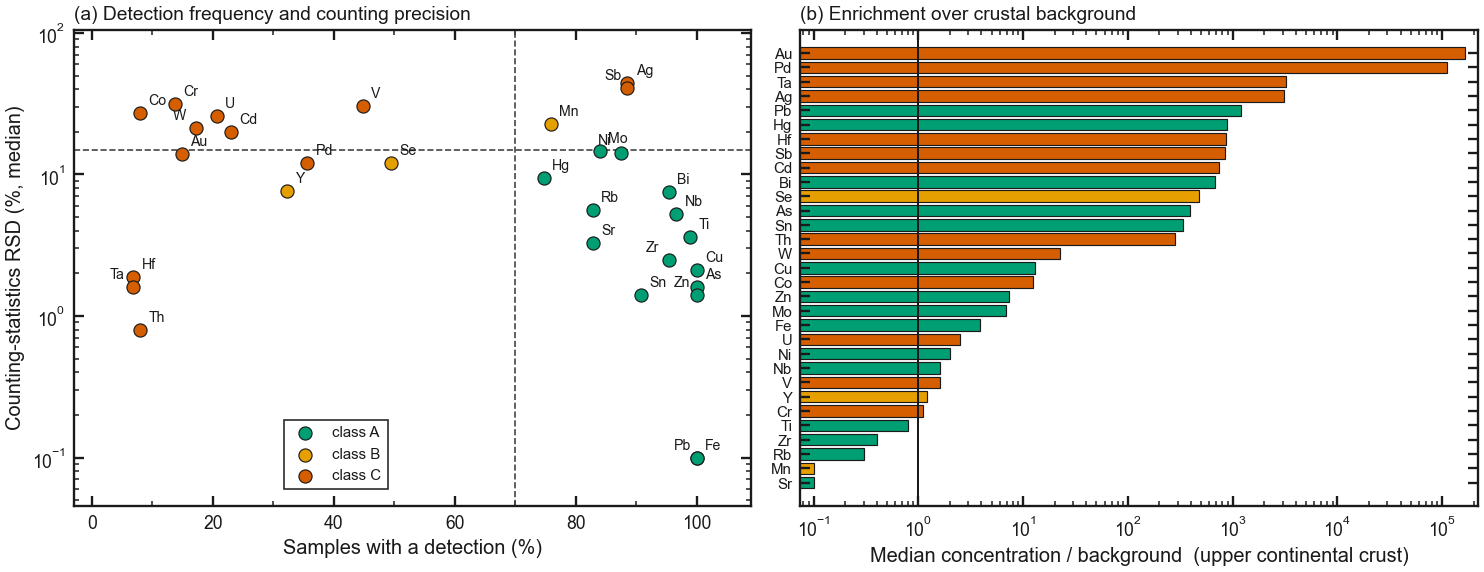


Saved: XRF_PartB_Tab10_element_quality.csv, XRF_PartB_Tab11_sample_level_concentrations.csv, XRF_PartB_Fig10_data_quality.png


In [27]:
import re as _re

def a_key(value) -> str:
    """Normalised sample key: upper case, separators removed, LA20xx -> LAxx."""
    s = str(value).strip().upper().replace(" ", "")
    s = _re.sub(r"[-_/.]", "", s)
    s = _re.sub(r"^LA20(\d\d)", r"LA\1", s)
    return s

def a_numeric(series: pd.Series) -> pd.Series:
    """Detected values only: '<LOD' and '<value' become NaN (re-uses Section 3 logic)."""
    return pd.to_numeric(coerce_reliable_numeric(series), errors="coerce")

# 1. readings -> samples
a_read = normalize_columns(pd.read_csv(CSV_FILE))
a_read["key"] = a_read["Sample"].map(a_key)
a_present = [e for e in A_ELEMENTS if e in a_read.columns]

a_vals = pd.DataFrame({e: a_numeric(a_read[e]) for e in a_present})
a_vals["key"] = a_read["key"].to_numpy()
a_sig = pd.DataFrame({e: a_numeric(a_read[f"{e} 2-Sigma"]) for e in a_present if f"{e} 2-Sigma" in a_read.columns})

a_agg = getattr(a_vals.groupby("key")[a_present], A_AGG)()          # sample-level concentrations
a_nread = a_vals.groupby("key").size().rename("n_readings")
a_ndet = a_vals.groupby("key")[a_present].apply(lambda g: g.notna().sum())

# within-sample repeatability of the replicate readings (per element, %)
a_repl_rsd = (a_vals.groupby("key")[a_present].std() / a_vals.groupby("key")[a_present].mean() * 100.0)

# 2. waste type and coordinates on a normalised key
a_waste = normalize_columns(pd.read_csv(WASTE_TYPE_FILE))
a_waste["key"] = a_waste["Sample"].map(a_key)
a_waste["waste_type"] = a_waste["Type"].apply(standardize_waste_type)
a_wmap = a_waste.dropna(subset=["waste_type"]).drop_duplicates("key").set_index("key")["waste_type"]

a_xy = None
try:
    a_coords = normalize_columns(pd.read_csv(COORDS_FILE))
    a_coords["key"] = a_coords["ID"].map(a_key)
    a_xy = (a_coords.drop_duplicates("key").set_index("key")[["X", "Y"]]
            .rename(columns={"X": "East", "Y": "North"}))          # 'Y' is also yttrium - rename
except FileNotFoundError:
    print("Coordinate file not found - the appendix runs without maps")

SAMPLES = a_agg.copy()
SAMPLES.insert(0, "n_readings", a_nread)
SAMPLES.insert(1, "waste_type", a_wmap.reindex(SAMPLES.index))
if a_xy is not None:
    SAMPLES = SAMPLES.join(a_xy)
SAMPLES.index.name = "sample_key"

a_n_type_before = int(df_with_waste["waste_type"].notna().sum())
a_n_type_after = int(SAMPLES["waste_type"].notna().sum())
print("SAMPLE-LEVEL DATASET")
print("-" * 70)
print(f"  Readings in file                : {len(a_read):>5d}")
print(f"  Samples after aggregation ({A_AGG:<6}): {len(SAMPLES):>5d}  "
      f"(readings per sample: min {int(a_nread.min())}, median {int(a_nread.median())}, max {int(a_nread.max())})")
print(f"  Waste type assigned             : {a_n_type_after:>5d} of {len(SAMPLES)} samples "
      f"({', '.join(f'{k}: {v}' for k, v in SAMPLES['waste_type'].value_counts().items())})")
if a_xy is not None:
    print(f"  Coordinates assigned            : {int(SAMPLES['East'].notna().sum()):>5d} of {len(SAMPLES)} samples")
a_unmatched = sorted(SAMPLES.index[SAMPLES["waste_type"].isna()])
if a_unmatched:
    print(f"  Not in the waste-type table     : {', '.join(a_unmatched)}")
print(f"\n  Section 5 joined on the raw strings and classified {a_n_type_before} of {len(a_read)} readings; the "
      f"normalised key used here classifies {a_n_type_after} of {len(SAMPLES)} samples, i.e. the LA-24 series is "
      "recovered. Section 5 is unchanged; only this appendix uses the normalised join.")

# 3. element-by-element data quality
a_count_rsd = {}
for e in a_present:
    if e in a_sig.columns:
        with np.errstate(divide="ignore", invalid="ignore"):
            a_count_rsd[e] = float(np.nanmedian(((a_sig[e] / 2.0) / a_vals[e]).replace([np.inf, -np.inf], np.nan) * 100))

a_matrix_elements = [e for e in ["Fe", "Pb", "As", "Cu", "Zn", "Bi"] if e in SAMPLES.columns]
a_log = np.log10(SAMPLES[a_present].where(SAMPLES[a_present] > 0))
a_corr_matrix = a_log.corr(method="spearman")

# principal line energies of the suspect elements
A_LINES = pd.DataFrame(
    [("Hf", "L-alpha", 7.90, "Cu K-alpha 8.05, Ni K-beta 8.26"),
     ("Ta", "L-alpha", 8.15, "Cu K-alpha 8.05, Cu K-beta 8.90"),
     ("W",  "L-alpha", 8.40, "Zn K-alpha 8.64, Cu K-beta 8.90"),
     ("Au", "L-alpha", 9.71, "Zn K-beta 9.57, Hg L-alpha 9.99"),
     ("As", "K-alpha", 10.54, "Pb L-alpha 10.55 (classic overlap)"),
     ("Pb", "L-alpha", 10.55, "As K-alpha 10.54"),
     ("Th", "L-alpha", 12.97, "Bi L-beta 13.02, Pb L-beta 12.61"),
     ("U",  "L-alpha", 13.61, "Pb L-beta, Rb K-alpha 13.40"),
     ("Y",  "K-alpha", 14.96, "Pb L-gamma 14.76, Rb K-beta 14.96"),
     ("Nb", "K-alpha", 16.61, "Zr K-beta 17.67, Pb/Bi L-gamma region"),
     ("Pd", "K-alpha", 21.18, "tube anode (Ag/Rh) scatter, Ag K-beta"),
     ("Ag", "K-alpha", 22.16, "tube anode (Ag) characteristic line, Sn/Cd K-lines")],
    columns=["element", "line", "energy_keV", "overlapping_lines_in_this_matrix"]).set_index("element")

# Elements whose principal line falls on the X-ray tube's own anode lines or on the
# scatter peaks beside them.  Ag and Rh are the usual anode materials in handheld
# instruments, so these channels are suspect unless the anode is known to be different.
A_ANODE_SUSPECT = ["Ag", "Pd", "Rh"]

a_qc_rows = []
for e in a_present:
    vals = SAMPLES[e].dropna()
    n_det = int(len(vals))
    det_pct = 100.0 * n_det / len(SAMPLES)
    c_rsd = a_count_rsd.get(e, np.nan)
    r_rsd = float(np.nanmedian(a_repl_rsd[e])) if e in a_repl_rsd else np.nan
    med = float(vals.median()) if n_det else np.nan
    mx = float(vals.max()) if n_det else np.nan
    ef = med / A_UCC[e] if (n_det and A_UCC.get(e)) else np.nan
    cap = A_MAX_CREDIBLE.get(e)
    implausible = bool(cap is not None and n_det and med > cap)
    # strongest correlation with a major matrix element (spectral-overlap diagnostic)
    partners = [(m, a_corr_matrix.loc[e, m]) for m in a_matrix_elements
                if m != e and np.isfinite(a_corr_matrix.loc[e, m])]
    best_m, best_r = max(partners, key=lambda t: abs(t[1])) if partners else ("-", np.nan)

    if implausible:
        cls, why = "C", f"median {med:,.0f} ppm above the credible maximum ({cap:,.0f} ppm) for this matrix"
        concern = "implausible concentration - probable spectral artefact"
    elif det_pct >= A_MIN_DETECT_A and (not np.isfinite(c_rsd) or c_rsd <= A_MAX_COUNT_RSD_A) \
            and (not np.isfinite(r_rsd) or r_rsd <= A_MAX_REPL_RSD_A):
        cls, why, concern = "A", "frequent detection, good counting precision and repeatability", "-"
    elif det_pct >= A_MIN_DETECT_B and (not np.isfinite(c_rsd) or c_rsd <= A_MAX_COUNT_RSD_B):
        cls = "B"
        why = (f"detected in {det_pct:.0f}% of samples" if det_pct < A_MIN_DETECT_A
               else f"counting RSD {c_rsd:.0f}% (> {A_MAX_COUNT_RSD_A}%)")
        concern = "detection frequency" if det_pct < A_MIN_DETECT_A else "counting precision"
    elif det_pct < A_MIN_DETECT_B:
        cls, why = "C", f"detected in only {det_pct:.0f}% of samples (< {A_MIN_DETECT_B}%)"
        concern = "detection frequency"
    else:
        cls, why = "C", f"counting RSD {c_rsd:.0f}% (> {A_MAX_COUNT_RSD_B}%) despite frequent detection"
        concern = "counting precision"
    # Tracking a major element only indicates a LINE OVERLAP when that major element is
    # actually a known interferent for this element's principal line; otherwise a high
    # rank correlation is ordinary geochemistry (e.g. Sb with Bi in sulphosalts).
    a_ovl = A_LINES.loc[e, "overlapping_lines_in_this_matrix"] if e in A_LINES.index else ""
    a_enriched = bool(A_UCC.get(e)) and np.isfinite(med) and med / A_UCC[e] > 50
    if np.isfinite(best_r) and abs(best_r) > 0.8 and e not in a_matrix_elements and a_enriched \
            and best_m in a_ovl:
        why += f"; tracks {best_m} (rho = {best_r:+.2f}), which overlaps its {A_LINES.loc[e, 'line']} line"
        if cls != "A":
            concern = "tracks an overlapping major element - probable spectral artefact"
    elif np.isfinite(best_r) and abs(best_r) > 0.8 and e not in a_matrix_elements and a_enriched:
        why += f"; tracks {best_m} (rho = {best_r:+.2f}) - no line overlap, so this is a geochemical association"
    if e in A_ANODE_SUSPECT and a_enriched and cls != "A":
        concern = "tube-anode / scatter region - probable spectral artefact"
        why += "; principal line sits on the X-ray tube anode region (verify the anode material)"

    a_qc_rows.append({"element": e, "n_samples_detected": n_det, "detection_pct": round(det_pct, 1),
                      "counting_RSD_pct": round(c_rsd, 1) if np.isfinite(c_rsd) else np.nan,
                      "replicate_RSD_pct": round(r_rsd, 1) if np.isfinite(r_rsd) else np.nan,
                      "median_ppm": med, "max_ppm": mx,
                      "enrichment_vs_background": round(ef, 1) if np.isfinite(ef) else np.nan,
                      "max_credible_ppm": cap, "closest_matrix_element": best_m,
                      "rho_with_matrix_element": round(best_r, 2) if np.isfinite(best_r) else np.nan,
                      "reliability_class": cls, "concern": concern, "basis": why})

ELEMENT_QC = pd.DataFrame(a_qc_rows).set_index("element")
A_CLASS_A = [e for e in a_present if ELEMENT_QC.loc[e, "reliability_class"] == "A"]
A_CLASS_B = [e for e in a_present if ELEMENT_QC.loc[e, "reliability_class"] == "B"]
A_CLASS_C = [e for e in a_present if ELEMENT_QC.loc[e, "reliability_class"] == "C"]
A_USABLE = A_CLASS_A + A_CLASS_B
# Two very different reasons to reject an element, which must not be conflated in the write-up.
A_ARTEFACT = [e for e in A_CLASS_C if "artefact" in ELEMENT_QC.loc[e, "concern"]
              or "overlap" in ELEMENT_QC.loc[e, "concern"]]
A_IMPRECISE = [e for e in A_CLASS_C if e not in A_ARTEFACT]

print("\n\npXRF DATA-QUALITY CLASSIFICATION (sample level)")
print("-" * 70)
with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(ELEMENT_QC[["n_samples_detected", "detection_pct", "counting_RSD_pct", "replicate_RSD_pct",
                      "median_ppm", "enrichment_vs_background", "reliability_class", "concern"]]
          .sort_values(["reliability_class", "detection_pct"], ascending=[True, False])
          .round(1).to_string())
print(f"\n  Class A (usable, confirm by laboratory assay): {', '.join(A_CLASS_A) or 'none'}")
print(f"  Class B (indicative only)                   : {', '.join(A_CLASS_B) or 'none'}")
print(f"  Class C (not defensible without laboratory) : {', '.join(A_CLASS_C) or 'none'}")
print("\n  Class C has two very different causes and the write-up must keep them apart:")
print(f"    (i)  probable analytical artefact : {', '.join(A_ARTEFACT) or 'none'}")
print("         concentrations that are not geologically credible for this matrix and/or that track a major")
print("         element sitting on the same line. Laboratory work is expected to REMOVE these values.")
print(f"    (ii) real but imprecise           : {', '.join(A_IMPRECISE) or 'none'}")
print("         plausible for a polymetallic sulphide residue, but measured too close to the detection limit")
print("         or in too few samples to quantify here. Laboratory work is expected to CONFIRM these values.")
a_expected = [e for e in ["Sb", "Co", "Cd", "Ag", "Se", "Cr"] if e in A_IMPRECISE]
if a_expected:
    print(f"         {', '.join(a_expected)} in particular are geologically expected in Iberian Pyrite Belt")
    print("         material (antimony in the tetrahedrite-tennantite group, cobalt and cadmium in the")
    print("         sulphides) and should be on the laboratory schedule rather than dropped from the study.")

# 4. principal line energies of the suspect elements
print("\n\nPRINCIPAL LINE OVERLAPS IN A Pb-As-Cu-Zn-Fe MATRIX (energies in keV)")
print("-" * 70)
print(A_LINES.to_string())
print("\n  The overlaps above are the physical reason behind most of group (i): the reported concentrations of")
print("  Hf, Ta, Th, Au and Pd are geologically implausible for slag and sulphide tailings, and their principal")
print("  lines sit on those of Cu, Zn, Pb, Bi or the X-ray tube anode. As and Pb overlap each other, so both")
print("  need laboratory confirmation even though they are class A - which matters, because they are the two")
print("  elements that govern the environmental assessment of this material.")

# 5. QA figure 
a_cls_color = {"A": "#009E73", "B": "#E69F00", "C": "#D55E00"}
fig_qc, ax_qc = plt.subplots(1, 2, figsize=(12.6, 5.0))

axq = ax_qc[0]
a_placed = []          # keep labels of coincident points from printing on top of each other
for cls in ["A", "B", "C"]:
    sub = ELEMENT_QC[ELEMENT_QC["reliability_class"] == cls]
    axq.scatter(sub["detection_pct"], sub["counting_RSD_pct"].fillna(0.05), s=62,
                facecolor=a_cls_color[cls], edgecolor=INK, linewidth=0.7, zorder=4, label=f"class {cls}")
    for e, r in sub.iterrows():
        px = float(r["detection_pct"])
        py = float(r["counting_RSD_pct"]) if np.isfinite(r["counting_RSD_pct"]) else 0.05
        n_near = sum(1 for qx, qy in a_placed
                     if abs(qx - px) < 5 and abs(np.log10(max(qy, 1e-6)) - np.log10(max(py, 1e-6))) < 0.09)
        dy = (5, 5, -10, -10)[n_near % 4]
        dx = (5, -14, 5, -14)[n_near % 4]
        axq.annotate(e, (px, py), textcoords="offset points", xytext=(dx, dy), fontsize=8.5, color=INK)
        a_placed.append((px, py))
axq.axvline(A_MIN_DETECT_A, color=INK_SOFT, lw=1.0, ls="--")
axq.axhline(A_MAX_COUNT_RSD_A, color=INK_SOFT, lw=1.0, ls="--")
axq.set_yscale("log")
a_rsd_all = ELEMENT_QC["counting_RSD_pct"].dropna()
if len(a_rsd_all):
    axq.set_ylim(max(float(a_rsd_all.min()) / 2.2, 1e-3), float(a_rsd_all.max()) * 2.4)
axq.set_xlim(-3, 109)
axq.set_xlabel("Samples with a detection (%)")
axq.set_ylabel("Counting-statistics RSD (%, median)")
axq.set_title("(a) Detection frequency and counting precision", fontsize=11.5, loc="left")
style_frame(axq, xminor=2, yminor=None)
axq.legend(loc="lower left", bbox_to_anchor=(0.30, 0.02), fontsize=9, framealpha=0.92)

axq = ax_qc[1]
a_ef = ELEMENT_QC["enrichment_vs_background"].replace(0, np.nan).dropna().sort_values()
axq.barh(range(len(a_ef)), a_ef.to_numpy(),
         color=[a_cls_color[ELEMENT_QC.loc[e, "reliability_class"]] for e in a_ef.index],
         edgecolor=INK, linewidth=0.7)
axq.set_yticks(range(len(a_ef))); axq.set_yticklabels(a_ef.index, fontsize=9)
axq.set_xscale("log"); axq.axvline(1, color=INK, lw=1.2)
axq.set_xlabel(f"Median concentration / background  ({A_BACKGROUND_LABEL.split('(')[0].strip()})")
axq.set_title("(b) Enrichment over crustal background", fontsize=11.5, loc="left")
style_frame(axq, xminor=None, yminor=None)
axq.tick_params(axis="y", which="minor", left=False, right=False)

fig_qc.tight_layout()
fig_qc.savefig(A_OUT / f"{A_PREFIX}_Fig10_data_quality.png", dpi=DPI_HIGHRES, bbox_inches="tight")
plt.show()

ELEMENT_QC.to_csv(A_OUT / f"{A_PREFIX}_Tab10_element_quality.csv", encoding="utf-8-sig")
SAMPLES.to_csv(A_OUT / f"{A_PREFIX}_Tab11_sample_level_concentrations.csv", encoding="utf-8-sig")
print(f"\nSaved: {A_PREFIX}_Tab10_element_quality.csv, {A_PREFIX}_Tab11_sample_level_concentrations.csv, "
      f"{A_PREFIX}_Fig10_data_quality.png")

## 12 · Deleterious-element concentrations by waste type

The suite is reported per sample and per waste type with the statistics a geochemical report needs: number of
samples, detection frequency, minimum, quartiles, median, 90th percentile and maximum. Medians and quartiles are
computed on **detected values only**; where an element is detected in fewer than half of the samples this is stated
explicitly, because a median of detected values then overstates the central tendency of the material as a whole
(Helsel, 2012). Non-detects are never silently set to zero.

Slag and tailings are compared with the **Mann–Whitney U test** (no distributional assumption, appropriate for
skewed and censored geochemical data) with a rank-biserial effect size, and *p*-values are adjusted across the
suite with the Holm–Bonferroni correction. The box charts re-use the Section 4 chart builder so the figures match
the rest of the notebook.

Concentrations are totals from a surface-scanned, unprepared material. They say what is present, not what is
mobile: mobility and risk need the leaching and speciation tests listed in §16.

DELETERIOUS ELEMENTS - SAMPLE-LEVEL STATISTICS (ppm, detected values)

ALL SAMPLES  (n = 87 samples)
  El  cls    det %        min         Q1     median         Q3        P90         max  x background
  --------------------------------------------------------------------------------------------------------
  As  A        100         34        762      1,881      3,801     12,550     193,453          392x
  Pb  A        100        312      9,591     20,533     33,667     61,358     106,790        1,208x
  Hg  A         75          4         21         44        113        239       1,881          874x
  Mo  A         84          2          4          7         11         23          62            7x

SLAG  (n = 53 samples)
  El  cls    det %        min         Q1     median         Q3        P90         max  x background
  --------------------------------------------------------------------------------------------------------
  As  A        100         95        835      1,633      3,17

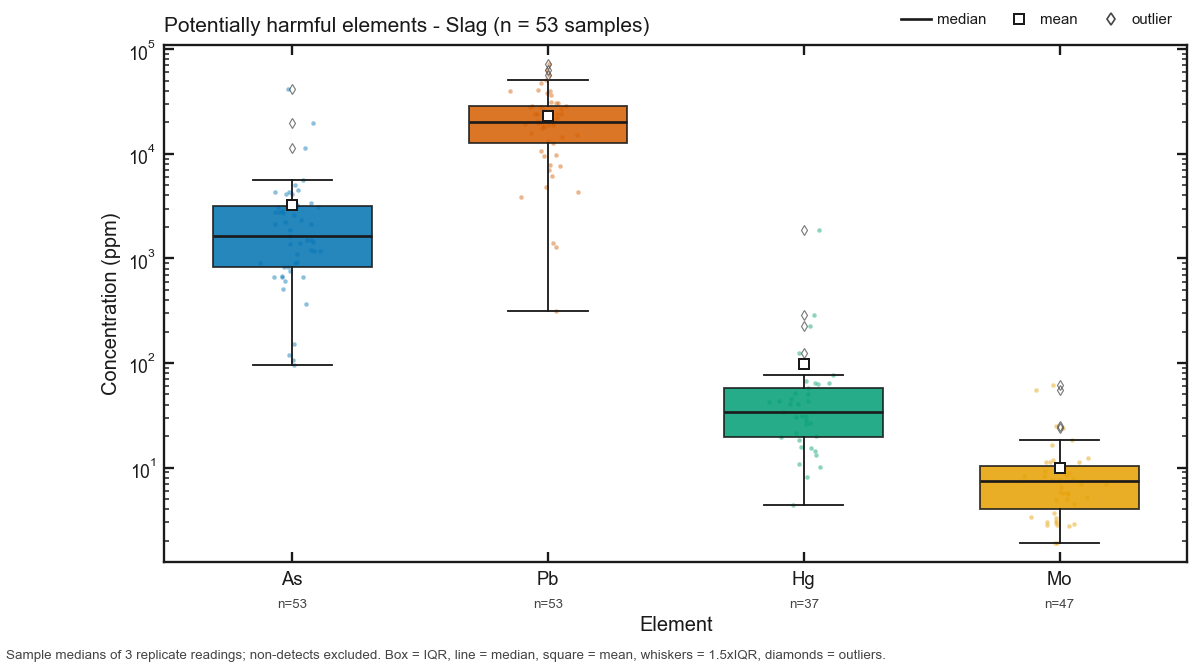

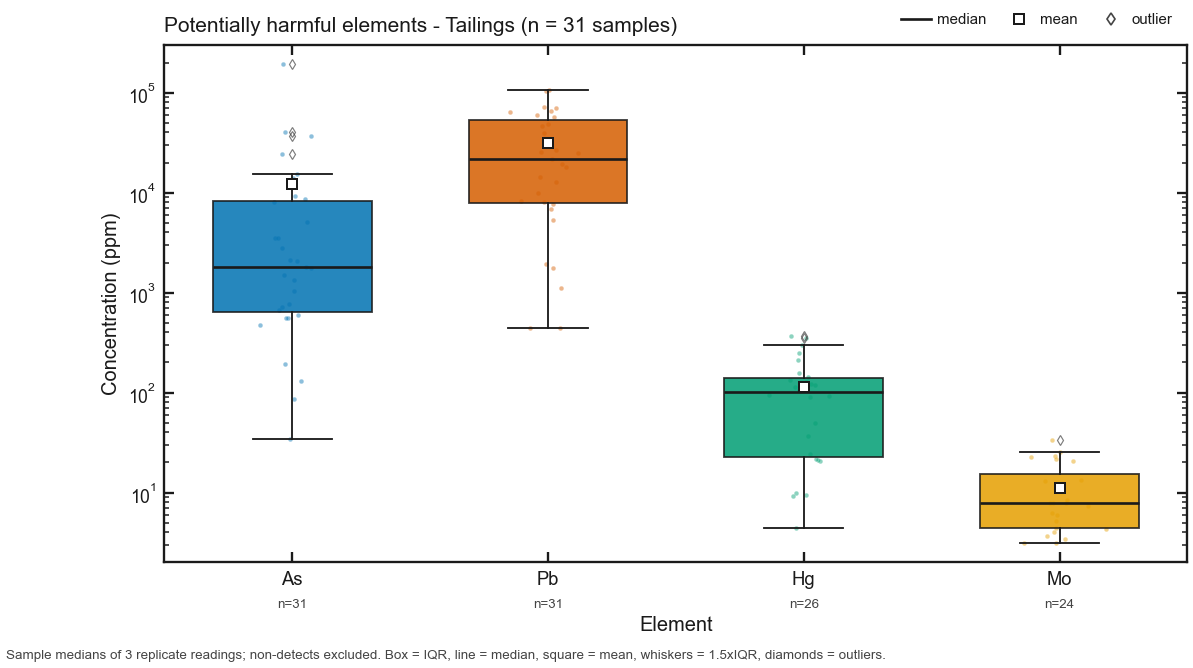



REGULATORY SCREENING
  No screening levels entered in §10 (A_SCREEN_LEVELS), so no exceedance statistics are produced.
  Enter the values of Andalusia generic reference levels, industrial use (Decreto 18/2015, Anexo IV) and re-run this cell. Note that those levels apply to SOILS:
  extractive waste is assessed under Directive 2006/21/EC and RD 975/2009, and the comparison is a
  screening step for the soils around the facility, not a waste classification.

Saved: XRF_PartB_Tab12_deleterious_statistics.csv, XRF_PartB_Tab12b_slag_vs_tailings.csv, XRF_PartB_Fig11_deleterious_*.png


In [28]:
def a_mann_whitney(a, b):
    """Two-sided Mann-Whitney U with a normal approximation and tie correction.

    Returns (U, p, rank-biserial effect size).  Uses scipy when available.
    """
    a = np.asarray(a, float); b = np.asarray(b, float)
    a = a[np.isfinite(a)]; b = b[np.isfinite(b)]
    n1, n2 = len(a), len(b)
    if n1 < 3 or n2 < 3:
        return np.nan, np.nan, np.nan
    try:
        from scipy import stats as _sp
        u, p = _sp.mannwhitneyu(a, b, alternative="two-sided")
    except Exception:
        allv = np.concatenate([a, b])
        ranks = pd.Series(allv).rank().to_numpy()
        r1 = ranks[:n1].sum()
        u = r1 - n1 * (n1 + 1) / 2.0
        mu = n1 * n2 / 2.0
        _, counts = np.unique(allv, return_counts=True)
        tie = (counts ** 3 - counts).sum()
        n = n1 + n2
        sd = np.sqrt(n1 * n2 / 12.0 * ((n + 1) - tie / (n * (n - 1))))
        z = (abs(u - mu) - 0.5) / sd if sd > 0 else 0.0
        p = 2 * 0.5 * math.erfc(z / math.sqrt(2))
    return float(u), float(p), float(2 * u / (n1 * n2) - 1)

def a_holm(pvals):
    """Holm-Bonferroni adjusted p-values (NaNs preserved)."""
    p = np.asarray(pvals, float)
    ok = np.isfinite(p)
    out = np.full_like(p, np.nan)
    idx = np.argsort(p[ok])
    m = ok.sum()
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(idx):
        running = max(running, (m - rank) * p[ok][i])
        adj[i] = min(running, 1.0)
    out[ok] = adj
    return out

A_DEL_PRESENT = [e for e in A_DELETERIOUS if e in SAMPLES.columns and e in A_USABLE]
A_DEL_EXCLUDED = [e for e in A_DELETERIOUS if e in SAMPLES.columns and e not in A_USABLE]

a_rows = []
for wt in ["slag", "tailing", "all"]:
    sub = SAMPLES if wt == "all" else SAMPLES[SAMPLES["waste_type"] == wt]
    if sub.empty:
        continue
    for e in A_DEL_PRESENT:
        v = sub[e].dropna()
        if v.empty:
            continue
        a_rows.append({"waste_type": wt, "element": e, "n_samples": len(sub), "n_detected": len(v),
                       "detection_pct": round(100 * len(v) / len(sub), 1),
                       "min": v.min(), "q1": v.quantile(0.25), "median": v.median(),
                       "q3": v.quantile(0.75), "p90": v.quantile(0.90), "max": v.max(),
                       "mean": v.mean(), "class": ELEMENT_QC.loc[e, "reliability_class"],
                       "enrichment_vs_background": round(float(v.median()) / A_UCC[e], 1) if A_UCC.get(e) else np.nan})
DELETERIOUS_STATS = pd.DataFrame(a_rows)

print("DELETERIOUS ELEMENTS - SAMPLE-LEVEL STATISTICS (ppm, detected values)")
print("=" * 110)
for wt in ["all", "slag", "tailing"]:
    sub = DELETERIOUS_STATS[DELETERIOUS_STATS["waste_type"] == wt]
    if sub.empty:
        continue
    label = "ALL SAMPLES" if wt == "all" else f"{WASTE_LABEL.get(wt, wt).upper()}"
    print(f"\n{label}  (n = {int(sub['n_samples'].iloc[0])} samples)")
    print(f"  {'El':<4}{'cls':<5}{'det %':>7}{'min':>11}{'Q1':>11}{'median':>11}{'Q3':>11}{'P90':>11}{'max':>12}{'x background':>14}")
    print("  " + "-" * 104)
    for _, r in sub.iterrows():
        flag = " *" if r["detection_pct"] < 50 else ""
        print(f"  {r['element']:<4}{r['class']:<5}{r['detection_pct']:>7.0f}{r['min']:>11,.0f}{r['q1']:>11,.0f}"
              f"{r['median']:>11,.0f}{r['q3']:>11,.0f}{r['p90']:>11,.0f}{r['max']:>12,.0f}"
              f"{r['enrichment_vs_background']:>13,.0f}x{flag}")
print("\n  * detected in fewer than half of the samples: the median describes the detected population only.")

if A_DEL_EXCLUDED:
    print(f"\n\nDELETERIOUS ELEMENTS HELD BACK AS CLASS C (§11) - REPORTED, NOT QUANTIFIED")
    print("=" * 110)
    print(f"  {'El':<4}{'det %':>7}{'median':>11}{'max':>12}{'x bkg':>10}  reason for holding it back")
    print("  " + "-" * 104)
    for e in A_DEL_EXCLUDED:
        v = SAMPLES[e].dropna()
        if v.empty:
            continue
        ef = float(v.median()) / A_UCC[e] if A_UCC.get(e) else np.nan
        print(f"  {e:<4}{100 * len(v) / len(SAMPLES):>7.0f}{v.median():>11,.0f}{v.max():>12,.0f}"
              f"{ef:>9,.0f}x  {ELEMENT_QC.loc[e, 'concern']}")
    a_del_imp = [e for e in A_DEL_EXCLUDED if e in A_IMPRECISE]
    a_del_art = [e for e in A_DEL_EXCLUDED if e in A_ARTEFACT]
    print("\n  These values are shown so that nothing is hidden, but they are NOT used in any statistic, index or")
    print("  conclusion below.")
    if a_del_imp:
        print(f"  {', '.join(a_del_imp)} are held back on precision or detection grounds alone. They are")
        print("  geologically expected in Iberian Pyrite Belt material, laboratory assay is likely to confirm")
        print("  them, and the thesis should say exactly that rather than either quoting or omitting them")
        print("  silently. Until then the environmental assessment of this material is incomplete for them.")
    if a_del_art:
        print(f"  {', '.join(a_del_art)} are probable spectral artefacts and should not be carried forward at all.")

# slag vs tailing
a_cmp = []
for e in A_DEL_PRESENT:
    a_ = SAMPLES.loc[SAMPLES["waste_type"] == "slag", e].dropna()
    b_ = SAMPLES.loc[SAMPLES["waste_type"] == "tailing", e].dropna()
    u, p, rb = a_mann_whitney(a_, b_)
    a_cmp.append({"element": e, "n_slag": len(a_), "n_tailing": len(b_),
                  "median_slag": a_.median() if len(a_) else np.nan,
                  "median_tailing": b_.median() if len(b_) else np.nan,
                  "ratio_slag_over_tailing": (a_.median() / b_.median()) if len(a_) and len(b_) and b_.median() else np.nan,
                  "U": u, "p_value": p, "effect_size_rb": rb})
WASTE_COMPARISON = pd.DataFrame(a_cmp)
WASTE_COMPARISON["p_holm"] = a_holm(WASTE_COMPARISON["p_value"].to_numpy())
WASTE_COMPARISON["higher_in"] = np.where(WASTE_COMPARISON["p_holm"] > 0.05, "no difference",
                                         np.where(WASTE_COMPARISON["ratio_slag_over_tailing"] > 1, "slag", "tailings"))
print("\n\nSLAG vs TAILINGS  (Mann-Whitney U on sample medians, Holm-adjusted)")
print("=" * 110)
print(WASTE_COMPARISON.round({"median_slag": 0, "median_tailing": 0, "ratio_slag_over_tailing": 2,
                              "p_value": 4, "p_holm": 4, "effect_size_rb": 2}).to_string(index=False))

# box charts
for wt in ["slag", "tailing"]:
    sub = SAMPLES[SAMPLES["waste_type"] == wt]
    if sub.empty:
        continue
    long_del = (sub[A_DEL_PRESENT].melt(var_name="Element", value_name="ppm").dropna(subset=["ppm"]))
    fig_d, ax_d = plt.subplots(figsize=(11, 5.6))
    plot_boxplot_single(ax_d, long_del, A_DEL_PRESENT,
                        title=f"Potentially harmful elements - {WASTE_LABEL.get(wt, wt)} (n = {len(sub)} samples)")
    for e_i, e in enumerate(A_DEL_PRESENT):
        lvl = A_SCREEN_LEVELS.get(e)
        if lvl:
            ax_d.plot([e_i + 0.62, e_i + 1.38], [lvl, lvl], color="#D55E00", lw=1.6, zorder=6)
    fig_d.text(0.005, -0.02,
               f"Sample medians of {int(a_nread.median())} replicate readings; non-detects excluded. "
               f"Box = IQR, line = median, square = mean, whiskers = 1.5xIQR, diamonds = outliers."
               + ("  Orange lines: " + A_SCREEN_LABEL if any(A_SCREEN_LEVELS.get(e) for e in A_DEL_PRESENT) else ""),
               fontsize=8, color=INK_SOFT, ha="left", va="top")
    fig_d.savefig(A_OUT / f"{A_PREFIX}_Fig11_deleterious_{wt}.png", dpi=DPI_HIGHRES, bbox_inches="tight")
plt.show()

# regulatory screening
a_screened = {e: v for e, v in A_SCREEN_LEVELS.items() if v is not None and e in SAMPLES.columns}
if not a_screened:
    print("\n\nREGULATORY SCREENING")
    print("=" * 110)
    print("  No screening levels entered in §10 (A_SCREEN_LEVELS), so no exceedance statistics are produced.")
    print(f"  Enter the values of {A_SCREEN_LABEL} and re-run this cell. Note that those levels apply to SOILS:")
    print("  extractive waste is assessed under Directive 2006/21/EC and RD 975/2009, and the comparison is a")
    print("  screening step for the soils around the facility, not a waste classification.")
    SCREENING = None
else:
    a_sc = []
    for e, lvl in a_screened.items():
        for wt in ["slag", "tailing", "all"]:
            sub = SAMPLES if wt == "all" else SAMPLES[SAMPLES["waste_type"] == wt]
            v = sub[e].dropna()
            if v.empty:
                continue
            a_sc.append({"element": e, "waste_type": wt, "screening_level_mg_kg": lvl, "n_detected": len(v),
                         "n_above": int((v > lvl).sum()), "pct_above": round(100 * (v > lvl).mean(), 1),
                         "median_over_level": round(float(v.median() / lvl), 2),
                         "max_over_level": round(float(v.max() / lvl), 2)})
    SCREENING = pd.DataFrame(a_sc)
    print("\n\nSCREENING AGAINST " + A_SCREEN_LABEL.upper())
    print("=" * 110)
    print(SCREENING.to_string(index=False))
    SCREENING.to_csv(A_OUT / f"{A_PREFIX}_Tab13_screening_exceedance.csv", index=False, encoding="utf-8-sig")

DELETERIOUS_STATS.to_csv(A_OUT / f"{A_PREFIX}_Tab12_deleterious_statistics.csv", index=False, encoding="utf-8-sig")
WASTE_COMPARISON.to_csv(A_OUT / f"{A_PREFIX}_Tab12b_slag_vs_tailings.csv", index=False, encoding="utf-8-sig")
print(f"\nSaved: {A_PREFIX}_Tab12_deleterious_statistics.csv, {A_PREFIX}_Tab12b_slag_vs_tailings.csv, "
      f"{A_PREFIX}_Fig11_deleterious_*.png")

## 13 · Contamination and ecological-risk indices

Concentrations alone do not say how far the material departs from a natural baseline, and they cannot be compared
between elements whose crustal abundances differ by four orders of magnitude. The indices below are the set used
in the mine-waste and sediment-geochemistry literature; all of them are ratios to a background value *B*, so the
choice of background governs the result and is stated with every table.

| Index | Definition | Source |
|---|---|---|
| Contamination factor | $CF_i = C_i / B_i$ | Håkanson (1980) |
| Geoaccumulation index | $I_{geo} = \log_2\!\left(C_i / (1.5\,B_i)\right)$ | Müller (1969) |
| Pollution load index | $PLI = (CF_1 \cdot CF_2 \cdots CF_n)^{1/n}$ | Tomlinson et al. (1980) |
| Modified degree of contamination | $mCd = \frac{1}{n}\sum_{i=1}^{n} CF_i$ | Abrahim & Parker (2008) |
| Potential ecological risk factor | $E_r^i = T_r^i \cdot CF_i$ | Håkanson (1980) |
| Potential ecological risk index | $RI = \sum E_r^i$ | Håkanson (1980) |

**Classification schemes applied in the tables**

| $I_{geo}$ | Class | Description | | $CF$ | Description | | $mCd$ | Description | | $RI$ | Description |
|---|---|---|---|---|---|---|---|---|---|---|---|
| ≤ 0 | 0 | uncontaminated | | < 1 | low | | < 1.5 | nil to very low | | < 150 | low |
| 0–1 | 1 | uncontaminated to moderate | | 1–3 | moderate | | 1.5–2 | low | | 150–300 | moderate |
| 1–2 | 2 | moderately contaminated | | 3–6 | considerable | | 2–4 | moderate | | 300–600 | considerable |
| 2–3 | 3 | moderately to heavily | | ≥ 6 | very high | | 4–8 | high | | ≥ 600 | very high |
| 3–4 | 4 | heavily contaminated | | | | | 8–16 | very high | | | |
| 4–5 | 5 | heavily to extremely | | | | | 16–32 | extremely high | | | |
| > 5 | 6 | extremely contaminated | | | | | ≥ 32 | ultra high | | | |

**Four caveats that belong in the text of the thesis, not only in the code.**

1. *These indices were developed for soils and sediments, not for extractive waste.* Slag and processing tailings
   are engineered materials; calling a tailings sample "extremely contaminated" against a crustal background is
   close to tautological, because the material exists precisely because it is metal-rich. The indices are used
   here as a **quantitative, comparable ranking** between samples, waste types and spatial domains, and as the
   standard currency in which mine-waste geochemistry is reported — not as a statement of regulatory status.
2. *The background dominates the answer.* Upper continental crust is the conventional and conservative choice, but
   the Iberian Pyrite Belt host rocks are not average crust. If an unmineralised local background (host shales or
   volcaniclastics sampled off the deposit) is available, replace `A_UCC` in §10; every index will drop, in places
   by whole classes, and that lower set is what should be quoted when the comparison is to the local geology.
3. *The risk index is a lower bound.* Håkanson's toxic-response factors exist for Zn, Cr, Cu, Pb, Ni, As, Cd and
   Hg only. Sb, Sn, Bi, Se, Mo and Ag carry no published factor and are excluded rather than assigned an invented
   one, so `RI` under-states the suite actually present. The original thresholds were also calibrated on an
   eight-substance suite; with a different suite they are ordinal, not absolute.
4. *Total concentration is not bioavailability.* None of these indices describe mobility. That requires the
   leaching and acid–base accounting programme set out in §16 (EN 12457-2, EN 15875), and — for the residual metal
   in slag — a mineralogical determination of what phase actually hosts the metal.

INDEX ELEMENT SETS
------------------------------------------------------------------------------
  CF / Igeo (single element)      : As, Pb, Hg, Mo
  PLI, mCd (detection >= 80%)     : As, Pb, Mo
  RI (toxic-response factor known): As, Pb
  Excluded from RI (no published factor): Mo - RI is therefore a LOWER BOUND
  Background: upper continental crust (Rudnick & Gao, 2014)


CONTAMINATION INDICES BY ELEMENT AND WASTE TYPE

ALL SAMPLES
  El  cls     n   CF median      CF class  Igeo median    Igeo class (median sample)  PLI/mCd   RI
  ------------------------------------------------------------------------------------------------------
  Pb  A      87     1,207.8     very high          9.7                     6 extreme      yes  yes
  Hg  A      65       873.6     very high          9.2                     6 extreme        -    -
  As  A      87       392.0     very high          8.0                     6 extreme      yes  yes
  Mo  A      73         6.8     very high          2.2      

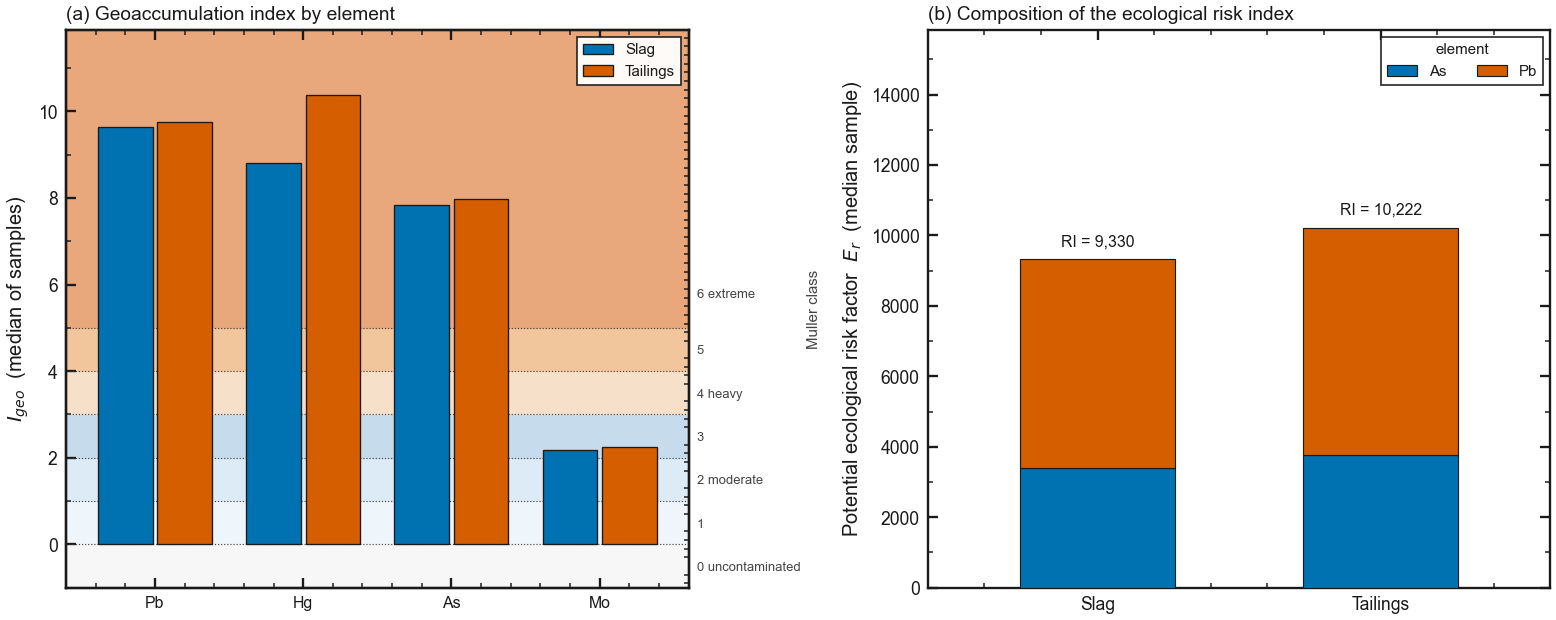

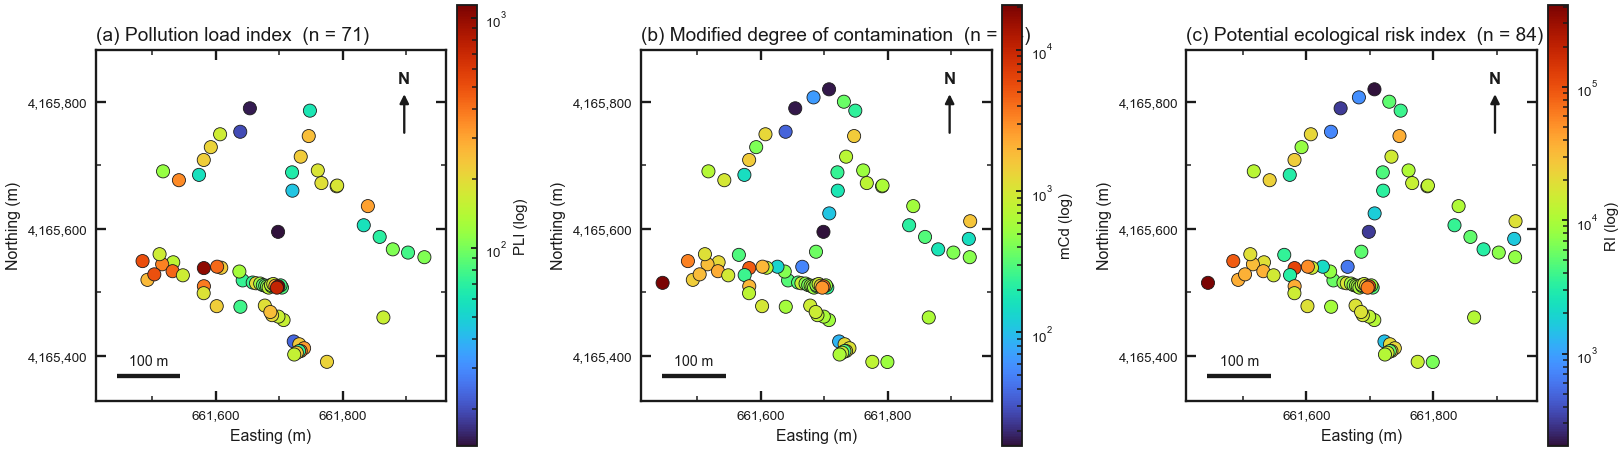

Highest potential ecological risk (sample, RI, waste type):
   LMW21      RI =      408,372   tailing
   LMW15      RI =      114,661   tailing
   MM27       RI =      103,252   slag
   LMW20      RI =       89,136   tailing
   MM28       RI =       62,816   slag

Saved: XRF_PartB_Tab14_sample_indices.csv, XRF_PartB_Tab15_index_summary.csv, XRF_PartB_Fig12_contamination_indices.png, XRF_PartB_Fig13_index_maps.png


In [29]:
A_IDX_ELEMENTS = [e for e in A_DEL_PRESENT
                  if A_UCC.get(e) and ELEMENT_QC.loc[e, "detection_pct"] >= A_MIN_INDEX_DETECT]
A_CF_ELEMENTS = [e for e in A_DEL_PRESENT if A_UCC.get(e)]
A_RI_ELEMENTS = [e for e in A_IDX_ELEMENTS if e in A_TRF]

print("INDEX ELEMENT SETS")
print("-" * 78)
print(f"  CF / Igeo (single element)      : {', '.join(A_CF_ELEMENTS) or 'none'}")
print(f"  PLI, mCd (detection >= {A_MIN_INDEX_DETECT}%)     : {', '.join(A_IDX_ELEMENTS) or 'none'}")
print(f"  RI (toxic-response factor known): {', '.join(A_RI_ELEMENTS) or 'none'}")
a_no_trf = [e for e in A_IDX_ELEMENTS if e not in A_TRF]
if a_no_trf:
    print(f"  Excluded from RI (no published factor): {', '.join(a_no_trf)} - RI is therefore a LOWER BOUND")
print(f"  Background: {A_BACKGROUND_LABEL}")

# per-sample indices
A_CF = pd.DataFrame({e: SAMPLES[e] / A_UCC[e] for e in A_CF_ELEMENTS}, index=SAMPLES.index)
A_IGEO = pd.DataFrame({e: np.log2(SAMPLES[e] / (A_IGEO_FACTOR * A_UCC[e])) for e in A_CF_ELEMENTS},
                      index=SAMPLES.index)

CONTAMINATION = pd.DataFrame(index=SAMPLES.index)
CONTAMINATION["waste_type"] = SAMPLES["waste_type"]
for e in A_CF_ELEMENTS:
    CONTAMINATION[f"CF_{e}"] = A_CF[e]
for e in A_CF_ELEMENTS:
    CONTAMINATION[f"Igeo_{e}"] = A_IGEO[e]

# PLI: geometric mean of the CFs; computed only where every index element was detected.
a_cf_idx = A_CF[A_IDX_ELEMENTS]
a_complete = a_cf_idx.notna().all(axis=1)
CONTAMINATION["PLI"] = np.where(a_complete, np.exp(np.log(a_cf_idx.where(a_cf_idx > 0)).mean(axis=1)), np.nan)
CONTAMINATION["mCd"] = a_cf_idx.mean(axis=1, skipna=True)
CONTAMINATION["n_index_elements"] = a_cf_idx.notna().sum(axis=1)
for e in A_RI_ELEMENTS:
    CONTAMINATION[f"Er_{e}"] = A_TRF[e] * A_CF[e]
CONTAMINATION["RI"] = CONTAMINATION[[f"Er_{e}" for e in A_RI_ELEMENTS]].sum(axis=1, skipna=True) \
    if A_RI_ELEMENTS else np.nan


def a_class_igeo(v):
    if not np.isfinite(v):
        return ""
    if v <= 0:
        return "0 uncontaminated"
    for k, lab in enumerate(["1 uncont.-moderate", "2 moderate", "3 moderate-heavy",
                             "4 heavy", "5 heavy-extreme"], start=1):
        if v <= k:
            return lab
    return "6 extreme"


def a_class_generic(v, edges, labels):
    if not np.isfinite(v):
        return ""
    for edge, lab in zip(edges, labels):
        if v < edge:
            return lab
    return labels[-1]


A_MCD_EDGES = ([1.5, 2, 4, 8, 16, 32, np.inf],
               ["nil-very low", "low", "moderate", "high", "very high", "extremely high", "ultra high"])
A_RI_EDGES = ([150, 300, 600, np.inf], ["low", "moderate", "considerable", "very high"])
A_PLI_EDGES = ([1, np.inf], ["baseline (PLI < 1)", "deteriorated (PLI > 1)"])

CONTAMINATION["mCd_class"] = [a_class_generic(v, *A_MCD_EDGES) for v in CONTAMINATION["mCd"]]
CONTAMINATION["RI_class"] = [a_class_generic(v, *A_RI_EDGES) for v in CONTAMINATION["RI"]]
CONTAMINATION["PLI_class"] = [a_class_generic(v, *A_PLI_EDGES) for v in CONTAMINATION["PLI"]]

# per-element summary by waste type
a_isum = []
for wt in ["slag", "tailing", "all"]:
    sel = slice(None) if wt == "all" else (SAMPLES["waste_type"] == wt)
    sub_cf, sub_ig = A_CF.loc[sel], A_IGEO.loc[sel]
    if len(sub_cf) == 0:
        continue
    for e in A_CF_ELEMENTS:
        cf, ig = sub_cf[e].dropna(), sub_ig[e].dropna()
        if cf.empty:
            continue
        a_isum.append({"waste_type": wt, "element": e, "class": ELEMENT_QC.loc[e, "reliability_class"],
                       "n": len(cf), "CF_median": cf.median(), "CF_max": cf.max(),
                       "CF_class": a_class_generic(float(cf.median()), [1, 3, 6, np.inf],
                                                   ["low", "moderate", "considerable", "very high"]),
                       "Igeo_median": ig.median(), "Igeo_max": ig.max(),
                       "Igeo_class_median": a_class_igeo(float(ig.median())),
                       "pct_samples_Igeo_gt5": round(100 * float((ig > 5).mean()), 1),
                       "Er_median": A_TRF[e] * cf.median() if e in A_TRF else np.nan,
                       "in_PLI_mCd": e in A_IDX_ELEMENTS, "in_RI": e in A_RI_ELEMENTS})
INDEX_SUMMARY = pd.DataFrame(a_isum)

print("\n\nCONTAMINATION INDICES BY ELEMENT AND WASTE TYPE")
print("=" * 108)
for wt in ["all", "slag", "tailing"]:
    sub = INDEX_SUMMARY[INDEX_SUMMARY["waste_type"] == wt].sort_values("Igeo_median", ascending=False)
    if sub.empty:
        continue
    label = "ALL SAMPLES" if wt == "all" else WASTE_LABEL.get(wt, wt).upper()
    print(f"\n{label}")
    print(f"  {'El':<4}{'cls':<5}{'n':>4}{'CF median':>12}{'CF class':>14}{'Igeo median':>13}"
          f"{'Igeo class (median sample)':>30}{'PLI/mCd':>9}{'RI':>5}")
    print("  " + "-" * 102)
    for _, r in sub.iterrows():
        print(f"  {r['element']:<4}{r['class']:<5}{r['n']:>4}{r['CF_median']:>12,.1f}{r['CF_class']:>14}"
              f"{r['Igeo_median']:>13.1f}{r['Igeo_class_median']:>30}"
              f"{('yes' if r['in_PLI_mCd'] else '-'):>9}{('yes' if r['in_RI'] else '-'):>5}")

print("\n\nSAMPLE-LEVEL INDICES BY WASTE TYPE  (median [range] over samples)")
print("=" * 108)
print(f"  {'waste type':<12}{'n':>5}{'PLI':>24}{'mCd':>24}{'RI':>26}")
print("  " + "-" * 102)
for wt in ["slag", "tailing", "all"]:
    sub = CONTAMINATION if wt == "all" else CONTAMINATION[CONTAMINATION["waste_type"] == wt]
    if sub.empty:
        continue
    cells = []
    for col in ["PLI", "mCd", "RI"]:
        v = pd.to_numeric(sub[col], errors="coerce").dropna()
        cells.append(f"{v.median():,.0f} [{v.min():,.0f}-{v.max():,.0f}]" if len(v) else "-")
    lab = "all samples" if wt == "all" else WASTE_LABEL.get(wt, wt)
    print(f"  {lab:<12}{len(sub):>5}{cells[0]:>24}{cells[1]:>24}{cells[2]:>26}")
print(f"\n  PLI computed on {len(A_IDX_ELEMENTS)} elements ({', '.join(A_IDX_ELEMENTS)}) for the "
      f"{int(a_complete.sum())} of {len(SAMPLES)} samples in which all of them were detected.")
print(f"  RI computed on {len(A_RI_ELEMENTS)} elements ({', '.join(A_RI_ELEMENTS)}); it excludes "
      f"{', '.join(a_no_trf) if a_no_trf else 'nothing'} and is a lower bound.")
print("  Class boundaries are those of the original authors; against a crustal background an engineered")
print("  metallurgical residue is expected to fall in the highest classes, so the value of these numbers is")
print("  the RANKING between samples and domains, not the class name.")

# figure: Igeo by element, and the composition of the risk index
a_wts = [wt for wt in ["slag", "tailing"] if (SAMPLES["waste_type"] == wt).any()]
a_order = (INDEX_SUMMARY[INDEX_SUMMARY["waste_type"] == "all"]
           .sort_values("Igeo_median", ascending=False)["element"].tolist())

fig_ix, ax_ix = plt.subplots(1, 2, figsize=(13.2, 5.4))

axi = ax_ix[0]
a_bands = [(-20, 0, "#f7f7f7"), (0, 1, "#eef6fb"), (1, 2, "#dcebf5"), (2, 3, "#c6dced"),
           (3, 4, "#f7e0c9"), (4, 5, "#f2c69d"), (5, 30, "#e8a87c")]
for lo, hi, col in a_bands:
    axi.axhspan(lo, hi, color=col, zorder=0)
a_w = 0.8 / max(len(a_wts), 1)
for j, wt in enumerate(a_wts):
    sub = INDEX_SUMMARY[INDEX_SUMMARY["waste_type"] == wt].set_index("element").reindex(a_order)
    axi.bar(np.arange(len(a_order)) + j * a_w - 0.4 + a_w / 2, sub["Igeo_median"].to_numpy(),
            width=a_w * 0.92, color=COLORBLIND_PALETTE[j], edgecolor=INK, linewidth=0.8,
            label=WASTE_LABEL.get(wt, wt), zorder=3)
for y in range(0, 6):
    axi.axhline(y, color=INK_SOFT, lw=0.7, ls=":", zorder=2)
axi.set_xticks(range(len(a_order)))
axi.set_xticklabels(a_order, fontsize=9.5)
axi.set_ylabel(r"$I_{geo}$  (median of samples)")
axi.set_xlim(-0.6, len(a_order) - 0.4)
axi.set_ylim(min(-1, float(np.nanmin(INDEX_SUMMARY["Igeo_median"])) - 0.5),
             float(np.nanmax(INDEX_SUMMARY["Igeo_median"])) + 1.5)
axi.set_title("(a) Geoaccumulation index by element", fontsize=11.5, loc="left")
axi.legend(loc="upper right", fontsize=9, framealpha=0.95)
style_frame(axi, xminor=None, yminor=2)
# Muller classes as a second scale on the right, so nothing overlaps the bars.
axi_r = axi.twinx()
axi_r.set_ylim(*axi.get_ylim())
a_cls_ticks = [(-0.5, "0 uncontaminated"), (0.5, "1"), (1.5, "2 moderate"), (2.5, "3"),
               (3.5, "4 heavy"), (4.5, "5"), (5.8, "6 extreme")]
a_keep_ticks = [(y, l) for y, l in a_cls_ticks if axi.get_ylim()[0] < y < axi.get_ylim()[1]]
axi_r.set_yticks([y for y, _ in a_keep_ticks])
axi_r.set_yticklabels([l for _, l in a_keep_ticks], fontsize=7.8, color=INK_SOFT)
axi_r.tick_params(axis="y", length=0)
axi_r.set_ylabel("Muller class", fontsize=9, color=INK_SOFT)
for s in axi_r.spines.values():
    s.set_linewidth(1.4); s.set_color(INK)

axi = ax_ix[1]
if A_RI_ELEMENTS:
    a_bottom = np.zeros(len(a_wts) or 1)
    for k, e in enumerate(A_RI_ELEMENTS):
        vals = np.array([float(pd.to_numeric(
            CONTAMINATION.loc[CONTAMINATION["waste_type"] == wt, f"Er_{e}"], errors="coerce").median())
            for wt in a_wts])
        vals = np.nan_to_num(vals)
        axi.bar(np.arange(len(a_wts)), vals, bottom=a_bottom, width=0.55,
                color=_elem_color(k), edgecolor=INK, linewidth=0.7, label=e, zorder=3)
        a_bottom = a_bottom + vals
    for xi, tot in enumerate(a_bottom):
        axi.text(xi, tot * 1.03, f"RI = {tot:,.0f}", ha="center", va="bottom", fontsize=9.5, color=INK)
    axi.set_xticks(range(len(a_wts)))
    axi.set_xticklabels([WASTE_LABEL.get(w, w) for w in a_wts])
    axi.set_xlim(-0.6, len(a_wts) - 0.4)
    axi.set_ylabel(r"Potential ecological risk factor  $E_r$  (median sample)")
    axi.set_title("(b) Composition of the ecological risk index", fontsize=11.5, loc="left")
    axi.legend(loc="upper right", fontsize=9, ncol=2, title="element", title_fontsize=9, framealpha=0.95)
    axi.set_ylim(0, float(np.nanmax(a_bottom)) * 1.55 if np.isfinite(np.nanmax(a_bottom)) else 1)
    style_frame(axi, xminor=None, yminor=2)
else:
    axi.axis("off")
    axi.text(0.5, 0.5, "No element with a published\ntoxic-response factor", ha="center", va="center")

fig_ix.tight_layout()
fig_ix.savefig(A_OUT / f"{A_PREFIX}_Fig12_contamination_indices.png", dpi=DPI_HIGHRES, bbox_inches="tight")
plt.show()

# shared map helper and index maps
A_HAS_XY = ("East" in SAMPLES.columns) and bool(SAMPLES["East"].notna().any())
if A_HAS_XY:
    a_xs = SAMPLES["East"].astype(float)
    a_ys = SAMPLES["North"].astype(float)
    a_cx, a_cy = (a_xs.min() + a_xs.max()) / 2, (a_ys.min() + a_ys.max()) / 2
    a_half = max(a_xs.max() - a_xs.min(), a_ys.max() - a_ys.min()) / 2 * 1.14
    A_EXTENT = (a_cx - a_half, a_cx + a_half, a_cy - a_half, a_cy + a_half)


def a_map_panel(fig, ax, values, title, cbar_label, cmap="turbo", log=False, discrete=None):
    """Square UTM map panel in the Section 2 house style.

    `values` is a Series indexed like SAMPLES.  `discrete` (dict label -> colour)
    draws a categorical map with a key instead of a colour bar.
    """
    if not A_HAS_XY:
        ax.axis("off")
        ax.text(0.5, 0.5, "no coordinates", ha="center", va="center")
        return None
    ok = SAMPLES["East"].notna() & SAMPLES["North"].notna() & values.reindex(SAMPLES.index).notna()
    xs, ys = SAMPLES.loc[ok, "East"], SAMPLES.loc[ok, "North"]
    v = values.reindex(SAMPLES.index)[ok]
    sc = None
    if discrete is not None:
        for lab, col in discrete.items():
            m = (v == lab)
            ax.scatter(xs[m], ys[m], c=col, s=62, edgecolor=INK, linewidth=0.5, zorder=4,
                       label=f"{lab} (n = {int(m.sum())})")
        ax.legend(loc="upper left", fontsize=8, frameon=True, framealpha=0.92, handletextpad=0.3)
    else:
        vv = pd.to_numeric(v, errors="coerce").astype(float)
        norm = LogNorm(vmin=max(float(vv[vv > 0].min()), 1e-9), vmax=float(vv.max())) \
            if (log and (vv > 0).any()) else None
        sc = ax.scatter(xs, ys, c=vv, cmap=cmap, norm=norm, s=62, edgecolor=INK,
                        linewidth=0.5, zorder=4)
        cb = fig.colorbar(sc, ax=ax, shrink=0.86, pad=0.025, aspect=22)
        cb.set_label(cbar_label, fontsize=9)
        cb.ax.tick_params(labelsize=8, width=1.1, length=3.5)
        cb.outline.set_linewidth(1.1)
    ax.set_xlim(A_EXTENT[0], A_EXTENT[1])
    ax.set_ylim(A_EXTENT[2], A_EXTENT[3])
    ax.set_aspect("equal", adjustable="box")
    style_frame(ax, xminor=2, yminor=2)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
    ax.xaxis.set_major_formatter(_utm_formatter("E"))
    ax.yaxis.set_major_formatter(_utm_formatter("N"))
    ax.tick_params(axis="both", labelsize=8)
    ax.set_xlabel("Easting (m)", fontsize=9.5)
    ax.set_ylabel("Northing (m)", fontsize=9.5)
    ax.set_title(f"{title}  (n = {int(ok.sum())})", fontsize=11.5, loc="left", pad=6)
    add_north_arrow(ax)
    add_scale_bar(ax)
    return sc


if A_HAS_XY:
    a_maps = [("PLI", "Pollution load index", "PLI", True),
              ("mCd", "Modified degree of contamination", "mCd", True),
              ("RI", "Potential ecological risk index", "RI", True)]
    a_maps = [m for m in a_maps if pd.to_numeric(CONTAMINATION[m[0]], errors="coerce").notna().any()]
    fig_im, ax_im = plt.subplots(1, len(a_maps), figsize=(4.6 * len(a_maps), 4.6), squeeze=False)
    for k, (col, title, cbl, lg) in enumerate(a_maps):
        a_map_panel(fig_im, ax_im[0][k], pd.to_numeric(CONTAMINATION[col], errors="coerce"),
                    f"({chr(97 + k)}) {title}", cbl + (" (log)" if lg else ""), log=lg)
    fig_im.tight_layout()
    fig_im.savefig(A_OUT / f"{A_PREFIX}_Fig13_index_maps.png", dpi=DPI_HIGHRES, bbox_inches="tight")
    plt.show()
    a_hot = CONTAMINATION["RI"].astype(float).nlargest(5)
    print("Highest potential ecological risk (sample, RI, waste type):")
    for k, v in a_hot.items():
        print(f"   {k:<10} RI = {v:>12,.0f}   {CONTAMINATION.loc[k, 'waste_type'] or 'unclassified'}")
else:
    print("No coordinates joined - index maps skipped.")

CONTAMINATION.to_csv(A_OUT / f"{A_PREFIX}_Tab14_sample_indices.csv", encoding="utf-8-sig")
INDEX_SUMMARY.to_csv(A_OUT / f"{A_PREFIX}_Tab15_index_summary.csv", index=False, encoding="utf-8-sig")
print(f"\nSaved: {A_PREFIX}_Tab14_sample_indices.csv, {A_PREFIX}_Tab15_index_summary.csv, "
      f"{A_PREFIX}_Fig12_contamination_indices.png, {A_PREFIX}_Fig13_index_maps.png")

## 14 · Element associations, compositional PCA and geochemical domains

Which elements travel together is the question that links the chemistry to the mineralogy and to the processing
route: an As–Pb–Sb–Bi association points to sulphosalts and to the fahlore/tennantite group, Cu–Co–Ni to a residual
sulphide or to slag-hosted metallic prills, Fe–Zn–S to sphalerite and its alteration products, and
Ti–V–Zr–Nb to the silicate and oxide fraction that carries no recoverable value. The same question decides whether
a critical raw material can be separated from a penalty element at all.

**Compositional data.** Concentrations are parts of a whole and sum to a constant, so their covariances are
constrained (the closure problem, Aitchison 1986): raw correlations between concentrations are not free to take any
value and a correlation coefficient computed on them is not interpretable as a correlation between the underlying
quantities. Two standard responses are used here:

- **Rank correlation on log concentrations** (Spearman ρ) for the pairwise picture. Rank-based and therefore robust
  to the strong positive skew and to the outliers that censoring produces; it is reported as a screening
  description, not as a test of independence.
- **Centred log-ratio (clr) transform before PCA**: $x_i^{clr} = \ln\!\left(x_i / g(\mathbf{x})\right)$ where
  $g(\mathbf{x})$ is the geometric mean of the composition. The clr scores are free of the constant-sum constraint,
  so a principal component analysis of them describes real variation in relative abundance. The clr matrix is
  singular by construction (its rows sum to zero), which is why the last component carries no variance and is
  dropped.

**Non-detects.** clr needs a complete, strictly positive matrix. Only elements detected in at least
`A_MIN_INDEX_DETECT` % of samples enter the analysis, and the few remaining gaps are filled with half the smallest
detected value of that element — the simple substitution that is acceptable only at low censoring (Helsel, 2012).
The number of substituted cells is printed so the reader can judge it.

**Domains.** *k*-means on the retained clr-PCA scores groups the samples into `A_N_DOMAINS` geochemical domains.
*k*-means is a partition, not a test: it will always return the number of groups it is asked for. The domains are
used here to describe the spatial organisation of the waste (which part of the facility is slag-like, which is
oxidised tailings, where the metal is), and each domain is labelled automatically by the elements most enriched in
it relative to the deposit as a whole. Their geological meaning is for the interpreter to confirm against field
observation and mineralogy.

MULTIVARIATE ANALYSIS
------------------------------------------------------------------------------
  Elements used (14): As, Bi, Cu, Fe, Mo, Nb, Ni, Pb, Rb, Sn, Sr, Ti, Zn, Zr
  Excluded: class C elements and anything detected in < 80% of samples.
  Substituted cells (half lowest detected value): 75 of 1218 (6.2%)

  Explained variance: PC1 35.7%, PC2 23.8%, PC3 12.4%, PC4 7.1%  (PC1-PC3 together 71.9%)

  clr-PCA LOADINGS (element contribution to each component)
  --------------------------------------------------------------------------
  PC1 (35.7%)  positive: Sn (+0.30), As (+0.25), Pb (+0.21), Bi (+0.20)
             negative: Rb (-0.51), Sr (-0.51), Zr (-0.37), Ti (-0.18)
  PC2 (23.8%)  positive: Bi (+0.32), Sn (+0.30), Ti (+0.21), Pb (+0.20)
             negative: Fe (-0.49), Cu (-0.43), Zn (-0.34), Ni (-0.31)
  PC3 (12.4%)  positive: Nb (+0.58), Ni (+0.22), Zr (+0.21), Ti (+0.20)
             negative: As (-0.51), Sr (-0.43), Cu (-0.13), Sn (-0.12)

  STRONGEST RANK ASSOCIATI

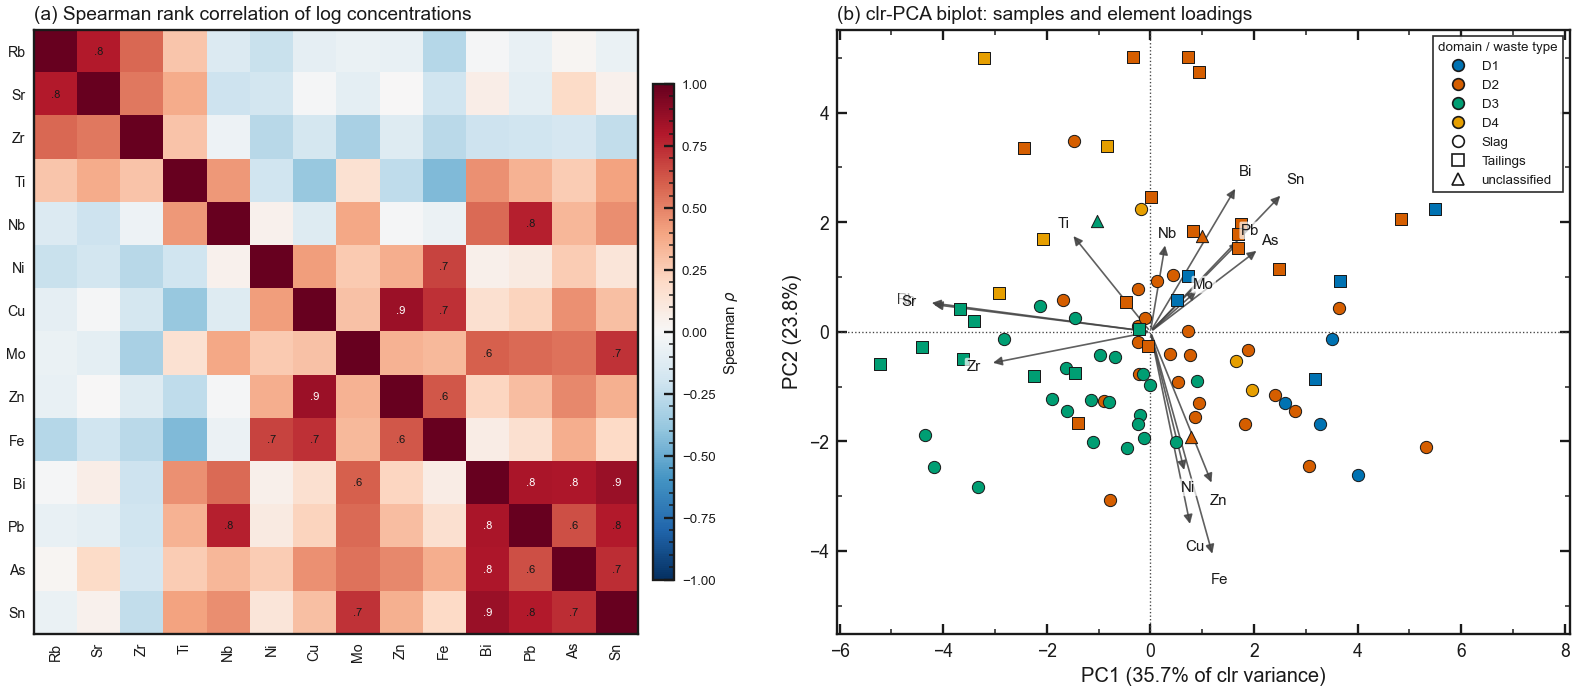

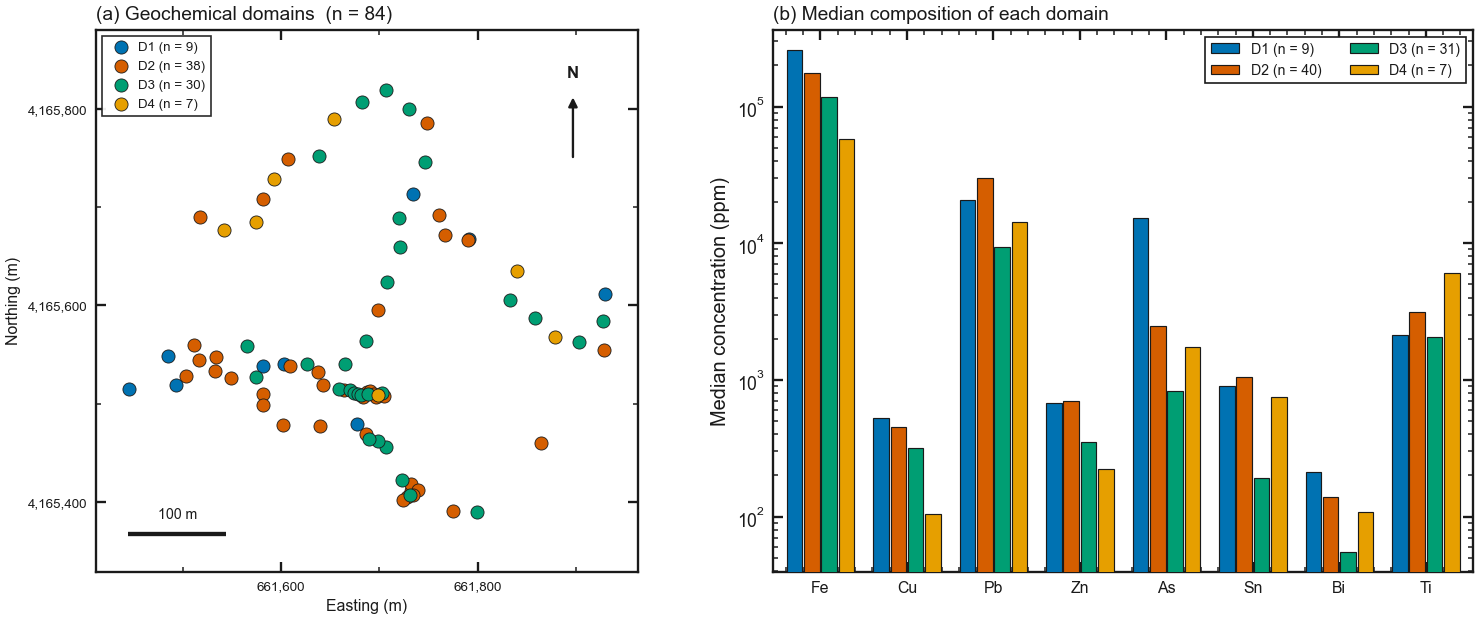


Saved: XRF_PartB_Tab16_clr_pca_loadings.csv, XRF_PartB_Tab16b_spearman_matrix.csv, XRF_PartB_Tab17_domain_profiles.csv, XRF_PartB_Fig14_associations_pca.png, XRF_PartB_Fig15_domains.png


In [30]:
A_ASSOC_ELEMENTS = [e for e in A_USABLE
                    if ELEMENT_QC.loc[e, "detection_pct"] >= A_MIN_INDEX_DETECT and A_UCC.get(e)]
print("MULTIVARIATE ANALYSIS")
print("-" * 78)
print(f"  Elements used ({len(A_ASSOC_ELEMENTS)}): {', '.join(A_ASSOC_ELEMENTS)}")
print(f"  Excluded: class C elements and anything detected in < {A_MIN_INDEX_DETECT}% of samples.")

a_X = SAMPLES[A_ASSOC_ELEMENTS].astype(float).copy()
a_missing = int(a_X.isna().sum().sum())
for e in A_ASSOC_ELEMENTS:                       # half the smallest detected value
    a_X[e] = a_X[e].fillna(max(a_X[e].min(skipna=True) / 2.0, 1e-6))
a_X = a_X.clip(lower=1e-6)
print(f"  Substituted cells (half lowest detected value): {a_missing} of {a_X.size} "
      f"({100 * a_missing / a_X.size:.1f}%)")

# Spearman rank correlation
SPEARMAN = np.log10(a_X).corr(method="spearman")

# clr transform and PCA by SVD
a_ln = np.log(a_X.to_numpy())
a_clr = a_ln - a_ln.mean(axis=1, keepdims=True)
a_clr_c = a_clr - a_clr.mean(axis=0, keepdims=True)
a_U, a_S, a_Vt = np.linalg.svd(a_clr_c, full_matrices=False)
a_var = (a_S ** 2) / max(len(a_clr_c) - 1, 1)
a_expl = 100 * a_var / a_var.sum()
a_ncomp = int(min(len(a_S) - 1, 6))              # clr is rank-deficient by one
a_scores = a_U[:, :a_ncomp] * a_S[:a_ncomp]
a_load = a_Vt[:a_ncomp].T

PCA_SCORES = pd.DataFrame(a_scores, index=SAMPLES.index,
                          columns=[f"PC{i+1}" for i in range(a_ncomp)])
PCA_LOADINGS = pd.DataFrame(a_load, index=A_ASSOC_ELEMENTS,
                            columns=[f"PC{i+1}" for i in range(a_ncomp)])
PCA_LOADINGS.loc["_explained_variance_pct"] = a_expl[:a_ncomp]

print(f"\n  Explained variance: " + ", ".join(f"PC{i+1} {a_expl[i]:.1f}%" for i in range(min(4, a_ncomp))) +
      f"  (PC1-PC{min(3, a_ncomp)} together {a_expl[:min(3, a_ncomp)].sum():.1f}%)")
print("\n  clr-PCA LOADINGS (element contribution to each component)")
print("  " + "-" * 74)
for i in range(min(3, a_ncomp)):
    s = PCA_LOADINGS.iloc[:-1][f"PC{i+1}"].sort_values()
    neg = ", ".join(f"{e} ({v:+.2f})" for e, v in s.head(4).items())
    pos = ", ".join(f"{e} ({v:+.2f})" for e, v in s.tail(4)[::-1].items())
    print(f"  PC{i+1} ({a_expl[i]:.1f}%)  positive: {pos}")
    print(f"             negative: {neg}")

# strongest associations
a_pairs = []
for i, e1 in enumerate(A_ASSOC_ELEMENTS):
    for e2 in A_ASSOC_ELEMENTS[i + 1:]:
        a_pairs.append((e1, e2, float(SPEARMAN.loc[e1, e2])))
a_pairs.sort(key=lambda t: -abs(t[2]))
print("\n  STRONGEST RANK ASSOCIATIONS (Spearman rho on log concentrations)")
print("  " + "-" * 74)
for e1, e2, r in a_pairs[:10]:
    print(f"    {e1:>3} - {e2:<3}  rho = {r:+.2f}   {'positive' if r > 0 else 'inverse'} association")

# k-means on the retained scores
a_keep = max(2, int(np.searchsorted(np.cumsum(a_expl[:a_ncomp]), 80) + 1))
a_keep = min(a_keep, a_ncomp)
a_Z = a_scores[:, :a_keep]
a_Z = (a_Z - a_Z.mean(axis=0)) / a_Z.std(axis=0, ddof=0)

a_rng = np.random.default_rng(A_RANDOM_STATE)
a_k = min(A_N_DOMAINS, len(a_Z))
a_cent = a_Z[a_rng.choice(len(a_Z), size=1)]                      # k-means++ seeding
while len(a_cent) < a_k:
    d2 = ((a_Z[:, None, :] - a_cent[None, :, :]) ** 2).sum(axis=2).min(axis=1)
    p = d2 / d2.sum() if d2.sum() > 0 else np.full(len(a_Z), 1 / len(a_Z))
    a_cent = np.vstack([a_cent, a_Z[a_rng.choice(len(a_Z), p=p)]])
for _ in range(200):
    a_lab = ((a_Z[:, None, :] - a_cent[None, :, :]) ** 2).sum(axis=2).argmin(axis=1)
    new = np.array([a_Z[a_lab == j].mean(axis=0) if (a_lab == j).any() else a_cent[j] for j in range(a_k)])
    if np.allclose(new, a_cent):
        break
    a_cent = new

# order domains by decreasing metal tenor so "Domain 1" is the richest
a_metal = [e for e in ["Cu", "Pb", "Zn", "As", "Sb"] if e in A_ASSOC_ELEMENTS] or A_ASSOC_ELEMENTS[:3]
a_rank = np.array([np.nanmedian(np.log10(a_X.loc[a_lab == j, a_metal]).mean(axis=1)) for j in range(a_k)])
a_order_d = np.argsort(-a_rank)
a_remap = {old: new + 1 for new, old in enumerate(a_order_d)}
SAMPLES["domain"] = [f"D{a_remap[j]}" for j in a_lab]
CONTAMINATION["domain"] = SAMPLES["domain"]

a_prof = []
for d in sorted(SAMPLES["domain"].unique()):
    sub = SAMPLES[SAMPLES["domain"] == d]
    row = {"domain": d, "n_samples": len(sub),
           "waste_types": ", ".join(f"{k} {v}" for k, v in sub["waste_type"].value_counts().items()) or "unclassified",
           "median_PLI": float(pd.to_numeric(CONTAMINATION.loc[sub.index, "PLI"], errors="coerce").median()),
           "median_RI": float(pd.to_numeric(CONTAMINATION.loc[sub.index, "RI"], errors="coerce").median())}
    ratios = {e: float(sub[e].median(skipna=True) / SAMPLES[e].median(skipna=True))
              for e in A_ASSOC_ELEMENTS if np.isfinite(SAMPLES[e].median(skipna=True)) and SAMPLES[e].median(skipna=True) > 0}
    top = sorted(ratios.items(), key=lambda t: -t[1])[:4]
    low = sorted(ratios.items(), key=lambda t: t[1])[:2]
    row["enriched_in"] = ", ".join(f"{e} x{v:.1f}" for e, v in top if v > 1.15) or "nothing (background domain)"
    row["depleted_in"] = ", ".join(f"{e} x{v:.2f}" for e, v in low if v < 0.85)
    for e in A_ASSOC_ELEMENTS:
        row[f"median_{e}"] = float(sub[e].median(skipna=True))
    a_prof.append(row)
DOMAIN_PROFILE = pd.DataFrame(a_prof)

print(f"\n\nGEOCHEMICAL DOMAINS  (k-means, k = {a_k}, on {a_keep} clr-PCA components = "
      f"{np.cumsum(a_expl)[a_keep-1]:.0f}% of variance)")
print("=" * 108)
for _, r in DOMAIN_PROFILE.iterrows():
    print(f"\n  {r['domain']}  n = {r['n_samples']:<3}  ({r['waste_types']})")
    print(f"      enriched in : {r['enriched_in']}")
    if r["depleted_in"]:
        print(f"      depleted in : {r['depleted_in']}")
    print(f"      median PLI = {r['median_PLI']:,.0f}   median RI = {r['median_RI']:,.0f}")
print("\n  Domain numbers run from the highest to the lowest base-metal tenor. k-means always returns the number")
print(f"  of groups it is given ({a_k} here, set by A_N_DOMAINS): treat the domains as a description to be")
print("  checked against field observation and mineralogy, not as a classification with a statistical claim.")

# figure: correlation heatmap + clr-PCA biplot
fig_pc, ax_pc = plt.subplots(1, 2, figsize=(13.4, 6.0))

axp = ax_pc[0]
a_ordc = PCA_LOADINGS.iloc[:-1]["PC1"].sort_values().index.tolist()
a_M = SPEARMAN.loc[a_ordc, a_ordc].to_numpy()
im = axp.imshow(a_M, cmap="RdBu_r", vmin=-1, vmax=1)
axp.set_xticks(range(len(a_ordc))); axp.set_xticklabels(a_ordc, fontsize=8.5, rotation=90)
axp.set_yticks(range(len(a_ordc))); axp.set_yticklabels(a_ordc, fontsize=8.5)
for i in range(len(a_ordc)):
    for j in range(len(a_ordc)):
        if i != j and abs(a_M[i, j]) >= 0.6:
            axp.text(j, i, f"{a_M[i, j]:.1f}".replace("0.", "."), ha="center", va="center",
                     fontsize=6.6, color="white" if abs(a_M[i, j]) > 0.8 else INK)
axp.set_title("(a) Spearman rank correlation of log concentrations", fontsize=11.5, loc="left")
cb = fig_pc.colorbar(im, ax=axp, shrink=0.82, pad=0.02, aspect=24)
cb.set_label(r"Spearman $\rho$", fontsize=9); cb.ax.tick_params(labelsize=8)
for s in axp.spines.values():
    s.set_linewidth(1.4); s.set_color(INK)
axp.tick_params(which="both", length=0)

axp = ax_pc[1]
a_dom_colors = {f"D{i+1}": COLORBLIND_PALETTE[i % len(COLORBLIND_PALETTE)] for i in range(a_k)}
a_mark = {"slag": "o", "tailing": "s", None: "^"}
for d in sorted(SAMPLES["domain"].unique()):
    for wt, mk in a_mark.items():
        m = ((SAMPLES["domain"] == d) &
             (SAMPLES["waste_type"] == wt if wt else SAMPLES["waste_type"].isna())).to_numpy()
        if not m.any():
            continue
        axp.scatter(PCA_SCORES.loc[m, "PC1"], PCA_SCORES.loc[m, "PC2"],
                    c=a_dom_colors[d], marker=mk, s=54, edgecolor=INK, linewidth=0.6, zorder=4)
a_sc_load = 0.78 * float(np.abs(PCA_SCORES[["PC1", "PC2"]].to_numpy()).max()) / \
    max(float(np.abs(a_load[:, :2]).max()), 1e-9)
a_tips = []
for e in A_ASSOC_ELEMENTS:
    lx, ly = PCA_LOADINGS.loc[e, "PC1"] * a_sc_load, PCA_LOADINGS.loc[e, "PC2"] * a_sc_load
    a_tips.append((lx * 1.14, ly * 1.14))
    axp.annotate("", xy=(lx, ly), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="-|>", color=INK_SOFT, lw=1.0, alpha=0.85))
    axp.text(lx * 1.10, ly * 1.10, e, fontsize=9, color=INK, ha="center", va="center", zorder=6,
             bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.7))
axp.axhline(0, color=INK_SOFT, lw=0.8, ls=":"); axp.axvline(0, color=INK_SOFT, lw=0.8, ls=":")
a_tips = np.array(a_tips)
a_lim_x = max(float(np.abs(PCA_SCORES["PC1"]).max()), float(np.abs(a_tips[:, 0]).max())) * 1.10
a_lim_y = max(float(np.abs(PCA_SCORES["PC2"]).max()), float(np.abs(a_tips[:, 1]).max())) * 1.10
axp.set_xlim(-a_lim_x, a_lim_x * 1.34)          # right margin holds the legend
axp.set_ylim(-a_lim_y, a_lim_y)
axp.set_xlabel(f"PC1 ({a_expl[0]:.1f}% of clr variance)")
axp.set_ylabel(f"PC2 ({a_expl[1]:.1f}%)")
axp.set_title("(b) clr-PCA biplot: samples and element loadings", fontsize=11.5, loc="left")
a_handles = [plt.Line2D([], [], ls="", marker="o", ms=7, mfc=a_dom_colors[d], mec=INK, label=d)
             for d in sorted(SAMPLES["domain"].unique())]
a_handles += [plt.Line2D([], [], ls="", marker=mk, ms=7, mfc="white", mec=INK,
                         label=WASTE_LABEL.get(wt, "unclassified"))
              for wt, mk in a_mark.items()
              if (SAMPLES["waste_type"] == wt if wt else SAMPLES["waste_type"].isna()).any()]
axp.legend(handles=a_handles, loc="upper right", fontsize=8, framealpha=0.92,
           title="domain / waste type", title_fontsize=8)
style_frame(axp, xminor=2, yminor=2)

fig_pc.tight_layout()
fig_pc.savefig(A_OUT / f"{A_PREFIX}_Fig14_associations_pca.png", dpi=DPI_HIGHRES, bbox_inches="tight")
plt.show()

# figure: domain map + domain profiles
fig_dm, ax_dm = plt.subplots(1, 2, figsize=(13.0, 5.4))
a_map_panel(fig_dm, ax_dm[0], SAMPLES["domain"], "(a) Geochemical domains", "",
            discrete=a_dom_colors)
axd = ax_dm[1]
a_pel = [e for e in ["Fe", "Cu", "Pb", "Zn", "As", "Sb", "Sn", "Bi", "Ti", "Mn"] if e in A_ASSOC_ELEMENTS]
a_w2 = 0.8 / max(len(DOMAIN_PROFILE), 1)
for j, (_, r) in enumerate(DOMAIN_PROFILE.iterrows()):
    axd.bar(np.arange(len(a_pel)) + j * a_w2 - 0.4 + a_w2 / 2,
            [r[f"median_{e}"] for e in a_pel], width=a_w2 * 0.9,
            color=a_dom_colors[r["domain"]], edgecolor=INK, linewidth=0.7,
            label=f"{r['domain']} (n = {r['n_samples']})", zorder=3)
axd.set_xticks(range(len(a_pel))); axd.set_xticklabels(a_pel, fontsize=9.5)
axd.set_ylabel("Median concentration (ppm)")
style_log_yaxis(axd); style_frame(axd, xminor=None, yminor=None)
axd.set_title("(b) Median composition of each domain", fontsize=11.5, loc="left")
axd.legend(loc="upper right", fontsize=8.5, ncol=2)
fig_dm.tight_layout()
fig_dm.savefig(A_OUT / f"{A_PREFIX}_Fig15_domains.png", dpi=DPI_HIGHRES, bbox_inches="tight")
plt.show()

PCA_LOADINGS.to_csv(A_OUT / f"{A_PREFIX}_Tab16_clr_pca_loadings.csv", encoding="utf-8-sig")
SPEARMAN.round(3).to_csv(A_OUT / f"{A_PREFIX}_Tab16b_spearman_matrix.csv", encoding="utf-8-sig")
DOMAIN_PROFILE.to_csv(A_OUT / f"{A_PREFIX}_Tab17_domain_profiles.csv", index=False, encoding="utf-8-sig")
print(f"\nSaved: {A_PREFIX}_Tab16_clr_pca_loadings.csv, {A_PREFIX}_Tab16b_spearman_matrix.csv, "
      f"{A_PREFIX}_Tab17_domain_profiles.csv, {A_PREFIX}_Fig14_associations_pca.png, "
      f"{A_PREFIX}_Fig15_domains.png")

## 15 · Critical raw materials: re-mining and reprocessing screening

**Why this section exists.** Regulation (EU) 2024/1252 (the Critical Raw Materials Act) treats extractive waste as
a domestic source of critical and strategic raw materials. Article 27 places concrete duties on operators and
Member States: closed and abandoned facilities must be inventoried in a national database, characterised with
representative geochemical sampling and then with detailed chemical and mineralogical analysis, and operators of
active facilities must produce a **preliminary economic assessment** of the recovery potential of the critical raw
materials in their waste. The Act's 2030 benchmarks — at least 10 % of EU annual consumption from domestic
extraction, 40 % processed in the EU, 25 % from recycling, and no more than 65 % of any strategic raw material at
any processing stage from a single third country — are what make a legacy facility in the Iberian Pyrite Belt
worth assessing rather than only remediating.

**What this screening is.** A defensible ranking of the measured elements into: (i) critical or strategic under the
Act, (ii) supported by the pXRF data at the quality level established in §11, (iii) present at grades that would
justify metallurgical testwork in a polymetallic setting, and (iv) accompanied by penalty elements that would
travel with any concentrate. It also reports the contained metal implied by the grades, so that the order of
magnitude of any recovery is explicit.

**What this screening is not.** It is not a resource estimate and it is not an economic assessment.

| Missing element | Why it matters | Where it is addressed |
|---|---|---|
| Tonnage, density, geometry, depth | Grade without tonnage is not a resource; surface pXRF says nothing about the third dimension | §16, Stage 3 |
| Laboratory assays | pXRF is a screening method; grades must be confirmed by ICP-MS/ICP-OES after total digestion, and Au/PGE by fire assay | §16, Stage 1 |
| Mineralogical deportment | A grade is recoverable only if the metal sits in a liberatable phase. Metal locked in slag glass or in a refractory sulphosalt is not recoverable by flotation at any grade | §16, Stage 1 and 4 |
| Metallurgical recovery | Recovery, concentrate grade and reagent consumption decide the economics, not the head grade | §16, Stage 4 |
| Cost, price, permitting | A preliminary economic assessment under Article 27(1) needs all of the above | §16, Stage 5 |

**The two materials behave differently and must not be pooled.** Processing tailings are already milled and partly
oxidised: they are amenable to re-flotation, leaching or bioleaching, and their fine grain size is also what makes
them the dust and drainage problem. Smelter slag is a quenched silicate glass in which residual metal is commonly
held in the glass matrix or as entrained sulphide or metallic prills: recovery requires comminution and either
physical separation of the prills or a pyrometallurgical route, and the glass matrix is also what keeps much of
its metal immobile. The screening below therefore reports slag and tailings separately throughout.

**Indicative grades.** `A_CRM_INTEREST` in §10 holds the grade at which each element is normally considered worth a
metallurgical test in a polymetallic setting. These are screening thresholds only: they are not cut-off grades,
they carry no economic meaning, and they should be replaced by project-specific values as soon as recovery and
cost assumptions exist.

CRITICAL AND STRATEGIC RAW MATERIALS MEASURED IN THIS DATASET
  Status under Regulation (EU) 2024/1252 - verify against the consolidated Annexes I and II before quoting.

SLAG  (n = 53 samples)
  El  status                           cls    det %     median        P90         max     x bkg   target  % above  verdict
  --------------------------------------------------------------------------------------------------------------------
  Ti  CRM (titanium metal: SRM)        A         98    2,046.2    5,968.8    11,667.6      0.5x   20,000        0  below indicative grade
  As  CRM                              A        100    1,632.5    4,506.3    41,478.5      340x        -        -  hazard-led - a CRM, but treated here as a penalty element
  Cu  CRM + SRM                        A        100      449.0    1,045.0     3,083.9     16.0x    2,000        4  below indicative grade
  Ni  CRM (battery grade: SRM)         A         91      115.8      212.2       414.2     2.50x    1,000        0  

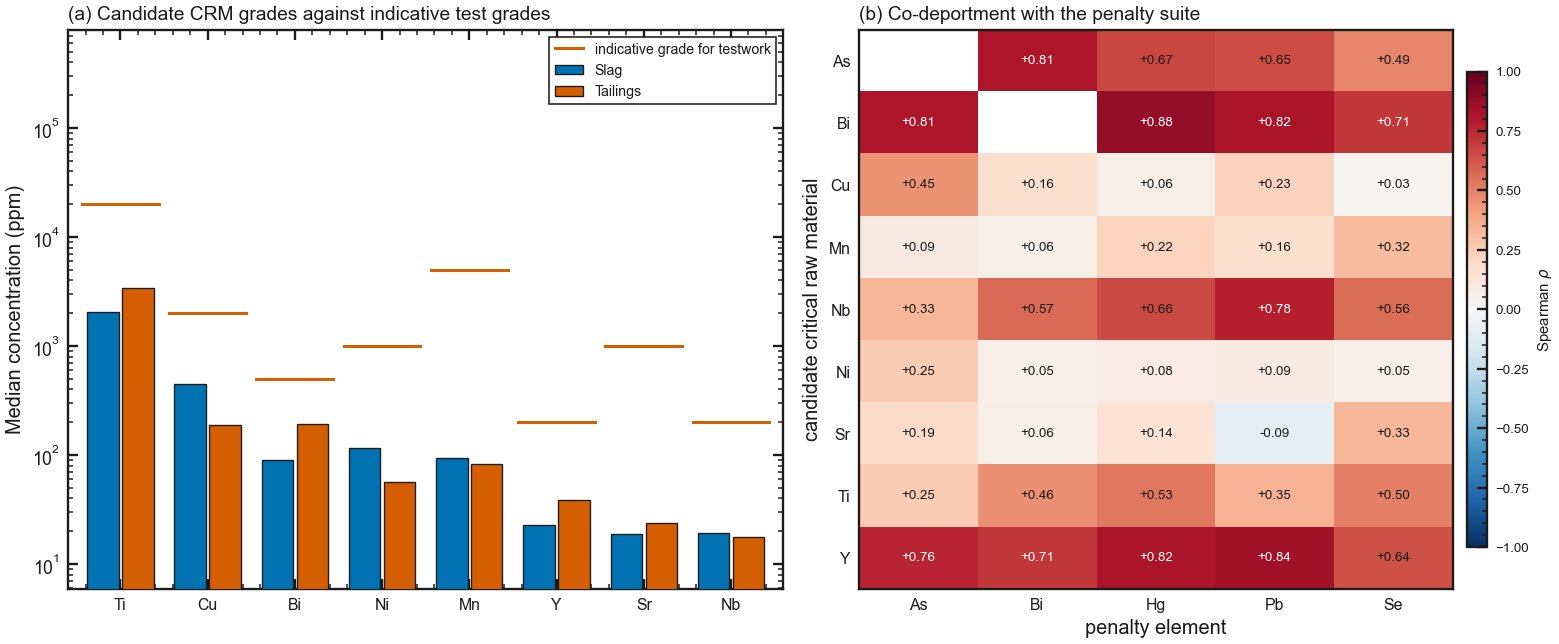



COMPOSITE SCREENING SCORE built from Bi, As, Cu, Ni (log concentration, min-max scaled, arithmetic mean).
  It ranks samples by how strongly they carry the defensible critical raw materials TOGETHER. It is an
  ordinal screening aid for targeting the next sampling round, not a grade and not a value.
  Highest-scoring samples:
   LMW21      score 0.83   tailing   Bi 1,076  As 193,453  Cu 967  Ni 77
   MM27       score 0.79   slag   Bi 871  As 41,478  Cu 325  Ni 195
   LMW15      score 0.78   tailing   Bi 1,010  As 39,961  Cu 402  Ni 128
   MM28       score 0.78   slag   Bi 690  As 19,932  Cu 3,084  Ni 60
   LA247      score 0.76   slag   Bi 138  As 4,554  Cu 1,839  Ni 414


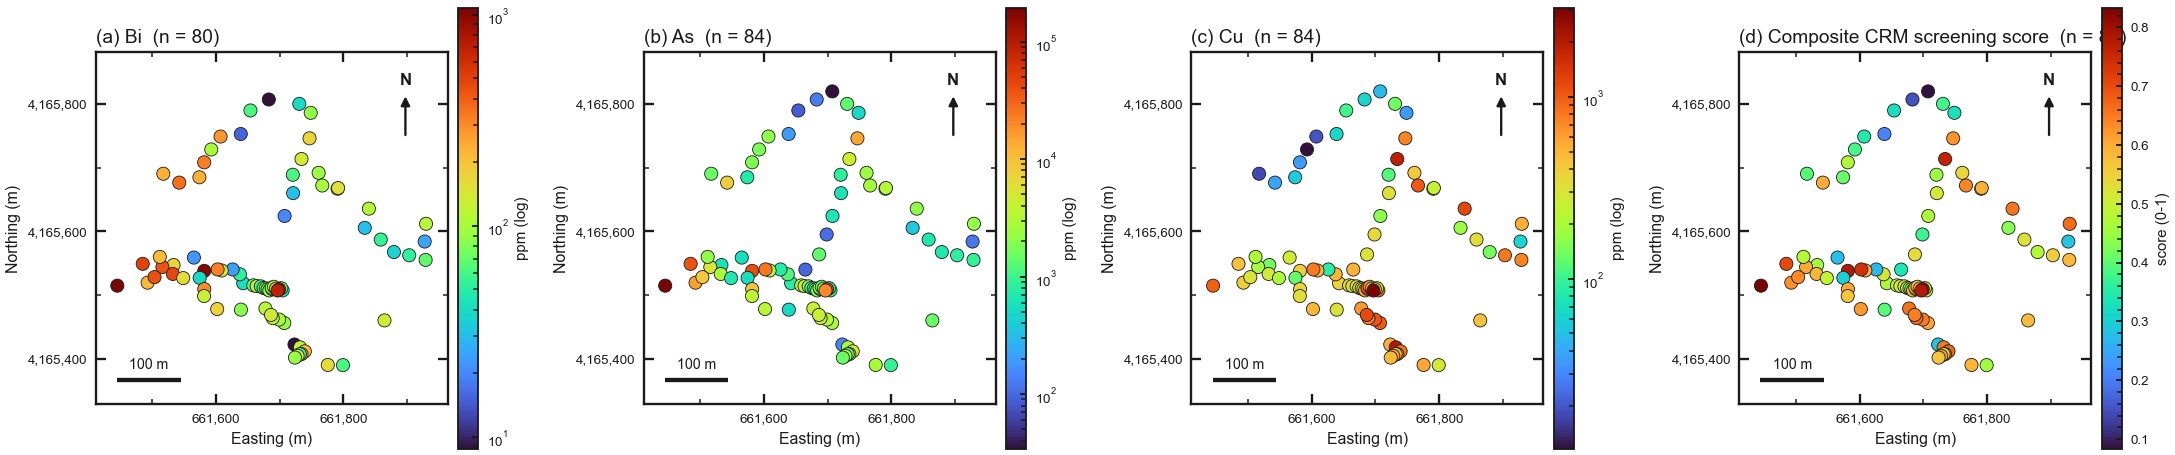


Saved: XRF_PartB_Tab18_crm_screening.csv, XRF_PartB_Tab19_contained_metal.csv, XRF_PartB_Tab20_penalty_elements.csv, XRF_PartB_Tab20b_co_deportment.csv, XRF_PartB_Fig16_crm_screening.png, XRF_PartB_Fig17_crm_maps.png


In [31]:
A_CRM_MEASURED = [e for e in A_CRM_ELEMENTS if e in SAMPLES.columns]
A_CRM_DEFENSIBLE = [e for e in A_CRM_MEASURED if e in A_USABLE]
A_CRM_REJECTED = [e for e in A_CRM_MEASURED if e not in A_USABLE]

a_rows = []
for e in A_CRM_MEASURED:
    for wt in ["slag", "tailing", "all"]:
        sub = SAMPLES if wt == "all" else SAMPLES[SAMPLES["waste_type"] == wt]
        v = sub[e].dropna()
        if v.empty:
            continue
        thr = A_CRM_INTEREST.get(e)
        cls = ELEMENT_QC.loc[e, "reliability_class"]
        cap = A_MAX_CREDIBLE.get(e)
        pct_above = 100.0 * float((v >= thr).mean()) if thr else np.nan
        if cls == "C":
            verdict = ("not defensible - probable artefact (§11)" if e in A_ARTEFACT
                       else "not defensible - imprecise, confirm by assay (§11)")
        elif thr is None:
            verdict = ("hazard-led - a CRM, but treated here as a penalty element" if e in A_PENALTY
                       else "no indicative grade set")
        elif v.median() >= thr:
            verdict = "priority - median above indicative grade"
        elif v.quantile(0.90) >= thr:
            verdict = "local interest - upper decile above"
        else:
            verdict = "below indicative grade"
        if cls != "C" and cap is not None and float(v.quantile(0.90)) > cap:
            verdict += "; upper decile exceeds the credible maximum - check line overlap"
        a_rows.append({"element": e, "waste_type": wt, "crm_status": A_CRM_STATUS.get(e, "-"),
                       "reliability_class": cls, "n_detected": len(v),
                       "detection_pct": round(100 * len(v) / len(sub), 1),
                       "median_ppm": v.median(), "p90_ppm": v.quantile(0.90), "max_ppm": v.max(),
                       "x_background": round(float(v.median()) / A_UCC[e], 1) if A_UCC.get(e) else np.nan,
                       "indicative_grade_ppm": thr,
                       "pct_samples_above": round(pct_above, 1) if np.isfinite(pct_above) else np.nan,
                       "verdict": verdict})
CRM_SCREEN = pd.DataFrame(a_rows)


def a_num(v, width, unit=""):
    """Compact fixed-width number: keeps one or two decimals below 10 so that a
    sub-unity enrichment factor never prints as '0'."""
    if v is None or not np.isfinite(v):
        return f"{'-' + unit:>{width}}"
    if abs(v) >= 100:
        s = f"{v:,.0f}"
    elif abs(v) >= 10:
        s = f"{v:,.1f}"
    elif abs(v) >= 1:
        s = f"{v:,.2f}"
    else:
        s = f"{v:,.3f}".rstrip("0").rstrip(".") or "0"
    return f"{s + unit:>{width}}"


print("CRITICAL AND STRATEGIC RAW MATERIALS MEASURED IN THIS DATASET")
print("=" * 118)
print("  Status under Regulation (EU) 2024/1252 - verify against the consolidated Annexes I and II before quoting.")
for wt in ["slag", "tailing"]:
    sub = CRM_SCREEN[(CRM_SCREEN["waste_type"] == wt)].copy()
    if sub.empty:
        continue
    sub["_srt"] = sub["reliability_class"].map({"A": 0, "B": 1, "C": 2})
    sub = sub.sort_values(["_srt", "median_ppm"], ascending=[True, False])
    print(f"\n{WASTE_LABEL.get(wt, wt).upper()}  (n = {int((SAMPLES['waste_type'] == wt).sum())} samples)")
    print(f"  {'El':<4}{'status':<33}{'cls':<5}{'det %':>7}{'median':>11}{'P90':>11}{'max':>12}"
          f"{'x bkg':>10}{'target':>9}{'% above':>9}  verdict")
    print("  " + "-" * 116)
    for _, r in sub.iterrows():
        st = r["crm_status"] if len(r["crm_status"]) <= 32 else r["crm_status"][:31] + "."
        pab = f"{r['pct_samples_above']:.0f}" if np.isfinite(r["pct_samples_above"]) else "-"
        print(f"  {r['element']:<4}{st:<33}{r['reliability_class']:<5}"
              f"{r['detection_pct']:>7.0f}{r['median_ppm']:>11,.1f}{r['p90_ppm']:>11,.1f}{r['max_ppm']:>12,.1f}"
              f"{a_num(r['x_background'], 10, 'x')}{a_num(r['indicative_grade_ppm'], 9)}{pab:>9}  {r['verdict']}")

a_crm_artefact = [e for e in A_CRM_REJECTED if e in A_ARTEFACT]
a_crm_imprecise = [e for e in A_CRM_REJECTED if e not in A_ARTEFACT]
print(f"\n  Defensible for a screening statement (class A/B): {', '.join(A_CRM_DEFENSIBLE) or 'none'}")
print(f"  NOT defensible without laboratory confirmation   : {', '.join(A_CRM_REJECTED) or 'none'}")
if a_crm_artefact:
    print(f"\n  (i)  Probable analytical artefacts: {', '.join(a_crm_artefact)}. Their concentrations are not")
    print("       geologically credible for a Pb-As-Cu-Zn-Fe matrix and their principal lines sit on Cu, Zn, Pb,")
    print("       Bi or the tube anode (§11). They are NOT evidence of a critical-raw-material occurrence and")
    print("       must not be presented as one; laboratory assay is expected to remove them.")
if a_crm_imprecise:
    print(f"\n  (ii) Real but imprecise here: {', '.join(a_crm_imprecise)}. These are geologically expected in")
    print("       Iberian Pyrite Belt material - antimony in particular is hosted by the tetrahedrite-tennantite")
    print("       group and is a recognised by-product of this ore type - but the pXRF counting statistics are")
    print("       too poor to quantify them. They are the elements most likely to be CONFIRMED by ICP-MS, and")
    print("       the sampling programme in §16 should be designed so that they can be.")

# contained metal
a_base_t = A_TONNAGE_T
if a_base_t is None and A_VOLUME_M3 and A_BULK_DENSITY:
    a_base_t = A_VOLUME_M3 * A_BULK_DENSITY
a_cm = []
for e in A_CRM_DEFENSIBLE:
    for wt in ["slag", "tailing", "all"]:
        sub = SAMPLES if wt == "all" else SAMPLES[SAMPLES["waste_type"] == wt]
        v = sub[e].dropna()
        if v.empty:
            continue
        g = float(v.median())
        row = {"element": e, "waste_type": wt, "median_grade_ppm": g,
               "kg_per_1000t": g,                       # 1 ppm = 1 g/t -> 1 kg per 1,000 t
               "t_per_Mt": g}                           # and 1 t per Mt
        if a_base_t:
            row["tonnage_t"] = a_base_t
            row["contained_metal_t"] = g * 1e-6 * a_base_t
        a_cm.append(row)
CONTAINED_METAL = pd.DataFrame(a_cm)

print("\n\nCONTAINED METAL IMPLIED BY THE MEDIAN GRADES")
print("=" * 118)
if a_base_t:
    print(f"  Tonnage supplied in §10: {a_base_t:,.0f} t")
else:
    print("  No tonnage supplied in §10 (A_TONNAGE_T): contained metal is reported per 1,000 t of waste.")
    print("  1 ppm = 1 g/t, so 1 ppm in 1,000 t is 1 kg of metal, and 1 ppm in 1 Mt is 1 t of metal.")
for wt in ["slag", "tailing"]:
    sub = CONTAINED_METAL[CONTAINED_METAL["waste_type"] == wt].sort_values("median_grade_ppm", ascending=False)
    if sub.empty:
        continue
    print(f"\n  {WASTE_LABEL.get(wt, wt).upper()}")
    hdr = f"  {'El':<4}{'median grade (ppm)':>20}{'kg per 1,000 t':>17}"
    if a_base_t:
        hdr += f"{'contained metal (t)':>22}"
    print(hdr)
    print("  " + "-" * (len(hdr) - 2))
    for _, r in sub.iterrows():
        line = f"  {r['element']:<4}{r['median_grade_ppm']:>20,.1f}{r['kg_per_1000t']:>17,.1f}"
        if a_base_t:
            line += f"{r['contained_metal_t']:>22,.1f}"
        print(line)
print("\n  These are CONTAINED figures at the measured head grade: they assume 100 % recovery and are an upper")
print("  bound on what any process could deliver. Recoveries in reprocessing of oxidised tailings and of slag")
print("  are commonly well below half of the contained metal, and are set by mineralogy, not by grade.")

# penalty elements and co-deportment
a_pen = []
for e, thr in A_PENALTY.items():
    if e not in SAMPLES.columns or e not in A_USABLE:
        continue
    for wt in ["slag", "tailing"]:
        v = SAMPLES.loc[SAMPLES["waste_type"] == wt, e].dropna()
        if v.empty:
            continue
        a_pen.append({"element": e, "waste_type": wt, "penalty_threshold_ppm": thr,
                      "median_ppm": v.median(), "p90_ppm": v.quantile(0.90), "max_ppm": v.max(),
                      "pct_above_threshold": round(100 * float((v > thr).mean()), 1),
                      "flag": "exceeds in most samples" if v.median() > thr else
                              ("exceeds in some samples" if (v > thr).any() else "below threshold")})
PENALTY_SCREEN = pd.DataFrame(a_pen)

a_pen_el = sorted(PENALTY_SCREEN["element"].unique()) if not PENALTY_SCREEN.empty else []
a_co = []
for e in A_CRM_DEFENSIBLE:
    row = {"crm_element": e}
    for p in a_pen_el:
        if p == e:
            row[f"rho_{p}"] = np.nan
        elif e in SPEARMAN.index and p in SPEARMAN.columns:
            row[f"rho_{p}"] = round(float(SPEARMAN.loc[e, p]), 2)
        else:
            both = SAMPLES[[e, p]].dropna()
            row[f"rho_{p}"] = round(float(np.log10(both[e]).corr(np.log10(both[p]), method="spearman")), 2) \
                if len(both) > 5 else np.nan
    pairs = [(k[4:], v) for k, v in row.items()
             if k.startswith("rho_") and isinstance(v, float) and np.isfinite(v)]
    vals = [v for _, v in pairs]
    row["max_rho_with_penalty"] = max(vals) if vals else np.nan
    row["closest_penalty_element"] = max(pairs, key=lambda t: t[1])[0] if pairs else "-"
    row["separation_outlook"] = ("co-deported - separation is the metallurgical question"
                                 if vals and max(vals) >= 0.6 else
                                 ("partly independent" if vals and max(vals) >= 0.3 else
                                  "largely independent of the penalty suite"))
    # a strong correlation with an element that overlaps the same line can be spectral, not mineralogical
    overlaps = A_LINES.loc[e, "overlapping_lines_in_this_matrix"] if e in A_LINES.index else ""
    row["caution"] = ("high rho with " + row["closest_penalty_element"] +
                      " may be a line overlap, not co-deportment"
                      if vals and max(vals) >= 0.6 and row["closest_penalty_element"] in overlaps else "")
    a_co.append(row)
CO_DEPORTMENT = pd.DataFrame(a_co)

print("\n\nPENALTY ELEMENTS (thresholds are placeholders - replace with the relevant offtake terms)")
print("=" * 118)
if not PENALTY_SCREEN.empty:
    print(PENALTY_SCREEN.round({"median_ppm": 0, "p90_ppm": 0, "max_ppm": 0}).to_string(index=False))
else:
    print("  No defensible penalty element measured.")
print("\n\nCO-DEPORTMENT OF THE CANDIDATE CRMs WITH THE PENALTY SUITE (Spearman rho on log concentrations)")
print("=" * 118)
if not CO_DEPORTMENT.empty:
    print(CO_DEPORTMENT.drop(columns=["caution"]).to_string(index=False))
    print("\n  A high positive rho means the two elements sit in the same samples and probably in the same or")
    print("  intergrown phases: a concentrate carrying the critical raw material would carry the penalty element")
    print("  as well, and the project stands or falls on the separation step, not on the head grade.")
    a_caut = CO_DEPORTMENT[CO_DEPORTMENT["caution"] != ""]
    for _, r in a_caut.iterrows():
        print(f"  CAUTION - {r['crm_element']}: {r['caution']} "
              f"({A_LINES.loc[r['crm_element'], 'line']} at "
              f"{A_LINES.loc[r['crm_element'], 'energy_keV']} keV overlaps "
              f"{A_LINES.loc[r['crm_element'], 'overlapping_lines_in_this_matrix']}).")

# figure: grades against indicative thresholds, and co-deportment 
a_cand = [e for e in A_CRM_DEFENSIBLE if A_CRM_INTEREST.get(e)]
fig_cr, ax_cr = plt.subplots(1, 2, figsize=(13.4, 5.6))

axc = ax_cr[0]
if a_cand:
    a_ordm = (CRM_SCREEN[(CRM_SCREEN["waste_type"] == "all") & (CRM_SCREEN["element"].isin(a_cand))]
              .sort_values("median_ppm", ascending=False)["element"].tolist())
    a_wts2 = [wt for wt in ["slag", "tailing"] if (SAMPLES["waste_type"] == wt).any()]
    a_w3 = 0.8 / max(len(a_wts2), 1)
    for j, wt in enumerate(a_wts2):
        sub = (CRM_SCREEN[(CRM_SCREEN["waste_type"] == wt)].set_index("element").reindex(a_ordm))
        axc.bar(np.arange(len(a_ordm)) + j * a_w3 - 0.4 + a_w3 / 2, sub["median_ppm"].to_numpy(),
                width=a_w3 * 0.9, color=COLORBLIND_PALETTE[j], edgecolor=INK, linewidth=0.8,
                label=WASTE_LABEL.get(wt, wt), zorder=3)
    for i, e in enumerate(a_ordm):
        thr = A_CRM_INTEREST.get(e)
        if thr:
            axc.plot([i - 0.44, i + 0.44], [thr, thr], color="#D55E00", lw=1.8, zorder=6)
    axc.plot([], [], color="#D55E00", lw=1.8, label="indicative grade for testwork")
    axc.set_xticks(range(len(a_ordm))); axc.set_xticklabels(a_ordm, fontsize=9.5)
    axc.set_ylabel("Median concentration (ppm)")
    style_log_yaxis(axc); style_frame(axc, xminor=None, yminor=None)
    a_hi = max([A_CRM_INTEREST[e] for e in a_ordm if A_CRM_INTEREST.get(e)] +
               [float(CRM_SCREEN.loc[CRM_SCREEN["element"].isin(a_ordm), "median_ppm"].max())])
    a_lo = float(CRM_SCREEN.loc[CRM_SCREEN["element"].isin(a_ordm), "median_ppm"].min())
    axc.set_ylim(max(a_lo / 3.0, 1e-3), a_hi * 40)
    axc.set_xlim(-0.6, len(a_ordm) - 0.4)
    axc.set_title("(a) Candidate CRM grades against indicative test grades", fontsize=11.5, loc="left")
    axc.legend(loc="upper right", fontsize=8.5, framealpha=0.95)
else:
    axc.axis("off"); axc.text(0.5, 0.5, "no defensible CRM with an indicative grade", ha="center", va="center")

axc = ax_cr[1]
if not CO_DEPORTMENT.empty and a_pen_el:
    a_Mc = CO_DEPORTMENT.set_index("crm_element")[[f"rho_{p}" for p in a_pen_el]].astype(float)
    imc = axc.imshow(a_Mc.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    axc.set_xticks(range(len(a_pen_el))); axc.set_xticklabels(a_pen_el, fontsize=9.5)
    axc.set_yticks(range(len(a_Mc))); axc.set_yticklabels(a_Mc.index, fontsize=9.5)
    for i in range(a_Mc.shape[0]):
        for j in range(a_Mc.shape[1]):
            val = a_Mc.to_numpy()[i, j]
            if np.isfinite(val):
                axc.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=8,
                         color="white" if abs(val) > 0.7 else INK)
    axc.set_xlabel("penalty element"); axc.set_ylabel("candidate critical raw material")
    axc.set_title("(b) Co-deportment with the penalty suite", fontsize=11.5, loc="left")
    cbc = fig_cr.colorbar(imc, ax=axc, shrink=0.85, pad=0.02, aspect=24)
    cbc.set_label(r"Spearman $\rho$", fontsize=9); cbc.ax.tick_params(labelsize=8)
    for s in axc.spines.values():
        s.set_linewidth(1.4); s.set_color(INK)
    axc.tick_params(which="both", length=0)
else:
    axc.axis("off"); axc.text(0.5, 0.5, "no penalty element to compare", ha="center", va="center")

fig_cr.tight_layout()
fig_cr.savefig(A_OUT / f"{A_PREFIX}_Fig16_crm_screening.png", dpi=DPI_HIGHRES, bbox_inches="tight")
plt.show()

# composite screening score and maps
a_top = (CRM_SCREEN[(CRM_SCREEN["waste_type"] == "all") & (CRM_SCREEN["element"].isin(A_CRM_DEFENSIBLE))]
         .sort_values("x_background", ascending=False)["element"].tolist())[:4]
if a_top:
    a_norm = pd.DataFrame(index=SAMPLES.index)
    for e in a_top:
        lv = np.log10(SAMPLES[e].where(SAMPLES[e] > 0))
        a_norm[e] = (lv - lv.min()) / (lv.max() - lv.min()) if np.isfinite(lv.max() - lv.min()) and \
            (lv.max() - lv.min()) > 0 else 0.0
    SAMPLES["crm_score"] = a_norm.mean(axis=1, skipna=True)
    print(f"\n\nCOMPOSITE SCREENING SCORE built from {', '.join(a_top)} (log concentration, min-max scaled, "
          "arithmetic mean).")
    print("  It ranks samples by how strongly they carry the defensible critical raw materials TOGETHER. It is an")
    print("  ordinal screening aid for targeting the next sampling round, not a grade and not a value.")
    print("  Highest-scoring samples:")
    for k, v in SAMPLES["crm_score"].nlargest(5).items():
        print(f"   {k:<10} score {v:.2f}   {SAMPLES.loc[k, 'waste_type'] or 'unclassified'}   " +
              "  ".join(f"{e} {SAMPLES.loc[k, e]:,.0f}" for e in a_top if np.isfinite(SAMPLES.loc[k, e])))

    if A_HAS_XY:
        a_panels = a_top[:3] + ["crm_score"]
        fig_cm, ax_cm = plt.subplots(1, len(a_panels), figsize=(4.6 * len(a_panels), 4.6), squeeze=False)
        for k, col in enumerate(a_panels):
            is_score = (col == "crm_score")
            a_map_panel(fig_cm, ax_cm[0][k], SAMPLES[col].astype(float),
                        f"({chr(97 + k)}) " + ("Composite CRM screening score" if is_score else f"{col}"),
                        "score (0-1)" if is_score else "ppm (log)",
                        cmap="turbo", log=not is_score)
        fig_cm.tight_layout()
        fig_cm.savefig(A_OUT / f"{A_PREFIX}_Fig17_crm_maps.png", dpi=DPI_HIGHRES, bbox_inches="tight")
        plt.show()

CRM_SCREEN.to_csv(A_OUT / f"{A_PREFIX}_Tab18_crm_screening.csv", index=False, encoding="utf-8-sig")
CONTAINED_METAL.to_csv(A_OUT / f"{A_PREFIX}_Tab19_contained_metal.csv", index=False, encoding="utf-8-sig")
if not PENALTY_SCREEN.empty:
    PENALTY_SCREEN.to_csv(A_OUT / f"{A_PREFIX}_Tab20_penalty_elements.csv", index=False, encoding="utf-8-sig")
if not CO_DEPORTMENT.empty:
    CO_DEPORTMENT.to_csv(A_OUT / f"{A_PREFIX}_Tab20b_co_deportment.csv", index=False, encoding="utf-8-sig")
print(f"\nSaved: {A_PREFIX}_Tab18_crm_screening.csv, {A_PREFIX}_Tab19_contained_metal.csv, "
      f"{A_PREFIX}_Tab20_penalty_elements.csv, {A_PREFIX}_Tab20b_co_deportment.csv, "
      f"{A_PREFIX}_Fig16_crm_screening.png, {A_PREFIX}_Fig17_crm_maps.png")

## 16 · Findings, work programme and safe recommendations

This section assembles the results of §11–15 into the two outputs a mine-waste chapter has to deliver: a statement
of what the data support, and a staged programme that would turn a pXRF screening into (a) a defensible
environmental characterisation and (b) a resource statement that a competent person could sign. Every number in
the summary is read from the objects computed above, so the text updates with the data.

The recommendation table is written to be **safe in the regulatory sense as well as the physical one**. Legacy
sulphide waste in the Iberian Pyrite Belt combines high arsenic and lead with fine grain size and active acid
generation: any intervention — sampling campaign included — disturbs material that is currently, at least
partially, armoured by an oxidised crust. A recommendation to re-mine that does not carry its dust, drainage and
water-management conditions with it is not a recommendation, and would not survive a permitting review under
Directive 2006/21/EC or RD 975/2009.

In [32]:
def a_get(el, wt, col, table=None):
    """Value from a (element, waste_type) table, NaN when absent."""
    t = DELETERIOUS_STATS if table is None else table
    m = t[(t["element"] == el) & (t["waste_type"] == wt)]
    return float(m[col].iloc[0]) if len(m) else np.nan


a_n = len(SAMPLES)
a_ns = int((SAMPLES["waste_type"] == "slag").sum())
a_nt = int((SAMPLES["waste_type"] == "tailing").sum())
a_all = DELETERIOUS_STATS[DELETERIOUS_STATS["waste_type"] == "all"]
a_worst = a_all.sort_values("enrichment_vs_background", ascending=False)
a_bygrade = a_all.sort_values("median", ascending=False)
a_pli_med = float(pd.to_numeric(CONTAMINATION["PLI"], errors="coerce").median())
a_ri_med = float(pd.to_numeric(CONTAMINATION["RI"], errors="coerce").median())
a_diff = WASTE_COMPARISON[WASTE_COMPARISON["higher_in"] != "no difference"]

print("=" * 118)
print("EXECUTIVE SUMMARY - DELETERIOUS ELEMENTS AND CRM RE-MINING POTENTIAL")
print("=" * 118)
print(f"""
DATASET
  {len(a_read)} pXRF readings of {a_n} samples ({a_ns} slag, {a_nt} tailings,
  {a_n - a_ns - a_nt} unclassified) from the Lagunazo waste facility, Tharsis district, Iberian Pyrite Belt.
  Replicate readings were combined per sample by the {A_AGG}; non-detects were kept as missing, never as zero.
  Of the {len(a_present)} elements reported by the instrument, {len(A_CLASS_A)} are class A and {len(A_CLASS_B)} class B;
  {len(A_CLASS_C)} are class C and are excluded from every quantitative statement below
  ({len(A_ARTEFACT)} as probable artefacts, {len(A_IMPRECISE)} as real but too imprecise to quantify).

HARMFUL / DELETERIOUS ELEMENTS  (sample medians of detected values)""")
for _, r in a_worst.head(6).iterrows():
    e = r["element"]
    ms = a_get(e, "slag", "median"); mt = a_get(e, "tailing", "median")
    cmpr = WASTE_COMPARISON[WASTE_COMPARISON["element"] == e]
    hi = cmpr["higher_in"].iloc[0] if len(cmpr) else "-"
    verdict = "no significant difference between waste types" if hi == "no difference" else f"higher in {hi}"
    print(f"  {e:<3} median {r['median']:>10,.0f} ppm  (max {r['max']:>10,.0f} ppm, "
          f"{r['enrichment_vs_background']:>7,.0f}x crustal background)   "
          f"slag {ms:>9,.0f} | tailings {mt:>9,.0f} ppm -> {verdict}")
print(f"""
  By absolute concentration the load is dominated by {', '.join(a_bygrade['element'].head(3))}
  ({', '.join(f"{r['element']} {r['median']:,.0f} ppm" for _, r in a_bygrade.head(3).iterrows())});
  by enrichment over crustal background it is {', '.join(a_worst['element'].head(4))}.
  Median pollution load index {a_pli_med:,.0f} and median potential ecological risk index {a_ri_med:,.0f} place every
  sample in the highest classes of the Tomlinson and Hakanson schemes; against a crustal background that is
  expected for a metallurgical residue, and the useful information is the RANKING those indices give between
  samples and domains, not the class name (§13).""")
if len(a_diff):
    print("  Slag and tailings differ significantly (Holm-adjusted Mann-Whitney) only in " +
          ", ".join(f"{r['element']} (higher in {r['higher_in']})" for _, r in a_diff.iterrows()) + ";")
    print("  the elements that govern risk - " +
          ", ".join(e for e in ["As", "Pb"] if e in A_DEL_PRESENT) +
          " - are statistically indistinguishable between the two materials, so neither can be")
    print("  handled as the 'clean' one.")

a_ac = [e for e in ["As", "Pb", "Hg", "Cd", "Sb"] if e in A_DEL_PRESENT]
if a_ac:
    print(f"\n  Of the screening-relevant elements measured defensibly ({', '.join(a_ac)}), none can be compared")
    print("  with a regulatory threshold in this notebook until the Andalusian generic reference levels")
    print("  (Decreto 18/2015, Anexo IV) are entered in §10. Doing so is the single cheapest next step.")

print(f"""
GEOCHEMICAL STRUCTURE
  {len(A_ASSOC_ELEMENTS)} defensible elements enter the clr-PCA; PC1 explains {a_expl[0]:.0f}% and PC2 {a_expl[1]:.0f}% of the
  compositional variance, and {a_k} geochemical domains were separated on the retained components (§14).""")
for _, r in DOMAIN_PROFILE.iterrows():
    print(f"    {r['domain']}  n = {r['n_samples']:<3} {r['waste_types']:<28} enriched in {r['enriched_in']}")

print("\nCRITICAL RAW MATERIALS")
a_prio = CRM_SCREEN[(CRM_SCREEN["waste_type"] != "all") & (CRM_SCREEN["verdict"].str.startswith("priority"))]
a_loc = CRM_SCREEN[(CRM_SCREEN["waste_type"] != "all") & (CRM_SCREEN["verdict"].str.startswith("local"))]
if len(a_prio):
    for _, r in a_prio.sort_values("median_ppm", ascending=False).iterrows():
        print(f"  {r['element']:<3} {r['crm_status'][:26]:<28} {WASTE_LABEL.get(r['waste_type'], r['waste_type']):<9} "
              f"median {r['median_ppm']:>9,.0f} ppm  ({r['pct_samples_above']:.0f}% of samples at or above the "
              f"indicative test grade of {r['indicative_grade_ppm']:,.0f} ppm)")
else:
    print("  No defensible element reaches its indicative test grade at the median.")
if len(a_loc):
    for _, r in a_loc.iterrows():
        note = " - but its upper decile also exceeds the credible maximum for this matrix, so the high values " \
               "need confirming before they mean anything" if "credible maximum" in r["verdict"] else ""
        print(f"  Local interest: {r['element']} in {WASTE_LABEL.get(r['waste_type'], r['waste_type']).lower()}, "
              f"upper decile {r['p90_ppm']:,.0f} ppm against an indicative grade of "
              f"{r['indicative_grade_ppm']:,.0f} ppm{note}")
if a_crm_artefact:
    print(f"  Reported but almost certainly artefacts: {', '.join(a_crm_artefact)} (§11). They must not be")
    print("  presented as a critical-raw-material occurrence on pXRF evidence alone.")
if a_crm_imprecise:
    print(f"  Reported but too imprecise to quantify here: {', '.join(a_crm_imprecise)} (§11). These are")
    print("  geologically expected in this ore type and are the best candidates to be confirmed by assay.")
a_codep = CO_DEPORTMENT[CO_DEPORTMENT["separation_outlook"].str.startswith("co-deported")]["crm_element"].tolist() \
    if not CO_DEPORTMENT.empty else []
if a_codep:
    print(f"  {', '.join(a_codep)} are co-deported with the penalty suite: any concentrate would carry As, Pb or")
    print("  Bi with it, so the feasibility question is separation and impurity management, not head grade.")

a_bottom_crm = (f"{', '.join(A_CRM_DEFENSIBLE)} are present and defensibly measured, but none of them reaches "
                f"its indicative test grade at the median" if not len(a_prio) else
                f"{', '.join(sorted(set(a_prio['element'])))} reach their indicative test grade at the median")
print(f"""
  Bottom line: on this dataset the facility is, first, a concentrated source of arsenic, lead, mercury, bismuth
  and tin whose handling is governed by that fact. As a critical-raw-material prospect it is, at this stage,
  unproven: {a_bottom_crm}.
  The defensible next step is not a recovery proposal but the Stage 0-1 programme below - laboratory
  confirmation of the pXRF grades, representative depth-resolved sampling, and mineralogical deportment -
  which is also precisely what Article 27 of Regulation (EU) 2024/1252 requires of this facility. Nothing here
  supports a resource statement, a recovery claim, or a value.""")

# staged work programme
a_asm = a_get("As", "all", "median"); a_pbm = a_get("Pb", "all", "median")
RECOMMENDATIONS = pd.DataFrame([
    dict(stage="0 - Data integrity", priority="immediate", timeframe="weeks",
         action="Re-analyse a 15-20 % subset by ICP-MS/ICP-OES after four-acid or aqua regia digestion; "
                "run certified reference materials and field duplicates with every pXRF batch; retain the raw "
                "spectra",
         why=f"class C elements ({', '.join(A_CLASS_C) or 'none'}) and the As-Pb line overlap cannot be resolved "
             f"in the field; every grade statement depends on this",
         basis="US EPA Method 6200; ISO 17025 laboratory",
         output="pXRF-to-laboratory regression per element, corrected dataset, defensible detection limits"),
    dict(stage="0 - Data integrity", priority="immediate", timeframe="days",
         action="Enter the Andalusian generic reference levels (Decreto 18/2015, Anexo IV) in A_SCREEN_LEVELS and "
                "re-run §12",
         why="no exceedance statistics can be produced without them",
         basis="Decreto 18/2015 (Andalusia); RD 9/2005 (national)",
         output="exceedance table for the soils surrounding the facility"),
    dict(stage="1 - Characterisation", priority="high", timeframe="1-2 field campaigns",
         action="Representative sampling to a written plan: pits or auger holes on a grid with depth control, "
                "field duplicates, sample mass by particle size, chain of custody",
         why="all present data are surface pXRF readings with no third dimension and no mass basis",
         basis="EN 14899; ISO 18400 series; CRM Act Art. 27 (representative geochemical sampling)",
         output="depth-resolved, mass-representative sample set"),
    dict(stage="1 - Characterisation", priority="high", timeframe="months",
         action="Mineralogy: XRD plus automated mineralogy (QEMSCAN/MLA) or electron microprobe on slag and "
                "tailings separately; particle-size and liberation analysis",
         why="grade is recoverable only if the metal sits in a liberatable phase; slag metal is commonly held in "
             "silicate glass or as entrained prills",
         basis="CRM Act Art. 27 (detailed chemical and mineralogical characterisation)",
         output="metal deportment by phase; liberation size; recoverability judgement"),
    dict(stage="2 - Environmental", priority="high", timeframe="months",
         action="Static acid-base accounting and net acid generation on every waste type and domain, followed by "
                "kinetic (humidity cell) tests on the reactive end members",
         why="sulphide tailings in the Iberian Pyrite Belt are acid generating; this governs both closure and any "
             "re-handling",
         basis="EN 15875; kinetic testing per accepted ARD guidance",
         output="acid generation potential, neutralisation potential, lag time"),
    dict(stage="2 - Environmental", priority="high", timeframe="months",
         action="Compliance leaching at L/S 10 on each waste type and domain; compare with the inert-waste "
                "criteria and classify the waste",
         why="total concentration says nothing about mobility, which is what the receptors see",
         basis="EN 12457-2; Decision 2009/359/EC (inert waste); Directive 2006/21/EC; RD 975/2009",
         output="leachate concentrations, waste classification, Category A determination"),
    dict(stage="2 - Environmental", priority="high", timeframe="continuous",
         action="Baseline and monitoring network: surface water and groundwater upstream and downstream, "
                "seasonal; dust deposition gauges; sediment in the receiving drainage",
         why="an intervention has to be demonstrated not to worsen the current release",
         basis="Directive 2006/21/EC Art. 11-12; Water Framework Directive 2000/60/EC",
         output="pre-intervention baseline against which any re-mining is judged"),
    dict(stage="3 - Resource", priority="medium", timeframe="1 season",
         action="Volume and tonnage: topographic/UAV survey against pre-mining surfaces, drilling or test pits to "
                "the base of the waste, in-situ bulk density and moisture by domain",
         why="grade without tonnage is not a resource; set A_TONNAGE_T in §10 once measured",
         basis="UNFC; CRIRSCO-aligned codes (anthropogenic deposits)",
         output="tonnage and density model by waste type and domain"),
    dict(stage="3 - Resource", priority="medium", timeframe="after Stage 1 and 3",
         action="Geostatistical grade model on the laboratory-confirmed assays, estimated by domain, with "
                "declustering and validation",
         why="the domains of 14 are the natural estimation units; pooling slag and tailings would smear both",
         basis="UNFC/CRIRSCO; competent-person sign-off",
         output="classified resource statement (inferred at best on present evidence)"),
    dict(stage="4 - Metallurgy", priority="medium", timeframe="6-12 months",
         action="Bench-scale testwork on composites by domain: re-flotation and gravity for the tailings, "
                "comminution plus gravity/magnetic and smelting options for the slag; leaching and bioleaching "
                "variants; arsenic and antimony deportment through every route",
         why="recovery, not head grade, decides whether the critical raw materials can be produced",
         basis="standard metallurgical practice; CRM Act Art. 27(1) preliminary economic assessment",
         output="recovery and concentrate grade by route; reagent and energy demand; residue characterisation"),
    dict(stage="4 - Metallurgy", priority="medium", timeframe="with testwork",
         action="Residue plan: characterise and cost the disposal of the reprocessing residue before committing "
                "to any flowsheet",
         why="reprocessing converts one waste into another, usually finer and more reactive",
         basis="Directive 2006/21/EC; waste hierarchy",
         output="residue volume, geochemistry and disposal or re-use route"),
    dict(stage="5 - Assessment", priority="medium", timeframe="per Art. 27 deadlines",
         action="Preliminary economic assessment of critical-raw-material recovery, integrated with the closure "
                "and rehabilitation plan rather than treated as a separate project",
         why="the same earthworks serve remediation and recovery; separating them doubles the disturbance",
         basis="Regulation (EU) 2024/1252 Art. 27; Directive 2006/21/EC Art. 5",
         output="economic assessment, permitting pathway, integrated closure design"),
    dict(stage="6 - Safety", priority="immediate and continuous",
         timeframe="every campaign",
         action=f"Dust and exposure control on all field and reprocessing work: wet suppression, no dry screening, "
                f"respiratory protection, hand-to-mouth controls, decontamination and clean-dirty separation, "
                f"exposure monitoring for arsenic and lead",
         why=f"As median {a_asm:,.0f} ppm and Pb median {a_pbm:,.0f} ppm in fine, friable material: inhalable and "
             f"ingestible dust is the dominant exposure pathway, for workers and for any nearby population",
         basis="Directive 2004/37/EC (carcinogens and mutagens at work, arsenic and its compounds); "
               "Directive 98/24/EC; Spanish RD 665/1997 and RD 374/2001",
         output="documented exposure assessment and controls before any material is disturbed"),
    dict(stage="6 - Safety", priority="immediate and continuous", timeframe="every campaign",
         action="Water and slope controls during any disturbance: sediment traps, contact-water collection and "
                "treatment, staged excavation, no disturbance in the wet season without containment",
         why="removing the oxidised crust exposes fresh sulphide and can increase acid and metal release before "
             "it decreases it",
         basis="Directive 2006/21/EC; RD 975/2009; Water Framework Directive 2000/60/EC",
         output="water-management plan and discharge consent conditions"),
])

print("\n\nSTAGED WORK PROGRAMME AND SAFE RECOMMENDATIONS")
print("=" * 118)
for stage in RECOMMENDATIONS["stage"].unique():
    print(f"\n{stage.upper()}")
    for _, r in RECOMMENDATIONS[RECOMMENDATIONS["stage"] == stage].iterrows():
        print(f"  - {r['action']}")
        print(f"      why      : {r['why']}")
        print(f"      basis    : {r['basis']}")
        print(f"      output   : {r['output']}")
        print(f"      priority : {r['priority']} ({r['timeframe']})")

CRM_ACT_DEADLINES = pd.DataFrame([
    ("24 Nov 2025", "Member State database of closed and abandoned extractive-waste facilities established",
     "Art. 27(4)", "Lagunazo should appear in the Andalusian/Spanish inventory"),
    ("24 May 2026", "Representative geochemical sampling of the facilities in the database",
     "Art. 27(4)(a)", "Stage 1 of the programme above is exactly this duty"),
    ("24 Nov 2026", "Operators of active facilities submit a preliminary economic assessment of CRM recovery",
     "Art. 27(1)", "applies to permitted operations; a closed site follows the Member State track"),
    ("24 Mar 2027", "Detailed chemical and mineralogical characterisation, where the sampling indicates potential",
     "Art. 27(4)(b)", "Stage 1 mineralogy and Stage 0 laboratory assays feed this"),
    ("24 Nov 2027", "Member States promote recovery of critical raw materials from extractive waste",
     "Art. 27(5)", "the window in which a project of this kind is supportable"),
    ("2030", "Benchmarks: 10 % extraction, 40 % processing, 25 % recycling; max 65 % from one third country",
     "Art. 5", "the policy reason a low-grade domestic source is worth assessing"),
], columns=["deadline", "obligation", "reference", "relevance to this facility"])
print("\n\nREGULATION (EU) 2024/1252 - EXTRACTIVE-WASTE TIMELINE")
print("=" * 118)
print(CRM_ACT_DEADLINES.to_string(index=False))
print("\n  Dates are as enacted; confirm against the consolidated text and any Spanish implementing measure before")
print("  citing them in the thesis.")

TEST_PROGRAMME = pd.DataFrame([
    ("Total element concentration", "ICP-MS / ICP-OES after four-acid or aqua regia digestion",
     "all samples of the confirmation subset", "confirms and corrects the pXRF grades"),
    ("Gold and platinum-group elements", "fire assay with ICP finish", "composites by domain",
     "the only defensible method; pXRF Au and Pd here are artefacts"),
    ("Mineralogy", "XRD; automated mineralogy (QEMSCAN/MLA); EPMA on selected phases", "composites by domain",
     "metal deportment, liberation size, refractory phases"),
    ("Sulphur speciation", "total S, sulphide S, sulphate S", "all ABA samples",
     "input to acid-base accounting"),
    ("Acid generation", "EN 15875 static ABA; NAG test; humidity cells on end members", "by waste type and domain",
     "acid generation potential and lag time"),
    ("Leaching", "EN 12457-2 at L/S 10; pH-dependence test where classification is marginal", "by waste type and domain",
     "mobility, waste classification, inert-waste criteria"),
    ("Physical", "particle size distribution, in-situ bulk density, moisture", "by waste type and domain",
     "tonnage model and dust/handling assessment"),
    ("Metallurgical", "flotation, gravity, magnetic, leach and bioleach variants", "composites by domain",
     "recovery and concentrate grade; impurity deportment"),
], columns=["determination", "method", "sample basis", "what it decides"])
print("\n\nANALYTICAL AND TESTING PROGRAMME")
print("=" * 118)
print(TEST_PROGRAMME.to_string(index=False))

# ---- exports, including a validation file for the remote-sensing work ---
RECOMMENDATIONS.to_csv(A_OUT / f"{A_PREFIX}_Tab21_recommendations.csv", index=False, encoding="utf-8-sig")
TEST_PROGRAMME.to_csv(A_OUT / f"{A_PREFIX}_Tab22_test_programme.csv", index=False, encoding="utf-8-sig")
CRM_ACT_DEADLINES.to_csv(A_OUT / f"{A_PREFIX}_Tab23_crm_act_timeline.csv", index=False, encoding="utf-8-sig")

a_val_cols = ["waste_type", "domain"] + [c for c in ["East", "North"] if c in SAMPLES.columns] + \
    [e for e in ["Fe", "As", "Pb", "Zn", "Cu", "Sb", "Sn", "Bi", "Ti", "Mn"] if e in A_USABLE]
a_val = SAMPLES[[c for c in a_val_cols if c in SAMPLES.columns]].copy()
a_val.insert(0, "sample", a_val.index)
if "East" in a_val.columns:
    a_val = a_val.rename(columns={"East": "x", "North": "y"})
a_val.to_csv(A_OUT / f"{A_PREFIX}_Tab24_samples_for_remote_sensing.csv", index=False, encoding="utf-8-sig")

print("\n\nOUTPUTS WRITTEN BY THIS APPENDIX")
print("=" * 118)
for p in sorted(A_OUT.glob(f"{A_PREFIX}_*")):
    print(f"  {p.name}")
print(f"\n  {A_PREFIX}_Tab24_samples_for_remote_sensing.csv is formatted (sample, x, y, waste_type, domain, "
      "element columns in ppm)")
print("  for direct use as the ground-truth file in the Landsat, Sentinel-2 and EnMAP notebooks: it lets the")
print("  spectral mineral maps be validated against measured chemistry at the same coordinates. The easting and")
print("  northing are reproduced exactly as supplied (UTM zone 29N); confirm the datum before reprojecting -")
print("  Spanish official mapping uses ETRS89, and a WGS84 assumption differs by well under a metre here.")
print("\nAppendix complete.")

EXECUTIVE SUMMARY - DELETERIOUS ELEMENTS AND CRM RE-MINING POTENTIAL

DATASET
  284 pXRF readings of 87 samples (53 slag, 31 tailings,
  3 unclassified) from the Lagunazo waste facility, Tharsis district, Iberian Pyrite Belt.
  Replicate readings were combined per sample by the median; non-detects were kept as missing, never as zero.
  Of the 31 elements reported by the instrument, 15 are class A and 3 class B;
  13 are class C and are excluded from every quantitative statement below
  (6 as probable artefacts, 7 as real but too imprecise to quantify).

HARMFUL / DELETERIOUS ELEMENTS  (sample medians of detected values)
  Pb  median     20,533 ppm  (max    106,790 ppm,   1,208x crustal background)   slag    20,158 | tailings    21,915 ppm -> no significant difference between waste types
  Hg  median         44 ppm  (max      1,881 ppm,     874x crustal background)   slag        34 | tailings       101 ppm -> no significant difference between waste types
  As  median      1,881 ppm  (ma